In [2]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "16"

import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import Arc
import matplotlib.patheffects as pe
import pickle
import seaborn as sns
import sklearn
import torch
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
import statsmodels

import sys
sys.path.append('2D_gastruloids_v5')
import fns_plotting_scripts as fns_plot
import fns_NN
import IIF_analysis as IIF

import importlib
importlib.reload(IIF);
importlib.reload(fns_plot);

import matplotlib.colors as mcolors
import warnings
from sklearn.exceptions import InconsistentVersionWarning
import time
import matplotlib.colors as mcolors

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)

In [3]:
# LOAD DATA 
#data = pd.read_csv(dataDir + '/exp20_data_bgsub_scaled_250716.csv', index_col=0)
dataDir = '/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses'
data = pd.read_csv(dataDir + '/exp20_data_bgsub_scaled_250509.csv', index_col=0) # '/expZ2_normalized_signals_251024.csv')
data.index.name = None
data.rename(columns={'SOX17_1': 'SOX17'}, inplace=True)
data.rename(columns={'DAPI_1': 'DAPI'}, inplace=True)

# SPECIFY METADATA

tol = {'DAPI':[1,99],'ISL1':[1,99],'TFAP2C':[1,99],'SOX17':[1,99],'TBXT':[1,99],'SOX2':[1,99],'NANOG':[1,99],'TBX6':[1,99],'SMAD23':[1,99]};
#conditions = list(np.unique(data['condition']))
conditions = ['B50','B200','B10']

#thresh = {'ISL1': 800, 'GATA3': 786, 'HAND1': 790, 'CDX2': 742, 'TFAP2C': 656, 'SOX17': 550, 'PRDM1': 600, 'NANOG': 1500, 'TBX6': 300, 'TBXT': 352, 'MIXL1': 427, 'EOMES': 225, 'SNAI1': 342, 'OCT4': 649, 'SOX2': 924, 'OTX2': 420} # 'FOXA2': 620, 
thresh = {'ISL1': 500, 'GATA3': 700, 'HAND1': 500, 'CDX2': 600, 'TFAP2C': 600, 'SOX17': 500, 'PRDM1': 650, 'NANOG': 1600, 'TBX6': 375, 'TBXT': 285, 'MIXL1': 400, 'EOMES': 200, 'SNAI1': 300, 'OCT4': 500, 'SOX2': 400, 'OTX2': 400}
gene_names = ['ISL1', 'GATA3', 'HAND1', 'CDX2', 'TFAP2C', 'SOX17', 'PRDM1', 'SNAI1', 'MIXL1', 'EOMES', 'TBXT', 'TBX6', 'OCT4', 'NANOG','SOX2', 'OTX2']# 'FOXA2',

signal_names = ['pSMAD1','ncYAP','BCat','LEF1','ncSMAD2','ncSMAD23','cytopERK','cytopAKT']
signal_names_simplified = ['SMAD1', 'YAP', 'BCat', 'LEF1', 'SMAD2', 'SMAD23', 'ERK', 'AKT']
feature_names = ['nucArea', 'nucVolume','nucMajorAxis', 'nucMinorAxis', 'nucCircularity', 'CircleEdgeDist','RadialDist']

meta = IIF.Metadata();
meta.xres = 0.325;
meta.yres = 0.325;
meta.channels = signal_names+gene_names;
meta.conditions = conditions;

# remove a few rows of bad data, reindex
# NaN/negative rows filtered and reindexed first; junk (>RAW_CUTOFF) cells excluded
# afterward WITHOUT reindexing again -- existing prediction CSVs are indexed by the cell
# IDs assigned above, and matching happens by index value (pd.read_csv(index_col=0),
# .loc[...]), not row position. Reindexing after the junk-exclusion step would silently
# misalign every already-computed sweep result for any cell after a removed one.

mask = data[signal_names + gene_names].isna() | (data[signal_names + gene_names] < 0)
mask = mask.any(axis=1)
print(np.sum(mask))
data = data[~mask]
data.index = range(0, len(data))

RAW_CUTOFF = 10**4   # laser power is kept low enough that legitimate intensities shouldn't
                      # reach this range -- anything above is junk/artifact that slipped
                      # through segmentation. Catches < 10 cells, not a chunk of any gene's
                      # real positive population.
junk_mask = (data[gene_names] > RAW_CUTOFF).any(axis=1)
print(f'{junk_mask.sum()} junk cells removed')
data = data[~junk_mask]

9
7 junk cells removed


In [4]:
cond = 'B50'
data_cond = data[data['condition']==cond]

## Graph of mutual informations

In [44]:
# mutual information between signals

N_signals = len(signal_names)
MIsigs = np.zeros((N_signals, N_signals))

for si in range(N_signals):
    
    MIsigs[si,si] = np.nan
    
    for sj in range(si+1, N_signals):
        MIsigs[si,sj] = fns_plot.calc_MI_sklearn(data_cond[signal_names[si]].to_numpy(), data_cond[signal_names[sj]].to_numpy())
        MIsigs[sj,si] = MIsigs[si,sj]

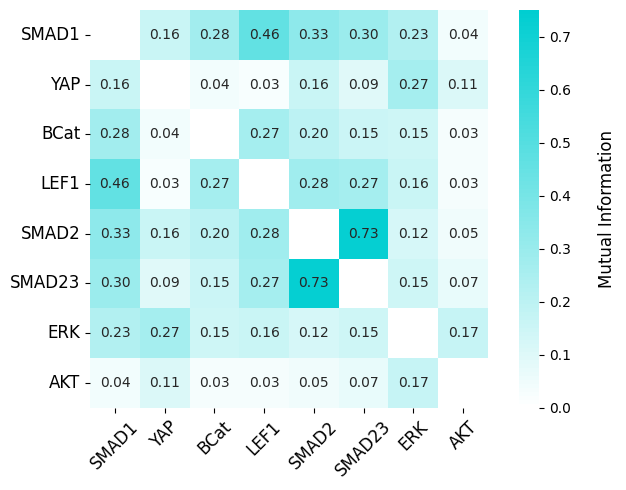

In [45]:
colors = ['white', 'darkturquoise']
n_bins = 100
fs = 12
cmap = mcolors.LinearSegmentedColormap.from_list('cyan_red', colors, N=n_bins)

plt.figure(figsize=(7, 5))

ax = sns.heatmap(MIsigs, annot=True, cmap=cmap, vmin=0, vmax=0.75, square=True, fmt='.2f')
ax.set_xticklabels(signal_names_simplified, rotation=45, fontsize=fs)
ax.set_yticklabels(signal_names_simplified, rotation=0, fontsize=fs)
cbar = ax.collections[0].colorbar
cbar.set_label('Mutual Information', rotation=90, labelpad=20, fontsize=fs)
plt.tight_layout()
os.makedirs(dataDir + '/FigS4', exist_ok=True)
plt.savefig(dataDir+"/FigS4/" + 'MI_MIheatmap' + '_sig2sig' + cond + file_suffix)


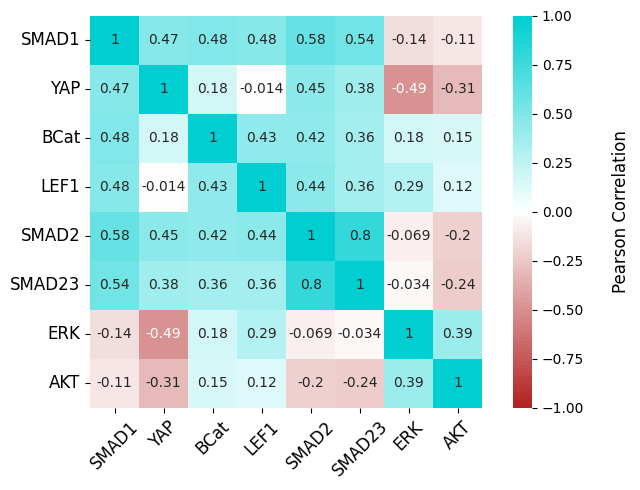

In [46]:
# correlation between signals

plt.figure(figsize=(7, 5))
sigs = data_cond[signal_names]
colors = ['firebrick', 'white', 'darkturquoise']
n_bins = 100
cmap = mcolors.LinearSegmentedColormap.from_list('cyan_red', colors, N=n_bins)


ax = sns.heatmap(sigs.corr(), annot=True, cmap=cmap, vmin=-1, vmax=1, square=True)
ax.set_xticklabels(signal_names_simplified, rotation=45, fontsize=fs)
ax.set_yticklabels(signal_names_simplified, rotation=0, fontsize=fs)
cbar = ax.collections[0].colorbar
cbar.set_label('Pearson Correlation', rotation=90, labelpad=20, fontsize=fs)
plt.tight_layout()
plt.savefig(dataDir+"/FigS4/" + 'MI_corrheatmap' + '_sig2sig' + cond + file_suffix)

In [47]:
# mutual information between signals and fate markers

N_signals = len(signal_names)
N_genes = len(gene_names)
MI = np.zeros((N_signals, N_genes))

for si in range(N_signals):
    for fj in range(N_genes):
        MI[si,fj] = fns_plot.calc_MI_sklearn(data_cond[signal_names[si]].to_numpy(), data_cond[gene_names[fj]].to_numpy())

MI = pd.DataFrame(MI, index=signal_names, columns=gene_names)
allcorr = data_cond[signal_names + gene_names].corr()

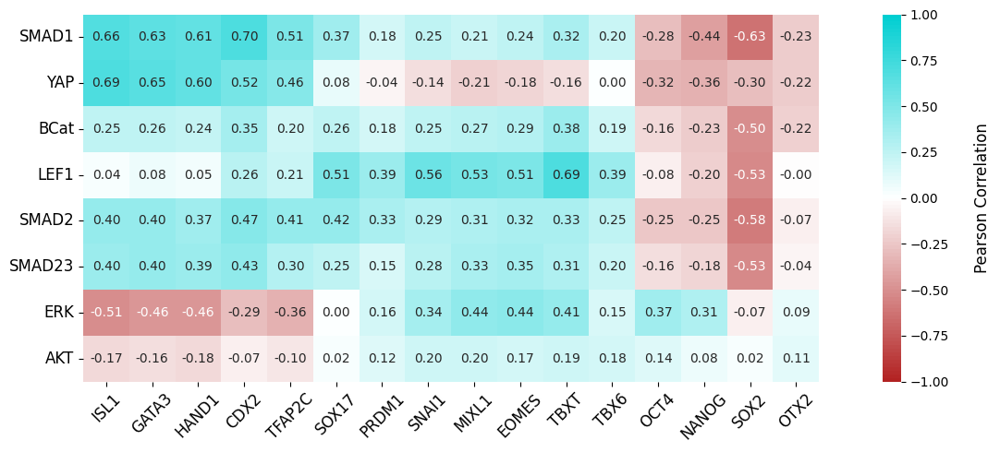

In [48]:
colors = ['firebrick','white', 'darkturquoise']
n_bins = 100
cmap = mcolors.LinearSegmentedColormap.from_list('cyan_red', colors, N=n_bins)

plt.figure(figsize=(14, 5))

ax = sns.heatmap(allcorr.loc[signal_names, gene_names], annot=True, cmap=cmap, vmin=-1, vmax=1, square=True, fmt='.2f')
ax.set_xticklabels(gene_names, rotation=45, fontsize=fs)
ax.set_yticklabels(signal_names_simplified, rotation=0, fontsize=fs)
cbar = ax.collections[0].colorbar
cbar.set_label('Pearson Correlation', rotation=90, labelpad=20, fontsize=fs)
plt.tight_layout()
plt.savefig(dataDir+"/FigS4/" + 'MI_corrheatmap' + '_sig2fate' + cond + file_suffix)

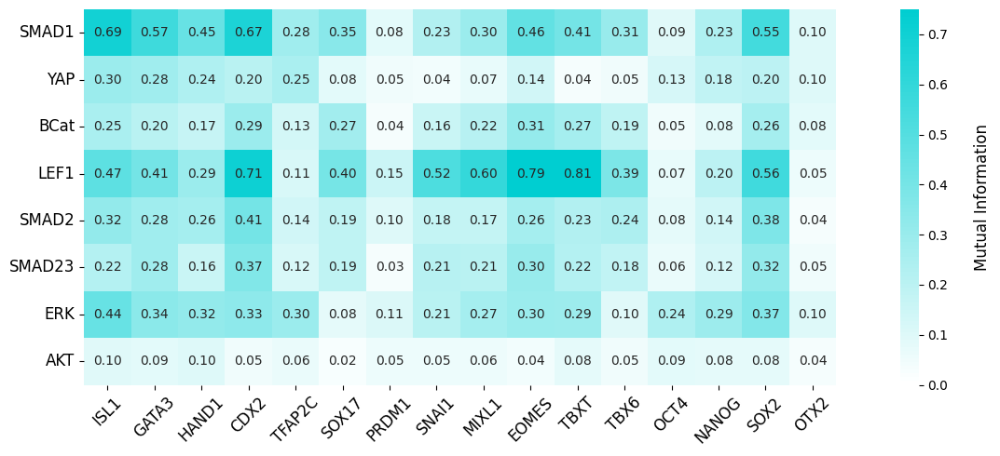

In [49]:
colors = ['white', 'darkturquoise']
n_bins = 100
cmap = mcolors.LinearSegmentedColormap.from_list('cyan_red', colors, N=n_bins)

plt.figure(figsize=(14, 5))

ax = sns.heatmap(MI, annot=True, cmap=cmap, vmin=0, vmax=0.75, square=True, fmt='.2f')
ax.set_xticklabels(gene_names, rotation=45, fontsize=fs)
ax.set_yticklabels(signal_names_simplified, rotation=0, fontsize=fs)
cbar = ax.collections[0].colorbar
cbar.set_label('Mutual Information', rotation=90, labelpad=20, fontsize=fs)
plt.tight_layout()
plt.savefig(dataDir+"/FigS4/" + 'MI_MIheatmap' + '_sig2fate' + cond + file_suffix)

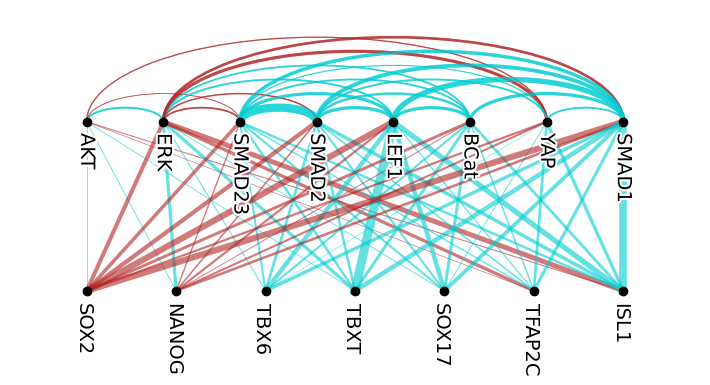

In [50]:
importlib.reload(IIF);

mygenes = ['ISL1', 'TFAP2C', 'SOX17', 'TBXT', 'TBX6', 'NANOG', 'SOX2']
fig, ax = plt.subplots(figsize=(max(len(signal_names), len(mygenes))*0.9, 4))
os.makedirs(dataDir + '/Fig3/', exist_ok=True)
IIF.plotMIgraph(dataDir + '/Fig3/', data, cond, signal_names, mygenes, signames_clean=signal_names_simplified, rotate=True, ax=ax, fs=14);

## Bar graphs of cumulative MI

In [247]:
# get unique MI in each signal (MI - MI of all signals except one)
importlib.reload(IIF);

# RUN MODEL FOR ALL SIGNALS EXCEPT ONE
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
N_run = 5
signal_combinations = [signal_names]
for n in range(len(signal_names)):
    signal_combinations.append(signal_names[:n] + signal_names[n+1:])

preds = {}
data_B50 = data[data['condition']=='B50']

for signals in signal_combinations:

    sig_str = '_'.join(sorted(signals))

    if os.path.exists(dataDir + '/Fig3_VIB/Fig3_VIB_' + sig_str + '_B50predonly_forMI.csv'):
        print(f'loading: {sig_str}')
        pred_mean_df = pd.read_csv(dataDir + '/Fig3_VIB/Fig3_VIB_' + sig_str + '_B50predonly_forMI.csv', index_col=0)

    else:
        print(f'calculating: {sig_str}')
        pred_mean_df, _ = IIF.sig2fate(data_B50, signals, gene_names, N_run, hyperparam)
        pred_mean_df.to_csv(dataDir + '/Fig3_VIB/Fig3_VIB_' + sig_str + '_B50predonly_forMI.csv')

    preds[sig_str] = pred_mean_df

# CALCULATE MI
colonies = [int(n) for n in np.unique(data_B50['Colony'])]
MI_dec = {}
genelist = mygenes

for f in genelist:

    MI_dec[f] = pd.DataFrame(np.zeros((len(preds.keys()),len(colonies))), index=preds.keys(), columns=colonies)

    for ci in colonies:
        idx = data['Colony']==ci
    
        for s in preds.keys():
            MI_dec[f].at[s,ci] = sklearn.feature_selection.mutual_info_regression(preds[s].loc[idx,f].to_numpy().reshape(-1, 1), data.loc[idx,f].to_numpy())/np.log(2)

MI_uniques = []

# GET UNIQUE PART
for f in mygenes:
    
    MI_unique = MI_dec[f].mean(axis=1).iloc[0] - MI_dec[f].mean(axis=1) 
    MI_unique = MI_unique.iloc[1:]#/MI_dec[f].std(axis=1).iloc[0]
    MI_unique[MI_unique < 0] = 0
    MI_unique.index = signal_names
    MI_unique['total'] = MI_dec[f].mean(axis=1).iloc[0]
    MI_unique = MI_unique.to_frame(name=f)
    MI_uniques.append(MI_unique)

MI_uniques = pd.concat(MI_uniques, axis=1)

calculating: BCat_LEF1_cytopAKT_cytopERK_ncSMAD2_ncSMAD23_ncYAP_pSMAD1
  Run 0/5
Elapsed time: 58.371567726135254 seconds
  Run 1/5
Elapsed time: 57.81597852706909 seconds
  Run 2/5
Elapsed time: 54.69820499420166 seconds
  Run 3/5
Elapsed time: 54.364909410476685 seconds
  Run 4/5
Elapsed time: 56.49741268157959 seconds
calculating: BCat_LEF1_cytopAKT_cytopERK_ncSMAD2_ncSMAD23_ncYAP
  Run 0/5
Elapsed time: 59.076600074768066 seconds
  Run 1/5
Elapsed time: 57.14530944824219 seconds
  Run 2/5
Elapsed time: 55.606359004974365 seconds
  Run 3/5
Elapsed time: 54.62387013435364 seconds
  Run 4/5
Elapsed time: 55.154672384262085 seconds
calculating: BCat_LEF1_cytopAKT_cytopERK_ncSMAD2_ncSMAD23_pSMAD1
  Run 0/5
Elapsed time: 56.391910791397095 seconds
  Run 1/5
Elapsed time: 56.6323516368866 seconds
  Run 2/5
Elapsed time: 55.17188310623169 seconds
  Run 3/5
Elapsed time: 56.785229444503784 seconds
  Run 4/5
Elapsed time: 57.43611264228821 seconds
calculating: LEF1_cytopAKT_cytopERK_ncSMAD2_

==========ISL1====================
rd: 1
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI//251115_VIB_1D_B50_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI//251115_VIB_1D_B50_ncYAP_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI//251115_VIB_1D_B50_LEF1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI//251115_VIB_1D_B50_BCat_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI//251115_VIB_1D_B50_ncSMAD23_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI//251115_VIB_1D_B50_ncSMAD2_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI//251115_VIB_1D_B50_cytopERK_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI//251115_VIB_1D_B50_cytopAKT_avg.csv
best mean: ('pSMAD1',), 0.70(0.05)
selected best: ('pSMAD1',), 0.70(0.05)
rd: 2
/Users/idse/data_tmp/signaldecoding/230121_da

,n_colonies,saturation_k_old,saturation_k_new,saturation_k_bootstrap,all_signals_MI,empirical_max_MI,empirical_max_k,lower_bound_at_selected_k
marker,,,,,,,,
ISL1,6,2,3,3,0.842505,0.884631,5,0.990510
GATA3,6,3,3,3,0.827500,0.850673,7,0.960679
HAND1,6,3,5,5,0.682417,0.688319,5,0.965759
CDX2,6,4,5,5,1.114465,1.114465,8,0.966219
TFAP2C,6,4,6,6,0.506387,0.519459,7,0.967395
SOX17,6,3,4,4,0.539763,0.565378,5,0.966573
PRDM1,6,3,8,8,0.309511,0.309511,8,1.000000
SNAI1,6,5,5,5,0.700491,0.700491,8,0.957939
MIXL1,6,5,6,6,0.888388,0.888388,8,0.961058


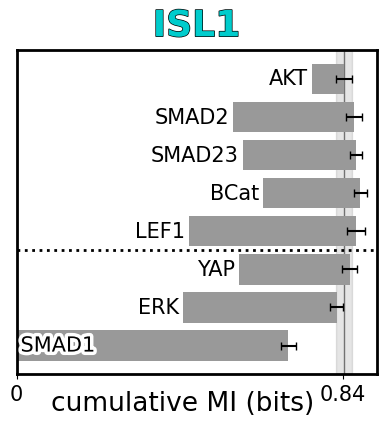

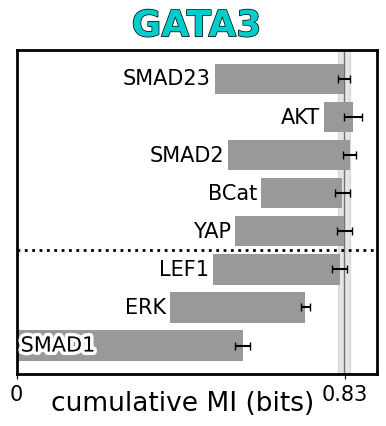

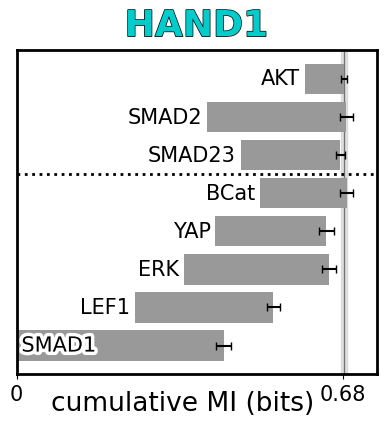

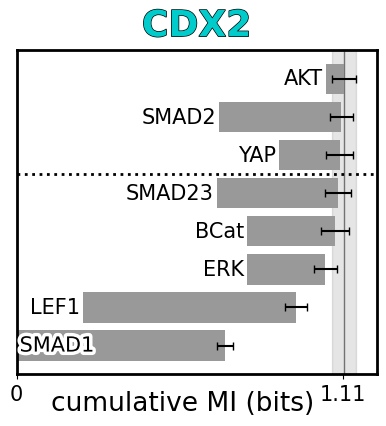

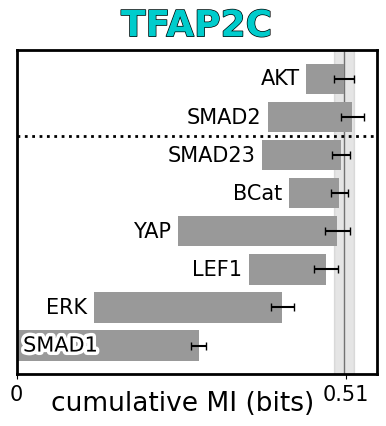

...

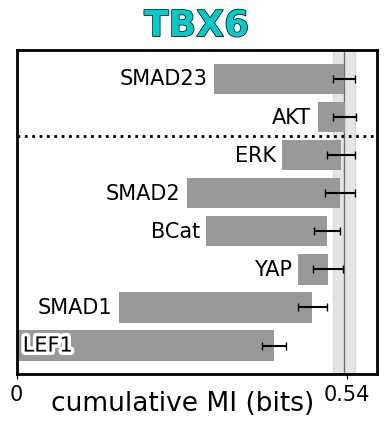

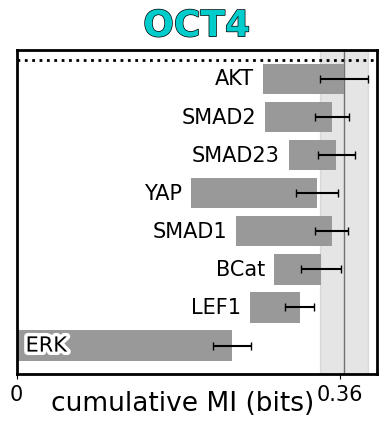

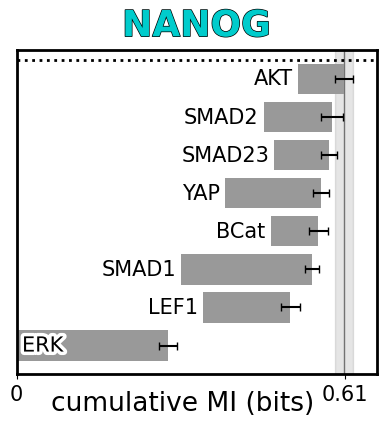

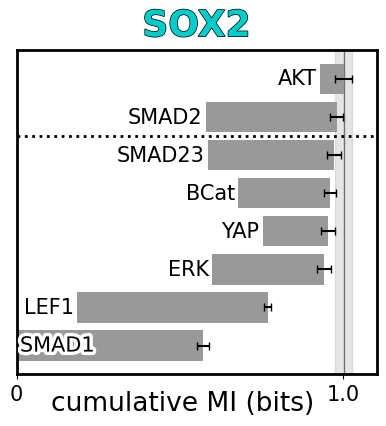

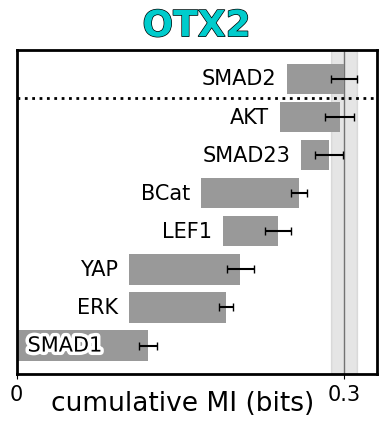

In [ ]:
importlib.reload(IIF);
N_run = 3
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
mygenes = gene_names
signals = signal_names

signals_tiebreak_order = ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK', 'cytopAKT']
signal_labels = dict(zip(signal_names, signal_names_simplified))

IIF.plotCumulativeMI(data, cond, dataDir, mygenes, signals_tiebreak_order, signal_labels, N_run, hyperparam, checkoverfit=False, show_margin_line=False, pred_cache_dir=dataDir+'/cumulativeMI/', recompute=False)

In [111]:
# STABILITY CHECK: leave-one-colony-out recomputation of the greedy signal-selection
# decisions, reusing already-computed per-candidate/per-colony MI values (no VIB
# retraining -- getPreds hits its existing cache, and only the cheap sklearn MI + t-test/
# BH-correction arithmetic is redone). Follows the REALIZED greedy path only: each round's
# candidate set is built from the ORIGINAL previously-selected signals, never from a
# hypothetical re-branched path -- this tests whether each individual decision is robust
# to dropping one colony, not where a changed decision would have led.

import statsmodels.stats.multitest

def select_from_MI_dec(MI_dec_df, colonies_subset, signals_order, alpha=0.1):
    """Reproduces getmaxDecoderMI's per-round selection rule -- argmax mean MI, provided
    it's significantly better than every other candidate by BH-corrected paired t-test
    (alpha); otherwise tie-break by earliest position in signals_order -- restricted to an
    arbitrary subset of colonies, using an already-computed candidates x colonies MI
    DataFrame (MI_dec_df) instead of refitting anything. Uses .loc[[key]].iloc[0], not
    .loc[key], since bare-tuple .loc access is unsafe on a flat (non-MultiIndex) Index of
    tuples -- pandas tries to unpack the tuple as a (row, col) selector instead of treating
    it as one row label."""
    sub = MI_dec_df[colonies_subset]
    means = sub.mean(axis=1)
    best_idx = means.idxmax()
    best_mi = sub.loc[[best_idx]].iloc[0]

    p_values = []
    for s in sub.index:
        if s == best_idx:
            continue
        current_mi = sub.loc[[s]].iloc[0]
        if not current_mi.equals(best_mi) and len(current_mi) > 1:
            _, p = sp.stats.ttest_rel(best_mi, current_mi)
            p_values.append((s, p))

    if not p_values:
        return best_idx

    indices, pvals = zip(*p_values)
    rejected, _, _, _ = statsmodels.stats.multitest.multipletests(pvals, alpha=alpha, method='fdr_bh')
    if all(rejected):
        return best_idx

    equivalent_vars = [best_idx] + [indices[i] for i, rej in enumerate(rejected) if not rej]

    def sort_key(signal_tuple):
        if not isinstance(signal_tuple, tuple):
            signal_tuple = (signal_tuple,)
        return [signals_order.index(sig) for sig in signal_tuple]

    return sorted(equivalent_vars, key=sort_key)[0]


records = []
for fatemarker in gene_names:
    print(fatemarker)
    data_cond = data[data['condition'] == cond]
    maxMI_dict = {0: {fatemarker: ((), 0)}}
    MI_dec = {}
    remaining_sigs = signals_tiebreak_order
    rd = 1

    while len(remaining_sigs) > 0:
        signal_chains = [maxMI_dict[rd - 1][fatemarker][0] + (s,) for s in remaining_sigs]
        mean_preds, _ = IIF.getPreds(data, cond, dataDir, signal_chains, fatemarker, gene_names, hyperparam, N_run, pred_cache_dir=dataDir + '/cumulativeMI')
        maxMI_dict[rd], MI_dec[rd] = IIF.getmaxDecoderMI([fatemarker], signals_tiebreak_order, mean_preds, data_cond, debug=False)

        mi_round = MI_dec[rd][fatemarker]
        colonies = list(mi_round.columns)
        original_selected = maxMI_dict[rd][fatemarker][0]

        if len(mi_round.index) > 1:  # a real decision was made this round (>1 candidate)
            for held_out in colonies:
                subset = [c for c in colonies if c != held_out]
                loo_selected = select_from_MI_dec(mi_round, subset, signals_tiebreak_order)
                records.append({
                    'marker': fatemarker, 'round': rd, 'held_out_colony': held_out,
                    'original': original_selected, 'loo': loo_selected,
                    'changed': loo_selected != original_selected,
                })

        remaining_sigs = [s for s in signals_tiebreak_order if s not in list(maxMI_dict[rd][fatemarker][0])]
        rd += 1

stability_df = pd.DataFrame(records)


ISL1
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncYAP_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_LEF1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_BCat_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncSMAD23_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncSMAD2_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_cytopERK_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_cytopAKT_avg.csv
best mean: ('pSMAD1',), 0.70(0.05)
selected best: ('pSMAD1',), 0.70(0.05)
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_2D_B50_ncYAP_p

In [112]:
# Per-marker: which steps change, and to what, under any single leave-one-colony-out recompute
changed = stability_df[stability_df['changed']]
for marker, grp in changed.groupby('marker'):
    print(f'--- {marker} ---')
    print(grp[['round', 'held_out_colony', 'original', 'loo']].to_string(index=False))

# Summary: fraction of DECISIONS (marker, round) unchanged under ALL SIX leave-one-out recomputes
decision_fragile = stability_df.groupby(['marker', 'round'])['changed'].any()
print(f'\nDecisions unchanged under all 6 LOO recomputes: {(~decision_fragile).mean():.3f} '
      f'({(~decision_fragile).sum()}/{len(decision_fragile)})')

# Which signals are involved when decisions do change
print('\nSignals appearing in a changed decision (as original pick or LOO replacement):')
print(pd.concat([changed['original'], changed['loo']]).value_counts())


--- CDX2 ---
 round  held_out_colony                                 original                                   loo
     4                1           (pSMAD1, LEF1, cytopERK, BCat)       (pSMAD1, LEF1, cytopERK, ncYAP)
     4                2           (pSMAD1, LEF1, cytopERK, BCat)       (pSMAD1, LEF1, cytopERK, ncYAP)
     4                3           (pSMAD1, LEF1, cytopERK, BCat)       (pSMAD1, LEF1, cytopERK, ncYAP)
     4                4           (pSMAD1, LEF1, cytopERK, BCat)       (pSMAD1, LEF1, cytopERK, ncYAP)
     5                2 (pSMAD1, LEF1, cytopERK, BCat, ncSMAD23) (pSMAD1, LEF1, cytopERK, BCat, ncYAP)
     5                4 (pSMAD1, LEF1, cytopERK, BCat, ncSMAD23) (pSMAD1, LEF1, cytopERK, BCat, ncYAP)
     5                6 (pSMAD1, LEF1, cytopERK, BCat, ncSMAD23) (pSMAD1, LEF1, cytopERK, BCat, ncYAP)
--- EOMES ---
 round  held_out_colony                              original                                      loo
     2                1                       

In [117]:
stability_df['original_signal'] = stability_df['original'].apply(lambda t: t[-1])
stability_df['loo_signal'] = stability_df['loo'].apply(lambda t: t[-1])

changed = stability_df[stability_df['changed']]
substitutions = changed.groupby(['original_signal', 'loo_signal']).size().sort_values(ascending=False)
print(substitutions)

original_signal  loo_signal
BCat             ncYAP         11
cytopAKT         ncSMAD23       9
cytopERK         pSMAD1         6
ncSMAD23         BCat           5
cytopAKT         ncSMAD2        5
BCat             pSMAD1         4
ncYAP            pSMAD1         4
ncSMAD23         ncYAP          3
BCat             ncSMAD2        3
ncSMAD2          ncSMAD23       2
BCat             ncSMAD23       1
ncSMAD23         ncSMAD2        1
cytopERK         cytopAKT       1
ncYAP            BCat           1
                 LEF1           1
                 cytopERK       1
                 ncSMAD2        1
LEF1             cytopERK       1
pSMAD1           BCat           1
                 ncSMAD2        1
dtype: int64


In [123]:
# STABILITY CHECK, REDUCED SIGNAL SET: same leave-one-colony-out recomputation as before,
# restricted to a candidate set of 5 signals (BCat, ncSMAD2, cytopAKT excluded) to see
# whether the previously observed instability was concentrated in those three signals.
# Only 5 of the 31 possible sub-combinations aren't already cached, so this needs a small
# amount of genuinely new VIB training (not a full retrain).

signals_reduced = ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK']

records_reduced = []
for fatemarker in gene_names:
    print(fatemarker)
    data_cond = data[data['condition'] == cond]
    maxMI_dict = {0: {fatemarker: ((), 0)}}
    MI_dec = {}
    remaining_sigs = signals_reduced
    rd = 1

    while len(remaining_sigs) > 0:
        signal_chains = [maxMI_dict[rd - 1][fatemarker][0] + (s,) for s in remaining_sigs]
        mean_preds, _ = IIF.getPreds(data, cond, dataDir, signal_chains, fatemarker, gene_names, hyperparam, N_run, pred_cache_dir=dataDir + '/cumulativeMI')
        maxMI_dict[rd], MI_dec[rd] = IIF.getmaxDecoderMI([fatemarker], signals_reduced, mean_preds, data_cond, debug=False)

        mi_round = MI_dec[rd][fatemarker]
        colonies = list(mi_round.columns)
        original_selected = maxMI_dict[rd][fatemarker][0]

        if len(mi_round.index) > 1:
            for held_out in colonies:
                subset = [c for c in colonies if c != held_out]
                loo_selected = select_from_MI_dec(mi_round, subset, signals_reduced)
                records_reduced.append({
                    'marker': fatemarker, 'round': rd, 'held_out_colony': held_out,
                    'original': original_selected, 'loo': loo_selected,
                    'changed': loo_selected != original_selected,
                })

        remaining_sigs = [s for s in signals_reduced if s not in list(maxMI_dict[rd][fatemarker][0])]
        rd += 1

stability_df_reduced = pd.DataFrame(records_reduced)

decision_fragile_reduced = stability_df_reduced.groupby(['marker', 'round'])['changed'].any()
print(f'\nReduced set -- decisions unchanged under all 6 LOO recomputes: {(~decision_fragile_reduced).mean():.3f} '
      f'({(~decision_fragile_reduced).sum()}/{len(decision_fragile_reduced)})')

changed_reduced = stability_df_reduced[stability_df_reduced['changed']]
stability_df_reduced['original_signal'] = stability_df_reduced['original'].apply(lambda t: t[-1])
stability_df_reduced['loo_signal'] = stability_df_reduced['loo'].apply(lambda t: t[-1])
changed_reduced = stability_df_reduced[stability_df_reduced['changed']]
print(changed_reduced.groupby(['original_signal', 'loo_signal']).size().sort_values(ascending=False))


ISL1
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncYAP_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_LEF1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncSMAD23_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_cytopERK_avg.csv
best mean: ('pSMAD1',), 0.70(0.05)
selected best: ('pSMAD1',), 0.70(0.05)
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_2D_B50_ncYAP_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_2D_B50_LEF1_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_2D_B50_ncSMAD23_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115

In [119]:
# EXHAUSTIVE CHECK: does any single signal, or any pair, reach the saturation margin --
# rather than relying only on the greedy path? Computes decoder MI for every subset of
# size 1 (8) and size 2 (28), plus the all-signals set, using the same VIB model,
# per-colony MI estimator, and saturation criterion (one-sided lower CI bound on
# MI_subset(colony)/MI_all(colony) vs 0.95) as the greedy cumulative-MI analysis.
# getPreds's cache is shared across markers and keyed only by signal combination (not
# order or which marker), so this reuses everything the greedy runs already computed --
# only 10 of the 28 pairs needed fresh training.

import itertools
importlib.reload(IIF) 

all_singles = list(itertools.combinations(signals_tiebreak_order, 1))
all_pairs = list(itertools.combinations(signals_tiebreak_order, 2))
full_set = [tuple(signals_tiebreak_order)]
all_combos = all_singles + all_pairs + full_set

mean_preds_all, _ = IIF.getPreds(data, cond, dataDir, all_combos, None, gene_names, hyperparam, N_run, pred_cache_dir=dataDir + '/cumulativeMI')

exhaustive_records = []
greedy_first_two = {}
exhaustive_best = {}

for fatemarker in gene_names:
    print(fatemarker)
    data_cond = data[data['condition'] == cond]

    # exhaustive per-colony MI for every single/pair/full-set candidate, one call (no
    # retraining -- mean_preds_all already has everything, this is just sklearn MI +
    # bookkeeping)
    _, MI_dec_exhaustive = IIF.getmaxDecoderMI([fatemarker], signals_tiebreak_order, mean_preds_all, data_cond, debug=False)
    mi_table = MI_dec_exhaustive[fatemarker]  # candidates (index) x colonies (columns)

    maxMIall = mi_table.loc[[full_set[0]]].iloc[0]
    n = len(maxMIall)
    t_crit = sp.stats.t.ppf(0.95, df=n - 1)

    def best_and_test(candidates):
        means = mi_table.loc[candidates].mean(axis=1)
        best = means.idxmax()
        best_mi = mi_table.loc[[best]].iloc[0]
        r = (best_mi / maxMIall).dropna()
        r_mean = r.mean()
        r_sem = r.std(ddof=1) / np.sqrt(len(r))
        lower_bound = r_mean - t_crit * r_sem
        return best, means[best], lower_bound


    best_single, best_single_mi, lb_single = best_and_test(all_singles)
    best_pair, best_pair_mi, lb_pair = best_and_test(all_pairs)

    # the actual greedy path (tiebreak-respecting), to compare against the best exhaustive
    # pair -- reruns the same greedy loop used elsewhere; all cache hits, cheap
    maxMI_dict = {0: {fatemarker: ((), 0)}}
    remaining_sigs = signals_tiebreak_order
    rd = 1
    while len(remaining_sigs) > 0 and rd <= 2:
        signal_chains = [maxMI_dict[rd - 1][fatemarker][0] + (s,) for s in remaining_sigs]
        mean_preds, _ = IIF.getPreds(data, cond, dataDir, signal_chains, fatemarker, gene_names, hyperparam, N_run, pred_cache_dir=dataDir + '/cumulativeMI')
        maxMI_dict[rd], _ = IIF.getmaxDecoderMI([fatemarker], signals_tiebreak_order, mean_preds, data_cond, debug=False)
        remaining_sigs = [s for s in signals_tiebreak_order if s not in list(maxMI_dict[rd][fatemarker][0])]
        rd += 1
    greedy_path = maxMI_dict[2][fatemarker][0]
    greedy_first_two[fatemarker] = greedy_path[:2]


    exhaustive_records.append({
        'marker': fatemarker,
        'best_single': best_single[0], 'best_single_MI': best_single_mi, 'single_lower_bound': lb_single,
        'single_reaches_margin': lb_single > 0.95,
        'best_pair': best_pair, 'best_pair_MI': best_pair_mi, 'pair_lower_bound': lb_pair,
        'pair_reaches_margin': lb_pair > 0.95,
        'pair_matches_greedy_first_two': set(best_pair) == set(greedy_path[:2]),
    })
    exhaustive_best[fatemarker] = {1: best_single_mi, 2: best_pair_mi}

exhaustive_df = pd.DataFrame(exhaustive_records).set_index('marker')
print(exhaustive_df.to_string())


/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncYAP_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_LEF1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_BCat_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncSMAD23_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncSMAD2_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_cytopERK_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_cytopAKT_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_2D_B50_ncYAP_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulati

In [122]:
# NEAR-TIE CHECK: for the 4 markers where the greedy path's round-2 pick differs from the
# best exhaustive pair, test whether the two pairs' per-colony MI are actually
# distinguishable -- same paired t-test the greedy algorithm itself uses for significance
# (alpha=0.1) -- or effectively tied, in which case the greedy tiebreak rule (not a worse
# choice) is what determined the outcome.

mismatched_markers = ['HAND1', 'SOX17', 'EOMES', 'SOX2', 'OTX2']

for fatemarker in mismatched_markers:
    data_cond = data[data['condition'] == cond]
    _, MI_dec_exhaustive = IIF.getmaxDecoderMI([fatemarker], signals_tiebreak_order, mean_preds_all, data_cond, debug=False)
    mi_table = MI_dec_exhaustive[fatemarker]

    greedy_pair = greedy_first_two[fatemarker]
    greedy_pair_key = next(p for p in all_pairs if set(p) == set(greedy_pair))
    best_pair = exhaustive_df.loc[fatemarker, 'best_pair']

    greedy_mi = mi_table.loc[[greedy_pair_key]].iloc[0]
    best_mi = mi_table.loc[[best_pair]].iloc[0]

    t_stat, p_value = sp.stats.ttest_rel(best_mi, greedy_mi)
    verdict = 'near-tie' if p_value > 0.1 else 'significantly different'
    print(f'{fatemarker}: greedy pair {greedy_pair_key} (mean MI {greedy_mi.mean():.3f}) vs '
          f'best pair {best_pair} (mean MI {best_mi.mean():.3f}) -- paired t p={p_value:.3f} ({verdict})')


best mean: ('pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK', 'cytopAKT'), 0.68(0.02)
selected best: ('pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK', 'cytopAKT'), 0.68(0.02)
HAND1: greedy pair ('pSMAD1', 'LEF1') (mean MI 0.535) vs best pair ('LEF1', 'cytopERK') (mean MI 0.565) -- paired t p=0.259 (near-tie)
best mean: ('pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK', 'cytopAKT'), 0.54(0.06)
selected best: [('pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK', 'cytopAKT'), ('pSMAD1', 'BCat')]
SOX17: greedy pair ('pSMAD1', 'LEF1') (mean MI 0.510) vs best pair ('pSMAD1', 'BCat') (mean MI 0.515) -- paired t p=0.843 (near-tie)
best mean: ('pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK', 'cytopAKT'), 1.11(0.04)
selected best: ('pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK', 'cytopAKT'), 1.11(0.04)
EOMES: greedy pair ('ncYAP', 'LEF1') (mean MI 0.922) vs best pair ('LEF1',

==========ISL1====================
rd: 1
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncYAP_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_LEF1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_BCat_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncSMAD23_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncSMAD2_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_cytopERK_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_cytopAKT_avg.csv
best mean: ('pSMAD1',), 0.70(0.05)
selected best: ('pSMAD1',), 0.70(0.05)
rd: 2
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdo

,n_colonies,saturation_k_old,saturation_k_new,saturation_k_bootstrap,all_signals_MI,empirical_max_MI,empirical_max_k,lower_bound_at_selected_k
marker,,,,,,,,
ISL1,6,2,3,3,0.842504,0.884633,5,0.990509
GATA3,6,3,3,3,0.827500,0.850673,7,0.960680
HAND1,6,3,5,5,0.682416,0.688318,5,0.965757
CDX2,6,4,5,5,1.114466,1.114466,8,0.966217
TFAP2C,6,4,6,6,0.506386,0.519459,7,0.967402
SOX17,6,3,4,4,0.539763,0.565378,5,0.966575
PRDM1,6,3,8,8,0.309511,0.309511,8,1.000000
SNAI1,6,5,5,5,0.700489,0.700489,8,0.957939
MIXL1,6,5,6,6,0.888388,0.888388,8,0.961055


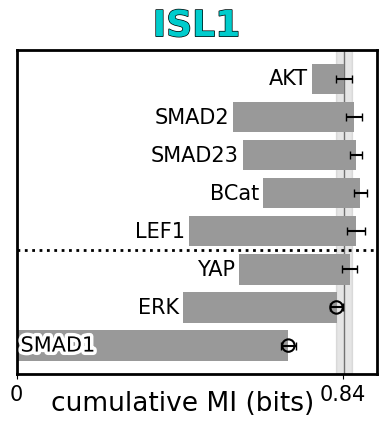

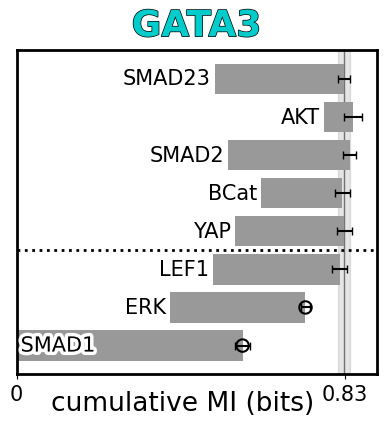

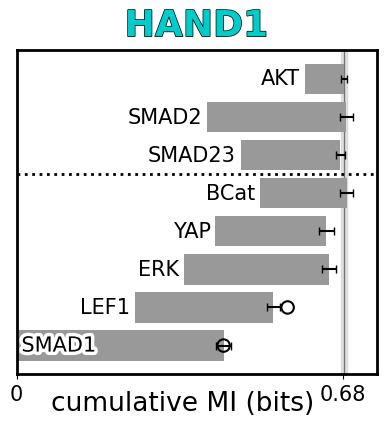

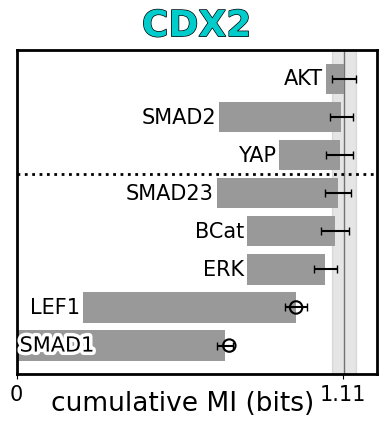

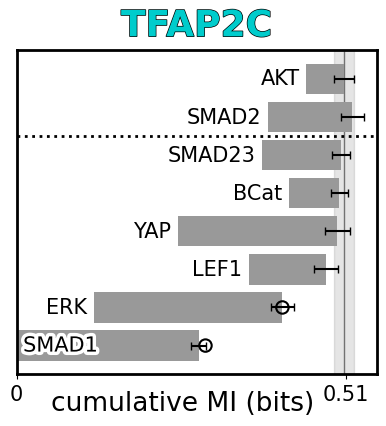

...

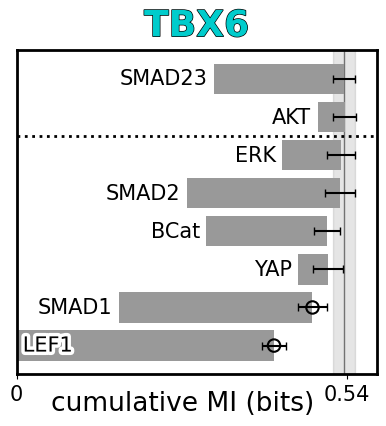

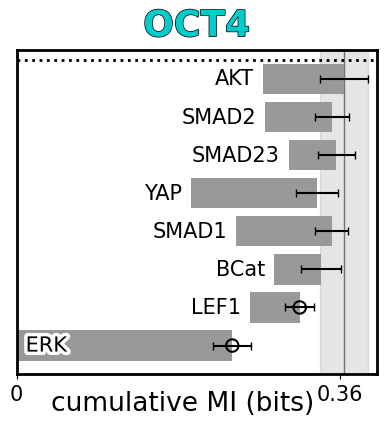

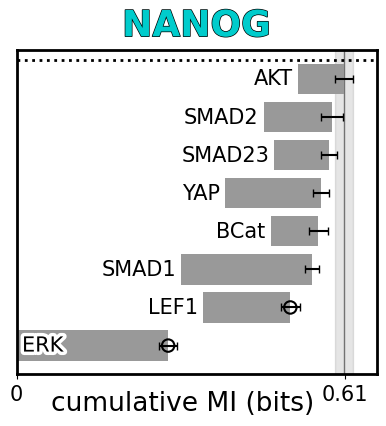

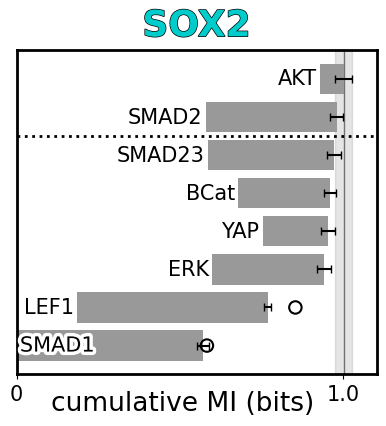

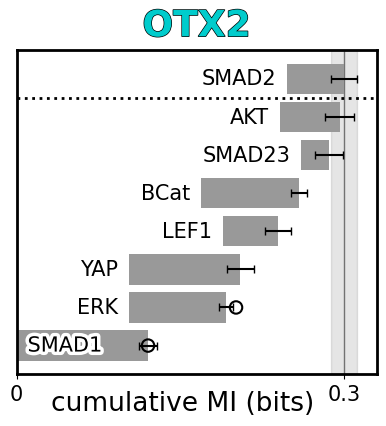

In [344]:
importlib.reload(IIF)
IIF.plotCumulativeMI(data, cond, dataDir, mygenes, signals_tiebreak_order, signal_labels, N_run, hyperparam,
                      checkoverfit=False, show_margin_line=False, exhaustive_best=exhaustive_best, pred_cache_dir=dataDir + '/cumulativeMI')

==========ISL1====================
rd: 1
250509_Exp20/251115_VIB_1D_B50_pSMAD1_avg.csv
250509_Exp20/251115_VIB_1D_B50_ncYAP_avg.csv
250509_Exp20/251115_VIB_1D_B50_BCat_avg.csv
250509_Exp20/251115_VIB_1D_B50_LEF1_avg.csv
250509_Exp20/251115_VIB_1D_B50_ncSMAD2_avg.csv
250509_Exp20/251115_VIB_1D_B50_ncSMAD23_avg.csv
250509_Exp20/251115_VIB_1D_B50_cytopERK_avg.csv
250509_Exp20/251115_VIB_1D_B50_cytopAKT_avg.csv
best mean: ('pSMAD1',), 0.66(0.04)
selected best: ('pSMAD1',), 0.66(0.04)
rd: 2
250509_Exp20/251115_VIB_2D_B50_ncYAP_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_BCat_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_LEF1_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_ncSMAD2_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_ncSMAD23_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_cytopERK_pSMAD1_avg.csv
250509_Exp20/251115_VIB_2D_B50_cytopAKT_pSMAD1_avg.csv
best mean: ('pSMAD1', 'cytopERK'), 0.78(0.05)
selected best: ('pSMAD1', 'cytopERK'), 0.78(0.05)
rd: 3
250509_Exp20/251115_VIB_3D_B50_cyt

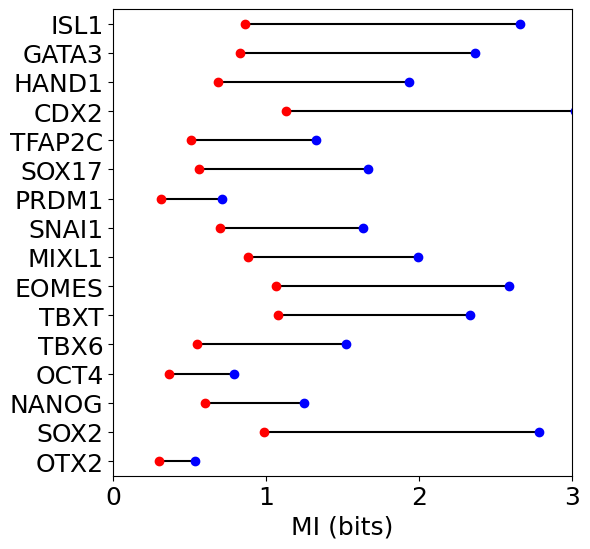

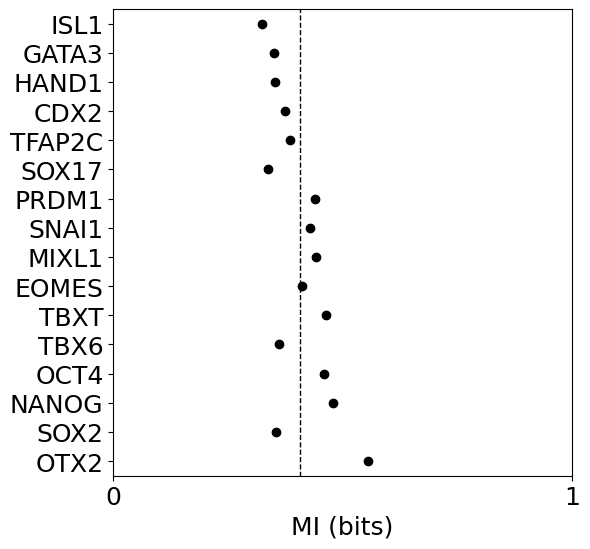

In [25]:
# FOR SI FIGURE
N_run = 3
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
mygenes = gene_names
signals = signal_names

MI_dec = IIF.plotRedundantMI(dataDir, data, cond, mygenes, signals, N_run, hyperparam)

### Seed stability of cumulative MI

In [150]:
# gather the combos needed and train per-seed (parallel):
# Unique combinations needed: every prefix of each marker's established (ensemble,
# n_neighbors=3) greedy path -- reuses sensitivity_results already computed, no new
# combinations beyond what each marker's own reported ordering actually uses.

importlib.reload(IIF)

established_paths = {fatemarker: sensitivity_results[3][fatemarker]['order'] for fatemarker in gene_names}

all_prefix_combos = set()
for order in established_paths.values():
    for k in range(1, len(order) + 1):
        all_prefix_combos.add(order[:k])
all_prefix_combos = list(all_prefix_combos)
print(f'{len(all_prefix_combos)} unique combinations needed')

N_run = 3
per_seed_preds = IIF.getPredsPerSeed(data, cond, dataDir, all_prefix_combos, gene_names, hyperparam, N_run,
                                      pred_cache_dir=dataDir + '/cumulativeMI', recompute=True)

87 unique combinations needed
running per-seed: ('LEF1', 'pSMAD1', 'ncYAP', 'BCat', 'ncSMAD2', 'cytopERK')
  Run 0/3
Elapsed time: 19.39049792289734 seconds
  Run 1/3
Elapsed time: 19.23202085494995 seconds
  Run 2/3
Elapsed time: 19.169875144958496 seconds
running per-seed: ('LEF1', 'cytopERK', 'pSMAD1', 'ncYAP', 'ncSMAD23')
  Run 0/3
Elapsed time: 19.151277780532837 seconds
  Run 1/3
Elapsed time: 19.13182806968689 seconds
  Run 2/3
Elapsed time: 19.09021306037903 seconds
running per-seed: ('pSMAD1', 'cytopERK', 'ncYAP', 'LEF1')
  Run 0/3
Elapsed time: 18.480649948120117 seconds
  Run 1/3
Elapsed time: 18.583534240722656 seconds
  Run 2/3
Elapsed time: 19.28195095062256 seconds
running per-seed: ('pSMAD1', 'cytopERK', 'LEF1', 'ncYAP', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopAKT')
  Run 0/3
Elapsed time: 26.92298698425293 seconds
  Run 1/3
Elapsed time: 24.21347713470459 seconds
  Run 2/3
Elapsed time: 17.145302057266235 seconds
running per-seed: ('LEF1', 'pSMAD1', 'ncYAP', 'BCat')
  Run

In [151]:
#compute per-seed and ensemble MI, build the report table:
data_cond = data[data['condition'] == cond]

# reorganize {combo: {seed: df}} -> {seed: {combo: df}} so getmaxDecoderMI (same MI code
# path as the rest of the analysis, n_neighbors=3 matching main settings) can compute MI
# for every marker x combo at once, per seed
preds_by_seed = {it: {combo: per_seed_preds[combo][it] for combo in all_prefix_combos} for it in range(N_run)}

seed_MI_dec = {}
for it in range(N_run):
    _, seed_MI_dec[it] = IIF.getmaxDecoderMI(gene_names, signals_tiebreak_order, preds_by_seed[it], data_cond, debug=False, n_neighbors=3)

# ensemble (averaged) MI at the same combinations, for comparison -- cache hit, no retraining
mean_preds_ens, _ = IIF.getPreds(data, cond, dataDir, all_prefix_combos, None, gene_names, hyperparam, N_run, pred_cache_dir=dataDir + '/cumulativeMI')
_, MI_dec_ensemble = IIF.getmaxDecoderMI(gene_names, signals_tiebreak_order, mean_preds_ens, data_cond, debug=False, n_neighbors=3)

per_seed_mi_records = []
for fatemarker in gene_names:
    order = established_paths[fatemarker]
    ens_means = MI_dec_ensemble[fatemarker].mean(axis=1)
    for k in range(1, len(order) + 1):
        combo = order[:k]
        seed_vals = [seed_MI_dec[it][fatemarker].loc[[combo]].iloc[0].mean() for it in range(N_run)]
        ensemble_val = ens_means.loc[[combo]].iloc[0]
        per_seed_mi_records.append({
            'marker': fatemarker, 'round': k,
            **{f'seed{it}_MI': seed_vals[it] for it in range(N_run)},
            'seed_mean_MI': np.mean(seed_vals),
            'seed_std_MI': np.std(seed_vals),
            'ensemble_MI': ensemble_val,
        })

per_seed_mi_df = pd.DataFrame(per_seed_mi_records)
print(per_seed_mi_df.to_string())


best mean: ('LEF1', 'cytopERK', 'pSMAD1', 'ncSMAD2'), 0.86(0.04)
selected best: [('pSMAD1', 'LEF1', 'ncYAP'), ('pSMAD1', 'LEF1', 'ncYAP', 'BCat', 'ncSMAD2', 'ncSMAD23', 'cytopERK'), ('pSMAD1', 'LEF1', 'cytopERK'), ('pSMAD1', 'LEF1', 'cytopERK', 'ncYAP'), ('pSMAD1', 'LEF1', 'cytopERK', 'ncYAP', 'BCat'), ('pSMAD1', 'LEF1', 'cytopERK', 'ncYAP', 'BCat', 'ncSMAD23'), ('pSMAD1', 'LEF1', 'cytopERK', 'ncYAP', 'BCat', 'ncSMAD23', 'ncSMAD2'), ('pSMAD1', 'LEF1', 'cytopERK', 'BCat'), ('pSMAD1', 'LEF1', 'cytopERK', 'BCat', 'ncSMAD23'), ('pSMAD1', 'LEF1', 'cytopERK', 'BCat', 'ncSMAD23', 'ncYAP'), ('pSMAD1', 'LEF1', 'cytopERK', 'BCat', 'ncSMAD23', 'ncYAP', 'ncSMAD2'), ('pSMAD1', 'cytopERK'), ('pSMAD1', 'cytopERK', 'ncYAP', 'LEF1'), ('pSMAD1', 'cytopERK', 'ncYAP', 'LEF1', 'BCat'), ('pSMAD1', 'cytopERK', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23'), ('pSMAD1', 'cytopERK', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2'), ('pSMAD1', 'cytopERK', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'cytopAKT'), ('pSMAD1', 'cytopE

In [155]:
#  the summary (how much lower is single-seed MI than the ensemble):
per_seed_mi_df['gap'] = per_seed_mi_df['ensemble_MI'] - per_seed_mi_df['seed_mean_MI']
print(f"Mean seed MI is on average {per_seed_mi_df['gap'].mean():.4f} bits lower than the ensemble MI")
print(f"as a fraction of ensemble MI: {(per_seed_mi_df['gap'] / per_seed_mi_df['ensemble_MI']).mean()*100:.1f}%")

Mean seed MI is on average 0.0154 bits lower than the ensemble MI
as a fraction of ensemble MI: 2.3%


### Check robustness of MI estimates

In [126]:
# ROBUSTNESS CHECK 1: estimator sensitivity to mutual_info_regression's n_neighbors.
# Recomputes the full greedy search + saturation point at n_neighbors = 3 (current
# default), 5, and 10, reusing the already-cached held-out predictions (getPreds hits
# cache only -- no VIB retraining, this only changes the downstream MI estimator). Reports
# per marker whether the saturation point or the greedy signal ordering changes.

n_neighbors_values = [3, 5, 10]
sensitivity_results = {}

for n_neighbors in n_neighbors_values:
    sensitivity_results[n_neighbors] = {}
    for fatemarker in gene_names:
        print(f'n_neighbors={n_neighbors}, {fatemarker}')
        data_cond = data[data['condition'] == cond]
        maxMI_dict = {0: {fatemarker: ((), 0)}}
        remaining_sigs = signals_tiebreak_order
        rd = 1
        while len(remaining_sigs) > 0:
            signal_chains = [maxMI_dict[rd - 1][fatemarker][0] + (s,) for s in remaining_sigs]
            mean_preds, _ = IIF.getPreds(data, cond, dataDir, signal_chains, fatemarker, gene_names, hyperparam, N_run, pred_cache_dir=dataDir + '/cumulativeMI')
            maxMI_dict[rd], _ = IIF.getmaxDecoderMI([fatemarker], signals_tiebreak_order, mean_preds, data_cond, debug=False, n_neighbors=n_neighbors)
            remaining_sigs = [s for s in signals_tiebreak_order if s not in list(maxMI_dict[rd][fatemarker][0])]
            rd += 1

        N_signals = len(signals_tiebreak_order)
        signals_ordered = tuple(maxMI_dict[N_signals][fatemarker][0])
        maxMIall = maxMI_dict[N_signals][fatemarker][1]

        # same saturation formula as plotCumulativeMI's kcutoff_new
        kcutoff_new = None
        for k in range(N_signals):
            maxMIthisrd = maxMI_dict[k + 1][fatemarker][1]
            r_k = (maxMIthisrd / maxMIall).dropna()
            n = len(r_k)
            r_mean = r_k.mean()
            r_sem = r_k.std(ddof=1) / np.sqrt(n)
            t_crit = sp.stats.t.ppf(0.95, df=n - 1)
            if kcutoff_new is None and (r_mean - t_crit * r_sem) > 0.95:
                kcutoff_new = k + 1
        if kcutoff_new is None:
            kcutoff_new = N_signals

        sensitivity_results[n_neighbors][fatemarker] = {'order': signals_ordered, 'saturation_k': kcutoff_new}

sensitivity_records = []
for fatemarker in gene_names:
    orders = {nn: sensitivity_results[nn][fatemarker]['order'] for nn in n_neighbors_values}
    sats = {nn: sensitivity_results[nn][fatemarker]['saturation_k'] for nn in n_neighbors_values}
    sensitivity_records.append({
        'marker': fatemarker,
        'order_changes': len(set(orders.values())) > 1,
        'saturation_changes': len(set(sats.values())) > 1,
        **{f'saturation_k_nn{nn}': sats[nn] for nn in n_neighbors_values},
    })
sensitivity_df = pd.DataFrame(sensitivity_records).set_index('marker')
print(sensitivity_df.to_string())


n_neighbors=3, ISL1
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncYAP_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_LEF1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_BCat_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncSMAD23_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_ncSMAD2_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_cytopERK_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_1D_B50_cytopAKT_avg.csv
best mean: ('pSMAD1',), 0.70(0.05)
selected best: ('pSMAD1',), 0.70(0.05)
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB

In [128]:
# Pull the actual reordered sequences for markers where order_changes=True, and check
# specifically whether the first one or two picks move (not just later positions) --
# reuses sensitivity_results already computed, no recomputation needed.

for fatemarker in gene_names:
    orders = {nn: sensitivity_results[nn][fatemarker]['order'] for nn in n_neighbors_values}
    if len(set(orders.values())) > 1:
        first_two = {nn: orders[nn][:2] for nn in n_neighbors_values}
        first_two_changed = len(set(first_two.values())) > 1
        print(f'--- {fatemarker} --- first two picks change: {first_two_changed}')
        for nn in n_neighbors_values:
            print(f'  n_neighbors={nn}: {orders[nn]}')
        print()


--- GATA3 --- first two picks change: False
  n_neighbors=3: ('pSMAD1', 'cytopERK', 'LEF1', 'ncYAP', 'BCat', 'ncSMAD2', 'cytopAKT', 'ncSMAD23')
  n_neighbors=5: ('pSMAD1', 'cytopERK', 'LEF1', 'ncYAP', 'BCat', 'ncSMAD2', 'ncSMAD23', 'cytopAKT')
  n_neighbors=10: ('pSMAD1', 'cytopERK', 'LEF1', 'ncYAP', 'BCat', 'ncSMAD23', 'cytopAKT', 'ncSMAD2')

--- HAND1 --- first two picks change: True
  n_neighbors=3: ('pSMAD1', 'LEF1', 'cytopERK', 'ncYAP', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopAKT')
  n_neighbors=5: ('pSMAD1', 'LEF1', 'cytopERK', 'ncYAP', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopAKT')
  n_neighbors=10: ('pSMAD1', 'cytopERK', 'LEF1', 'ncYAP', 'BCat', 'ncSMAD2', 'ncSMAD23', 'cytopAKT')

--- CDX2 --- first two picks change: False
  n_neighbors=3: ('pSMAD1', 'LEF1', 'cytopERK', 'BCat', 'ncSMAD23', 'ncYAP', 'ncSMAD2', 'cytopAKT')
  n_neighbors=5: ('pSMAD1', 'LEF1', 'cytopERK', 'ncYAP', 'BCat', 'ncSMAD2', 'ncSMAD23', 'cytopAKT')
  n_neighbors=10: ('pSMAD1', 'LEF1', 'cytopERK', 'BCat', 'ncSMAD2'

In [127]:
# ROBUSTNESS CHECK 2: finite-sample bias / estimator floor. Under permutation, the
# predictions carry no real information about the (shuffled) measured values, so true MI
# is exactly 0 -- any MI the estimator still reports under permutation is pure finite-
# sample bias, giving its floor. Computed per colony (matching how the real MI is
# computed), using the already-cached all-signals predictions -- no retraining. Reports
# each marker's real (all-signals) MI alongside the permuted floor's mean and spread.

N_PERMUTE = 100
rng_perm = np.random.default_rng(0)
full_combo = tuple(signals_tiebreak_order)

permutation_records = []
for fatemarker in gene_names:
    print(fatemarker)
    data_cond = data[data['condition'] == cond]
    mean_preds, _ = IIF.getPreds(data, cond, dataDir, [full_combo], fatemarker, gene_names, hyperparam, N_run, pred_cache_dir=dataDir + '/cumulativeMI')
    pred_df = mean_preds[full_combo]

    real_mis = []
    permuted_mis = []
    for ci in np.unique(data_cond['Colony']):
        idx = data_cond['Colony'] == ci
        pred_vals = pred_df.loc[idx, fatemarker].to_numpy().reshape(-1, 1)
        true_vals = data_cond.loc[idx, fatemarker].to_numpy()

        real_mis.append(sklearn.feature_selection.mutual_info_regression(pred_vals, true_vals)[0] / np.log(2))
        for _ in range(N_PERMUTE):
            shuffled = rng_perm.permutation(true_vals)
            permuted_mis.append(sklearn.feature_selection.mutual_info_regression(pred_vals, shuffled)[0] / np.log(2))

    permutation_records.append({
        'marker': fatemarker,
        'real_MI_mean': np.mean(real_mis),
        'permuted_MI_floor_mean': np.mean(permuted_mis),
        'permuted_MI_floor_std': np.std(permuted_mis),
    })

permutation_df = pd.DataFrame(permutation_records).set_index('marker')
print(permutation_df.to_string())


ISL1
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_8D_B50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_avg.csv
GATA3
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_8D_B50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_avg.csv
HAND1
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_8D_B50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_avg.csv
CDX2
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_8D_B50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_avg.csv
TFAP2C
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_8D_B50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_avg.csv
SOX17
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/cumulativeMI/251115_VIB_8D_B50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_avg.csv
PRDM1
/Users/idse/data_tmp/signaldecoding

### Visualization of signals and fate

In [236]:
# CONVERT DATA INTO EXPERIMENT AND COLONY OBJECTS
col = dict();
for colID in np.unique(data['Colony']):
    col[colID] = IIF.Colony(data[data['Colony']==colID], colID, meta, features=feature_names, nominalRadius=350);
    col[colID].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col[colID].calcPosError(sigma=1)

exp = IIF.MPexperiment(col, meta);
exp.calcRadialProfiles(cellsPerBin=100, overlap=0)

B50, Nbins = 304
B200, Nbins = 288
B10, Nbins = 252


In [243]:
percentiles = {'pSMAD1': [50, 99],
 'YAP': [10, 99.9],
 'BCat': [1, 99],
 'LEF1': [1, 99],
 'SMAD23': [1, 99],
 'pERK': [5, 99],
 'pAKT': [10, 99],
 'SMAD2': [1, 99],
 'ISL1': [90, 99.6],
 'GATA3': [1, 99],
 'HAND1': [1, 99],
 'CDX2': [1, 99],
 'TFAP2C': [1, 99],
 'SOX17': [1, 99],
 'PRDM1': [90, 99.5],
 'SNAI1': [1, 99],
 'MIXL1': [1, 99],
 'EOMES': [1, 99],
 'TBXT': [1, 99],
 'TBX6': [70, 99],
 'OCT4': [1, 99],
 'NANOG': [40, 99],
 'SOX2': [1, 99],
 'OTX2': [1, 99],
 'DAPI': [1, 99]}

loading 250509_Exp20\230112_6i9rd_exp20_RD3_ISL1_TBXT_pSMAD1\MIP\stitched_MIP_p0000_w0003_t0000.jpg
loading 250509_Exp20\230113_6i9rd_exp20_RD4_EOMES_YAP_FOXA2bad\MIP\stitched_MIP_p0000_w0002_t0000.jpg
loading 250509_Exp20\230115_6i9rd_exp20_RD6_BCat_TBX6_SMAD2\MIP\stitched_MIP_p0000_w0001_t0000.jpg
loading 250509_Exp20\230111_6i9rd_exp20_RD2_GATA3_OTX2_LEF1\MIP\stitched_MIP_p0000_w0003_t0000.jpg
loading 250509_Exp20\230115_6i9rd_exp20_RD6_BCat_TBX6_SMAD2\MIP\stitched_MIP_p0000_w0003_t0000.jpg
loading 250509_Exp20\230110_6i9rd_exp20_RD1_SMAD23_pAKT_SOX17\MIP\stitched_MIP_p0000_w0001_t0000.jpg
loading 250509_Exp20\230120_6i9rd_exp20_RD10_FOXA2m_pERK_FOXA2\MIP\stitched_MIP_p0000_w0002_t0000.jpg
loading 250509_Exp20\230110_6i9rd_exp20_RD1_SMAD23_pAKT_SOX17\MIP\stitched_MIP_p0000_w0002_t0000.jpg
loading overlay 250509_Exp20\230112_6i9rd_exp20_RD3_ISL1_TBXT_pSMAD1\MIP\stitched_MIP_p0000_w0001_t0000.jpg


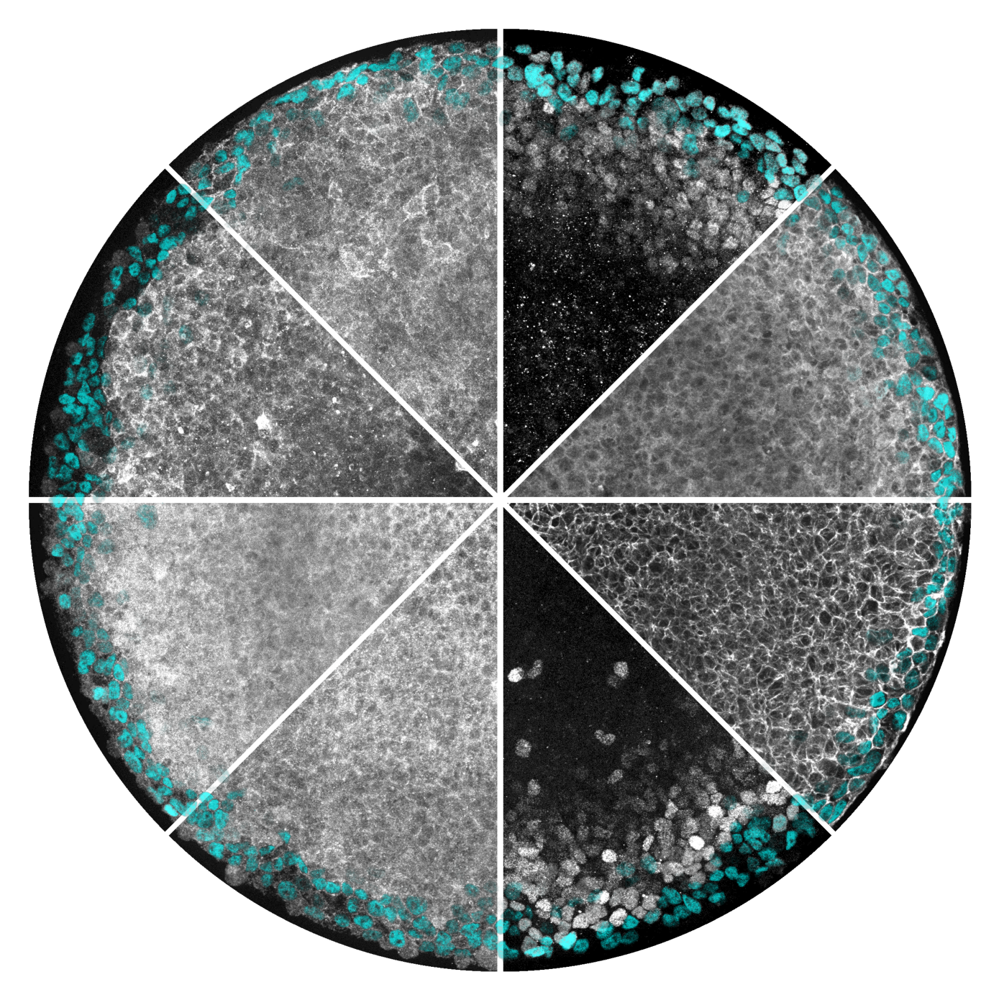

In [257]:
# example channel overlay

colID = 1
stains = signal_names_images
#stains = ['NANOG']


RGBbase, image_meta = IIF.makeRGBbase(
    col, colID, stains, dataDir,
    crop_margin=30, center_x_margin=-20, center_y_margin=10,
    Ilim=None, percentiles=percentiles,
    pie_sectors=True, grayscale_background=True, rdStr='RD'
)


overlay_markers = ['ISL1']
for ov in overlay_markers:
    RGBoverlay = IIF.applyOverlay(RGBbase, image_meta, overlay_marker=ov, overlay_alpha=0.7)

    fig, ax = plt.subplots(1, 1, figsize=(14, 14))
    ax.imshow(RGBoverlay)
    ax.axis('off')
    ax.set_aspect('equal', adjustable='box')
    plt.tight_layout()
    imageio.imwrite(f'Fig3/eight_way_pie_plot_plus_{ov}_cyan.png', RGBoverlay)
    plt.show()

## Reducing the number of signals

#### pSMAD1 only

In [88]:
signal_combinations = [
    ['pSMAD1'],
    ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK', 'cytopAKT'],
]
legend_str = ['pSMAD1', 'all signals']

data_b50 = data[data['condition'] == 'B50']
recompute = False   # set True to force retraining even if a run's CSV already exists

pred_subs = {}
for sig_combo in signal_combinations:
    sig_str = '_'.join(sorted(sig_combo, key=str.lower))
    out_prefix = f'selfB50_{sig_str}'
    IIF.run_vib_self(data_b50, sig_combo, gene_names, hyperparam, N_run=N_run,
                      out_dir=dataDir + '/VIB_self', out_prefix=out_prefix,
                      recompute=recompute, label=out_prefix)
    pred_subs[sig_str] = IIF.load_vib_self(data_b50, sig_combo, gene_names, hyperparam, N_run=N_run,
                                            out_dir=dataDir + '/VIB_self', out_prefix=out_prefix,
                                            label=out_prefix)

# CALCULATE PERFORMANCE
performances, _ = IIF.calcPerformance(data_b50, pred_subs, thresh, gene_names)

[selfB50_pSMAD1] Run 0/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/VIB_self/selfB50_pSMAD1_run0.csv
[selfB50_pSMAD1] Run 1/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/VIB_self/selfB50_pSMAD1_run1.csv
[selfB50_pSMAD1] Run 2/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/VIB_self/selfB50_pSMAD1_run2.csv
[selfB50_pSMAD1] Run 0/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/VIB_self/selfB50_pSMAD1_run0.csv
[selfB50_pSMAD1] Run 1/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/VIB_self/selfB50_pSMAD1_run1.csv
[selfB50_pSMAD1] Run 2/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/VIB_self/selfB50_pSMAD1_run2.csv
[selfB50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1] Run 0/3 -- already exists, skipping load: /Users/idse/da

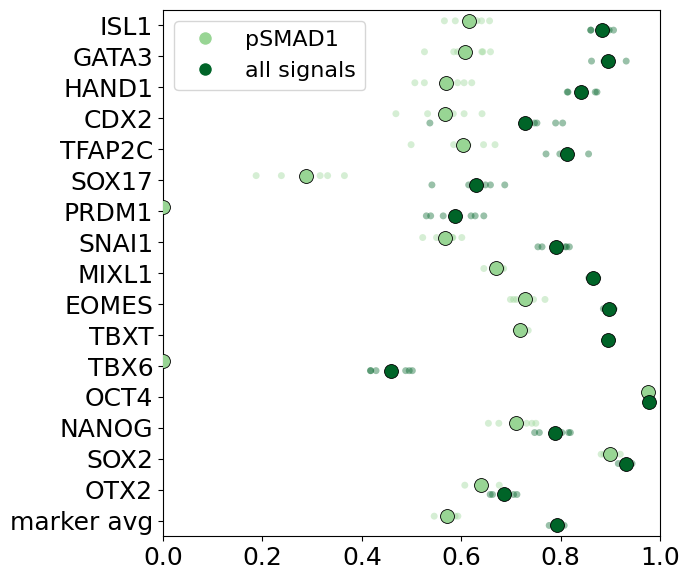

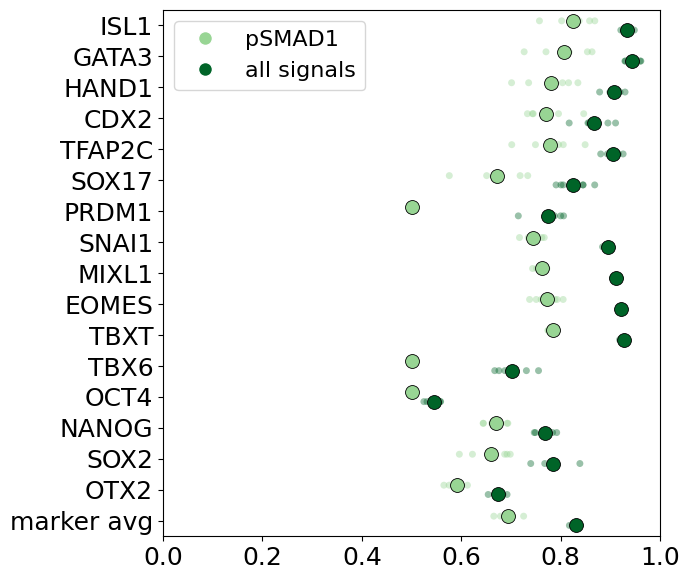

In [89]:
# plot f1 and balanced accuracy per gene, per fold (colony) -- individual colonies as
# dots, matching the per-fold comparison style used throughout fig2n, instead of
# calcPerformance's single mean+std point per combination. Uses balanced accuracy
# instead of calcPerformance's plain accuracy (compute_marker_performance_perfold
# doesn't compute plain accuracy) -- matches fig2n's established convention.

cond = 'B50'
colors = plt.cm.Greens(np.linspace(0.4, 0.9, len(pred_subs)))

marker_labels = gene_names + ['marker_avg']
marker_dfs = {}
for k in pred_subs.keys():
    df = IIF.compute_marker_performance_perfold(data_b50, pred_subs[k]['avg'], data_b50['Colony'].to_numpy(), gene_names, thresh)
    marker_dfs[k] = IIF.add_group_avg(df, ['f1', 'balanced_accuracy'], group_col='gene')

for score in ['f1', 'balanced_accuracy']:
    IIF.plot_perfold_comparison(
        series=[(marker_dfs[k], score, c) for k, c in zip(pred_subs.keys(), colors)],
        group_col='gene', labels=marker_labels,
        fname=dataDir + f'/FigS5/nosmad1_marker_{score}_perfold.png',
        legend_labels=legend_str, tick_labels=gene_names + ['marker avg'])

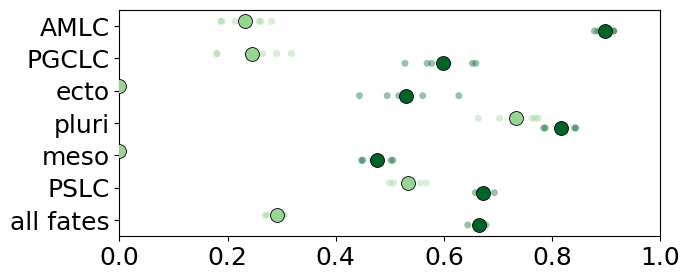

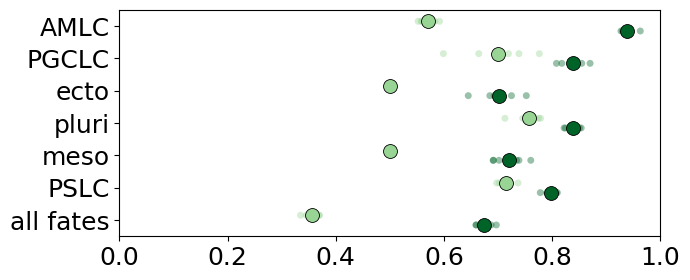

In [90]:
# plot fate-level f1 and balanced accuracy per fold (colony), individual colonies as dots

def fate_perfold_all(data_cond, pred_sub, colonies, thresh):
    """Per-fold (colony) F1 and balanced accuracy for every fate category, plus an
    'all fates' aggregate row (built into compute_category_performance_perfold via its
    aggregate_name argument). Cells called 'other' (fitting no defined fate) are excluded
    from scoring. pred_sub is restricted to data_cond's index first, since prediction
    dicts can cover a wider row set than the specific condition/filter being scored here."""
    pred_sub = pred_sub.loc[data_cond.index]
    fates_true_all, fate_names_raw = IIF.return_fates(data_cond, thresh=thresh)
    fate_names_list = [f for f in fate_names_raw if f != 'other']
    keep = fates_true_all != 'other'
    fates_true = fates_true_all[keep]
    fates_pred_all, _ = IIF.return_fates(pred_sub, thresh=thresh)
    fates_pred = fates_pred_all[keep]
    df = pd.DataFrame(IIF.compute_category_performance_perfold(
        fates_true, fates_pred, colonies[keep], fate_names_list, aggregate_name='all fates'))
    return df

fate_dfs = {k: fate_perfold_all(data_b50, pred_subs[k]['avg'], data_b50['Colony'].to_numpy(), thresh) for k in pred_subs.keys()}

_, fate_names_raw = IIF.return_fates(data_b50, thresh=thresh)
fate_labels = [f for f in fate_names_raw if f != 'other'] + ['all fates']

for score in ['f1', 'balanced_accuracy']:
    IIF.plot_perfold_comparison(
        series=[(fate_dfs[k], score, c) for k, c in zip(pred_subs.keys(), colors)],
        group_col='category', labels=fate_labels,
        fname=dataDir + f'/FigS5/nosmad1_fate_{score}_perfold.png')

In [56]:
# CONVERT DATA INTO EXPERIMENT AND COLONY OBJECTS
col = dict();
for colID in np.unique(data['Colony']):
    col[colID] = IIF.Colony(data[data['Colony']==colID], colID, meta, features=feature_names, nominalRadius=350);
    col[colID].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col[colID].calcPosError(sigma=1)

exp = IIF.MPexperiment(col, meta);
exp.calcRadialProfiles(cellsPerBin=100, overlap=0)

B50, Nbins = 304
B200, Nbins = 288
B10, Nbins = 252


In [58]:
# convert to colony objects (B50 only -- pred_subs is now B50-only via run_vib_self)
import copy
meta_pred = copy.copy(meta)
meta_pred.conditions = ['B50']

col_pred = dict()
for colIDp in np.unique(data_b50['Colony']):
    col_pred[colIDp] = IIF.Colony(pred_subs['pSMAD1']['avg'][pred_subs['pSMAD1']['avg']['Colony']==colIDp], colIDp, meta, features=feature_names, nominalRadius=350)
    col_pred[colIDp].calcRadialProfiles(cellsPerBin=100, overlap=0, dr=8)
    col_pred[colIDp].calcPosError(sigma=1)

exp_pred = IIF.MPexperiment(col_pred, meta_pred)
exp_pred.calcRadialProfiles(cellsPerBin=100, overlap=0)


B50, Nbins = 304


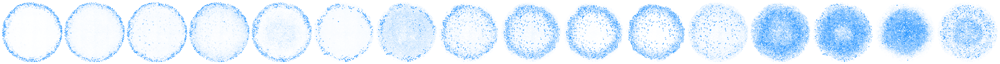

In [64]:
# GENES EXPERIMENT

colID = 1

lim = 350
m = 1
ms = 10
n = len(gene_names)
fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
vlim = dict()
white_blue = mcolors.LinearSegmentedColormap.from_list('white_blue', ['white','dodgerblue'])

for i,f in enumerate(gene_names):

    vlim[f] = col[colID].scatter(f, ms=ms, ax=ax[i], tol=(1,99), cmap=white_blue)
    ax[i].set_xlim([-lim,lim])
    ax[i].set_ylim([lim,-lim])

os.makedirs(dataDir+"/FigS5/",exist_ok=True)
plt.savefig(dataDir+"/FigS5/" + 'markers' + '_' + conditions[0] + file_suffix)

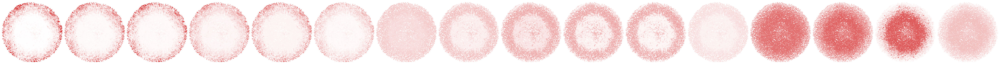

In [66]:
colID = 1
n = len(gene_names)

fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
white_red = mcolors.LinearSegmentedColormap.from_list('white_red', ['white',[0.8, 0, 0]])

for i,f in enumerate(gene_names):
    
    col_pred[colID].scatter(f, ms=ms, vmin=vlim[f][0], vmax=vlim[f][1],  ax=ax[i], cmap=white_red)
    ax[i].set_xlim([-lim,lim])
    ax[i].set_ylim([lim,-lim])

plt.savefig(dataDir+"/FigS5/" + 'markers_predicted_pSMAD1only_' + '_' + conditions[0] + file_suffix)

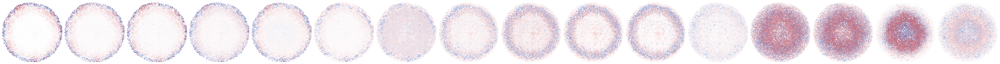

In [67]:
from matplotlib.colors import LinearSegmentedColormap

colID=1

X = (col[colID].cellData['XY']['X'] - col[colID].center[0])*col[colID].resolution
Y = (col[colID].cellData['XY']['Y'] - col[colID].center[1])*col[colID].resolution

n = len(gene_names)
fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)

for i,f in enumerate(gene_names):
    
    color = col[colID].cellData['intensities'][f]
    color_pred = col_pred[colID].cellData['intensities'][f]
    order = color.sort_values().index
    ax[i].scatter(X[order], Y[order], s=ms, c=color[order], cmap=white_blue, vmin=vlim[f][0], vmax=vlim[f][1], alpha=1, edgecolors='none')
    ax[i].scatter(X[order], Y[order], s=ms, c=color_pred[order], cmap=white_red, vmin=vlim[f][0], vmax=vlim[f][1], alpha=0.5, edgecolors='none')
    
    # idx = col[colID].cellData['intensities'][f] > thresh[f]
    # ax[i].scatter(X[idx], Y[idx], s=ms, c='b', alpha=0.3)
    #idx = col_pred[colID].cellData['intensities'][f] > thresh[f]
    #ax[i].scatter(X[idx], Y[idx], s=ms, c='r', alpha=0.3)
    
    ax[i].set_aspect('equal') 
    ax[i].axis('off')
    ax[i].set_xlim([-lim,lim])
    ax[i].set_ylim([lim,-lim])

plt.savefig(dataDir+"/FigS5/" + 'markers_overlay_pSMAD1only_' + '_' + conditions[0] + file_suffix)

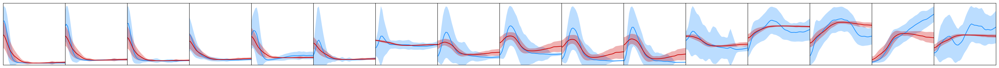

In [68]:
colID = 1
n = len(gene_names)
m = 1

fig, ax = plt.subplots(m,n, figsize=(n*2,m*2))
mode = 'cells'

for i,f in enumerate(gene_names):
    
    exp.plotRadialProfiles(f, 'B50', mode=mode, sigma=1, color='dodgerblue', ax=ax[i])
    exp_pred.plotRadialProfiles(f, 'B50', mode=mode, sigma=1, color=[0.8, 0, 0], ax=ax[i])
    ax[i].set_xticks([])
    ax[i].set_yticks([])
    ax[i].set_ylabel(None)
    ax[i].set_xlabel(None)

plt.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0, hspace=0)

plt.savefig(dataDir+"/FigS5/" + 'profile_expvpred_pSMAD1only_' + conditions[0] + '_std' + mode + file_suffix)#, bbox_inches='tight')

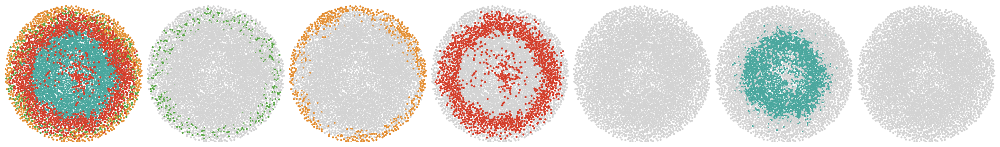

In [69]:
colID = 1
fate_names_outsidein = ['AMLC', 'PGCLC', 'PSLC', 'meso', 'pluri', 'ecto']
n = len(fate_names_outsidein) + 1

fig, ax = plt.subplots(m,n, figsize=(n*3,m*3), constrained_layout=True)
ms = 10

col_pred[colID].scatter_fates(ms=ms, thresh=thresh, legend=False, ax=ax[0]) 
ax[0].set_xlim([-lim,lim])
ax[0].set_ylim ([lim,-lim])

for i,f in enumerate(fate_names_outsidein):
    fates = col_pred[colID].scatter_fates(ms=ms, thresh=thresh, legend=False, ax=ax[i+1], fate=f) 
    ax[i+1].set_xlim([-lim,lim])
    ax[i+1].set_ylim([lim,-lim])

plt.savefig(dataDir+"/FigS5/" + 'fates_pred_pSMAD1only_scatter_' + conditions[0] + file_suffix)

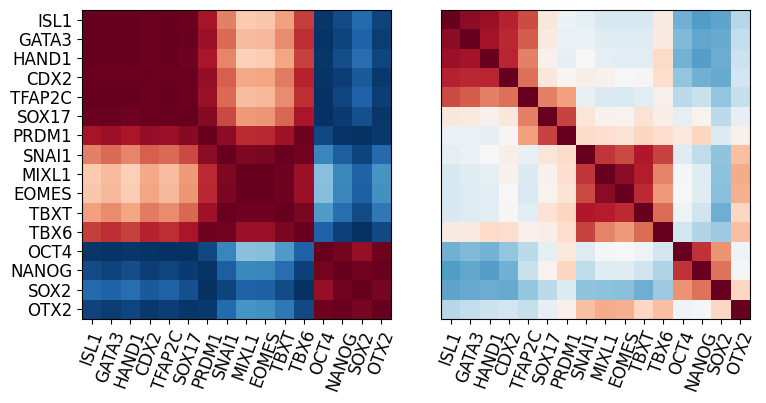

In [70]:
avg_pred = pred_subs['pSMAD1']['avg']

# correlations 
def calc_pearsoncorr(x1,x2): #only feature can be discrete
    from scipy.stats import pearsonr
    X1 = x1.to_numpy()
    X2 = x2.to_numpy()
    
    indices = (~np.isnan(X1)*~np.isnan(X2))
    
    corr = pearsonr(X1[indices].reshape(-1, 1)[:,0],X2[indices])
    return corr
    
fig_size = [8,4]  
fs2 = 12
params = {
          'figure.figsize': fig_size,
          'xtick.labelsize': fs2,
          'ytick.labelsize': fs2,
          }
plt.rcParams.update(params)

N_var = len(gene_names)

Corr_all = np.zeros((N_var,N_var,2))

for k1,g1 in enumerate(gene_names):
    for k2, g2 in enumerate(gene_names):
        Corr_all[k1,k2,0],_ = calc_pearsoncorr(data.loc[:,g1], data.loc[:,g2])
        Corr_all[k1,k2,1],_ = calc_pearsoncorr(avg_pred.loc[:,g1], avg_pred.loc[:,g2])


H,W = 1,2

plt.figure()
plt.subplot(H,W,1)
#plt.title('predicted')
plt.imshow(Corr_all[:,:,1],vmin=-1,vmax=1,cmap='RdBu_r')
#plt.colorbar()

plt.xticks(np.arange(0,N_var),labels=gene_names,rotation=70)
#plt.xticks([])
plt.yticks(np.arange(0,N_var),labels=gene_names,fontsize=fs2)


plt.subplot(H,W,2)
#plt.title('measured')
plt.imshow(Corr_all[:,:,0],vmin=-1,vmax=1,cmap='RdBu_r')
#plt.colorbar()

plt.xticks(np.arange(0,N_var),labels=gene_names,rotation=70)
#plt.yticks(np.arange(0,N_var),labels=names)
plt.yticks([])

plt.tight_layout()

plt.savefig(dataDir+"/FigS5/" + 'g1g2_corr_matrix_VIB_pSMAD1only_' + cond + '.pdf')

#### Plot fate prediction performance for different signal combination

In [75]:
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}

signal_combinations = [
    ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK', 'cytopAKT'],
    ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'ncSMAD2', 'cytopERK'],
    ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'ncSMAD2', 'cytopERK'],
    ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK'],
]
legend_str = ['all signals', '-pAKT', '-pAKT-bcat',  '-pAKT-bcat-SMAD2']

data_b50 = data[data['condition'] == 'B50']
N_run = 3
recompute = False   # set True to force retraining even if a run's CSV already exists

pred_subs = {}
for sig_combo in signal_combinations:
    sig_str = '_'.join(sorted(sig_combo, key=str.lower))
    out_prefix = f'selfB50_{sig_str}'
    IIF.run_vib_self(data_b50, sig_combo, gene_names, hyperparam, N_run=N_run,
                      out_dir=dataDir + '/VIB_self', out_prefix=out_prefix,
                      recompute=recompute, label=out_prefix)
    pred_subs[sig_str] = IIF.load_vib_self(data_b50, sig_combo, gene_names, hyperparam, N_run=N_run,
                                            out_dir=dataDir + '/VIB_self', out_prefix=out_prefix,
                                            label=out_prefix)

[selfB50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1] Run 0/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/VIB_self/selfB50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_run0.csv
[selfB50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1] Run 1/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/VIB_self/selfB50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_run1.csv
[selfB50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1] Run 2/3 -- already exists, skipping load: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/VIB_self/selfB50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_run2.csv
[selfB50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1] Run 0/3 -- already exists, loading: /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/VIB_self/selfB50_BCat_cytopAKT_cytopERK_LEF1_ncSMAD2_ncSMAD23_ncYAP_pSMAD1_run0.csv
[s

In [76]:
# CALCULATE PERFORMANCE
performances, _ = IIF.calcPerformance(data_b50, pred_subs, thresh, gene_names)

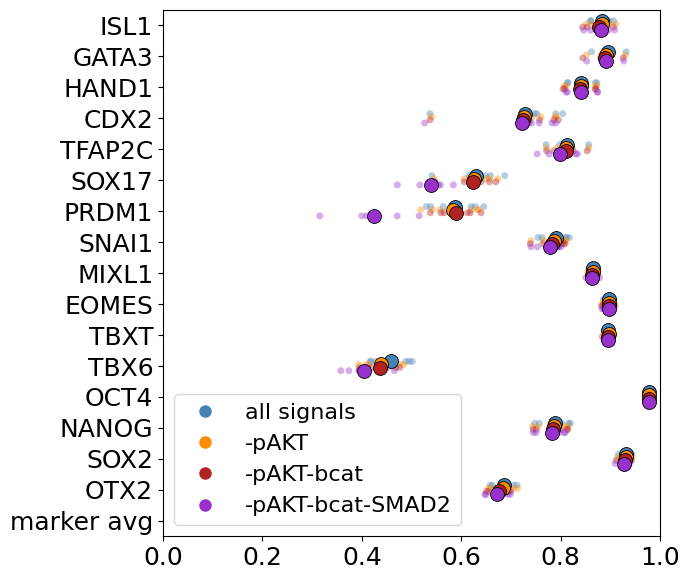

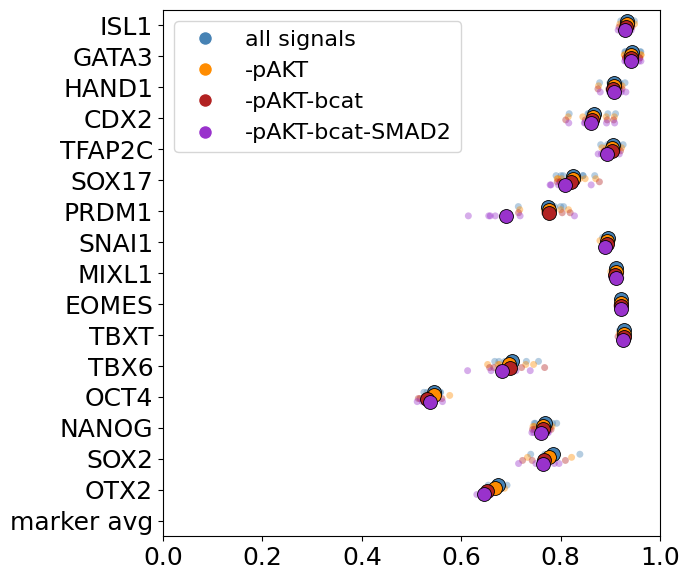

In [87]:
# plot f1 and balanced accuracy per gene, per fold (colony) -- individual colonies as
# dots, matching the per-fold comparison style used throughout fig2n, instead of
# calcPerformance's single mean+std point per combination. Uses balanced accuracy
# instead of calcPerformance's plain accuracy (compute_marker_performance_perfold
# doesn't compute plain accuracy) -- matches fig2n's established convention.

cond = 'B50'
colors = plt.cm.Greens(np.linspace(0.4, 0.9, len(pred_subs)))
colors = ['steelblue', 'darkorange', 'firebrick', 'darkorchid'][:len(pred_subs)]

marker_labels = gene_names + ['marker avg']
marker_dfs = {}
for k in pred_subs.keys():
    df = IIF.compute_marker_performance_perfold(data_b50, pred_subs[k]['avg'], data_b50['Colony'].to_numpy(), gene_names, thresh)
    marker_dfs[k] = IIF.add_group_avg(df, ['f1', 'balanced_accuracy'], group_col='gene')

for score in ['f1', 'balanced_accuracy']:
    IIF.plot_perfold_comparison(
        series=[(marker_dfs[k], score, c) for k, c in zip(pred_subs.keys(), colors)],
        group_col='gene', labels=marker_labels,
        fname=dataDir + f'/FigS4/signal_reduction_marker_{score}_perfold.png',
        legend_labels=legend_str, tick_labels=marker_labels)

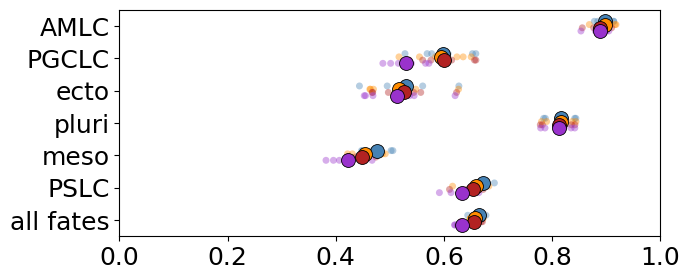

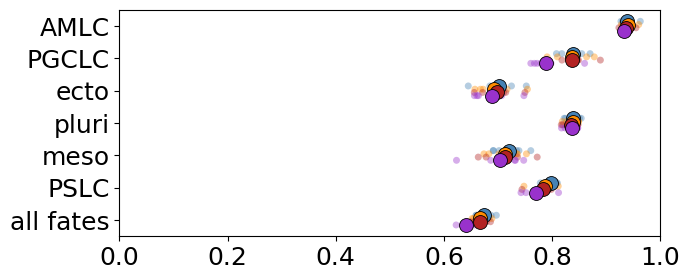

In [83]:
# plot fate-level f1 and balanced accuracy per fold (colony), individual colonies as dots

def fate_perfold_all(data_cond, pred_sub, colonies, thresh):
    """Per-fold (colony) F1 and balanced accuracy for every fate category, plus an
    'all fates' aggregate row (built into compute_category_performance_perfold via its
    aggregate_name argument). Cells called 'other' (fitting no defined fate) are excluded
    from scoring. pred_sub is restricted to data_cond's index first, since prediction
    dicts can cover a wider row set than the specific condition/filter being scored here."""
    pred_sub = pred_sub.loc[data_cond.index]
    fates_true_all, fate_names_raw = IIF.return_fates(data_cond, thresh=thresh)
    fate_names_list = [f for f in fate_names_raw if f != 'other']
    keep = fates_true_all != 'other'
    fates_true = fates_true_all[keep]
    fates_pred_all, _ = IIF.return_fates(pred_sub, thresh=thresh)
    fates_pred = fates_pred_all[keep]
    df = pd.DataFrame(IIF.compute_category_performance_perfold(
        fates_true, fates_pred, colonies[keep], fate_names_list, aggregate_name='all fates'))
    return df

fate_dfs = {k: fate_perfold_all(data_b50, pred_subs[k]['avg'], data_b50['Colony'].to_numpy(), thresh) for k in pred_subs.keys()}

_, fate_names_raw = IIF.return_fates(data_b50, thresh=thresh)
fate_labels = [f for f in fate_names_raw if f != 'other'] + ['all fates']

for score in ['f1', 'balanced_accuracy']:
    IIF.plot_perfold_comparison(
        series=[(fate_dfs[k], score, c) for k, c in zip(pred_subs.keys(), colors)],
        group_col='category', labels=fate_labels,
        fname=dataDir + f'/FigS4/signal_reduction_fate_{score}_perfold.png')

==========ISL1====================
rd: 1
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/251115_VIB_1D_B50_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/251115_VIB_1D_B50_ncYAP_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/251115_VIB_1D_B50_LEF1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/251115_VIB_1D_B50_ncSMAD23_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/251115_VIB_1D_B50_cytopERK_avg.csv
best mean: ('pSMAD1',), 0.70(0.05)
selected best: ('pSMAD1',), 0.70(0.05)
rd: 2
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/251115_VIB_2D_B50_ncYAP_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/251115_VIB_2D_B50_LEF1_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/251115_VIB_2D_B50_ncSMAD23_pSMAD1_avg.csv
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/251115_VIB_2D_B50_cytopERK_pSMAD1_avg.csv
best mean: ('pSMAD1', 'cytopERK'), 0.83

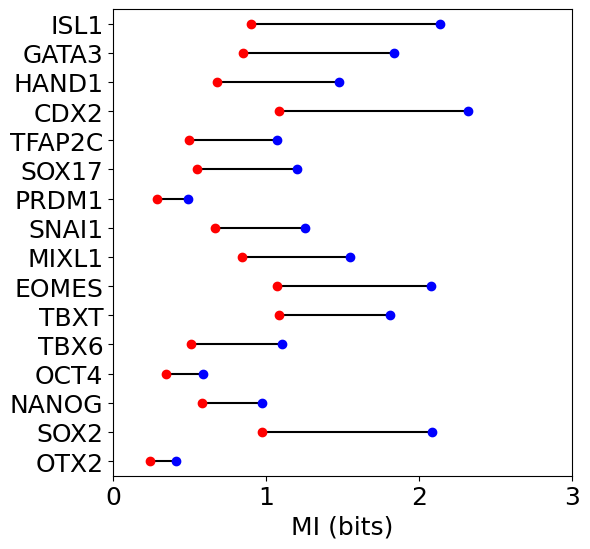

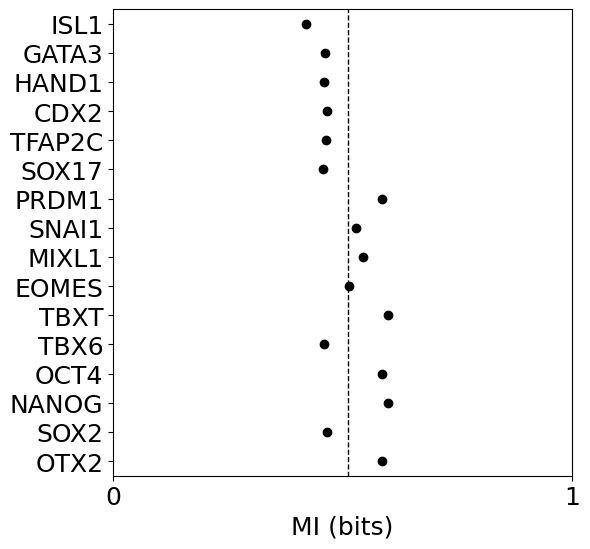

In [86]:
# FOR SI FIGURE
importlib.reload(IIF);

N_run = 3
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
mygenes = gene_names
signals = ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK']

MI_dec = IIF.plotRedundantMI(dataDir, data, cond, mygenes, signals, N_run, hyperparam, out_dir=dataDir + '/FigS4')

## Latent space analysis

### sig2fate vs signal autoencoder

In [156]:
# ============================================================
# TRAIN SIGNAL-TO-FATE (VIB) AND SIGNAL-TO-SIGNAL (AE) MODELS
# across Ldim = 1-8, with Nlay=2, Nhid=32
# ============================================================

import importlib
importlib.reload(IIF)

N_run = 3
signals = ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK'] # 5D model
feat_names = signals
Nlay = 2
Nhid = 32
Ldim_range = range(1, len(signals)+1)

cond = 'B50'
data_cond = data[data['condition'] == cond]
colony_idx = np.unique(data_cond['Colony'])

for Ldim in Ldim_range:
    
    hyperparam = {'HIDDEN_DIM': Nhid, 'N_LAYERS': Nlay, 'LATENT_DIM': Ldim}

    for it in range(N_run):
        print(f"  Ldim={Ldim}, Run {it}/{N_run}")
        start = time.time()

        print('sig2fate')
        # --- SIGNAL-TO-FATE (already written, reuse same filenames as before) ---
        pred_df = data.copy()

        for test_colony in colony_idx:
            train_colonies = np.setdiff1d(colony_idx, test_colony)
            data_test  = data_cond[data_cond['Colony'].isin([test_colony])]
            data_train = data_cond[data_cond['Colony'].isin(train_colonies)]

            vib = IIF.VIB(data_train[feat_names], data_train[gene_names], hyperparam)
            _ = vib.train(verbose=False)
            tar_predict = vib.predict(data_test[feat_names])
            pred_df.loc[tar_predict.index, tar_predict.columns] = tar_predict

        pred_df.to_csv(
            dataDir + f'/260309_VIB_{len(feat_names)}D_B50'
            f'_Nhid{Nhid}_Nlay{Nlay}_Ldim{Ldim}_run{it}.csv'
        )

        print('sig2sig')
        # --- SIGNAL-TO-SIGNAL AUTOENCODER ---
        ae_pred_df = data.copy()

        for test_colony in colony_idx:
            train_colonies = np.setdiff1d(colony_idx, test_colony)
            data_test  = data_cond[data_cond['Colony'].isin([test_colony])]
            data_train = data_cond[data_cond['Colony'].isin(train_colonies)]

            # input == output: autoencoder
            vib_ae = IIF.VIB(data_train[feat_names], data_train[feat_names], hyperparam)
            _ = vib_ae.train(verbose=False)
            sig_predict = vib_ae.predict(data_test[feat_names])
            ae_pred_df.loc[sig_predict.index, sig_predict.columns] = sig_predict

        ae_pred_df.to_csv(
            dataDir + f'/260309_AE_{len(feat_names)}D_B50'
            f'_Nhid{Nhid}_Nlay{Nlay}_Ldim{Ldim}_run{it}.csv'
        )

        end = time.time()
        print(f"  Elapsed: {end - start:.1f}s")

  Ldim=1, Run 0/3
sig2fate
sig2sig
  Elapsed: 40.6s
  Ldim=1, Run 1/3
sig2fate
sig2sig
  Elapsed: 39.4s
  Ldim=1, Run 2/3
sig2fate
sig2sig
  Elapsed: 39.4s
  Ldim=2, Run 0/3
sig2fate
sig2sig
  Elapsed: 41.9s
  Ldim=2, Run 1/3
sig2fate
sig2sig
  Elapsed: 42.0s
  Ldim=2, Run 2/3
sig2fate
sig2sig
  Elapsed: 41.7s
  Ldim=3, Run 0/3
sig2fate
sig2sig
  Elapsed: 42.7s
  Ldim=3, Run 1/3
sig2fate
sig2sig
  Elapsed: 41.6s
  Ldim=3, Run 2/3
sig2fate
sig2sig
  Elapsed: 41.6s
  Ldim=4, Run 0/3
sig2fate
sig2sig
  Elapsed: 42.1s
  Ldim=4, Run 1/3
sig2fate
sig2sig
  Elapsed: 41.7s
  Ldim=4, Run 2/3
sig2fate
sig2sig
  Elapsed: 41.9s
  Ldim=5, Run 0/3
sig2fate
sig2sig
  Elapsed: 45.1s
  Ldim=5, Run 1/3
sig2fate
sig2sig
  Elapsed: 46.1s
  Ldim=5, Run 2/3
sig2fate
sig2sig
  Elapsed: 47.6s


In [157]:
# ============================================================
# LOAD, AVERAGE RUNS, COMPUTE MSE, PLOT
# ============================================================

Nlay = 2
Nhid = 32
N_run = 3
feat_names = signals
Ldim_range = range(1, len(signals)+1)

cond = 'B50'
condidx = data['condition'] == cond

# z-score ground truth once
data_cond_z_genes   = data[condidx][gene_names].apply(sp.stats.zscore, axis=0)
data_cond_z_signals = data[condidx][feat_names].apply(sp.stats.zscore, axis=0)

mse_vib_runs = {Ldim: [] for Ldim in Ldim_range}   # signal-to-fate
mse_ae_runs  = {Ldim: [] for Ldim in Ldim_range}   # signal-to-signal AE

for Ldim in Ldim_range:
    for it in range(N_run):

        # --- VIB (signal -> fate) ---
        pred_vib = pd.read_csv(
            dataDir + f'/260309_VIB_{len(feat_names)}D_B50'
            f'_Nhid{Nhid}_Nlay{Nlay}_Ldim{Ldim}_run{it}.csv',
            index_col=0
        )
        pred_vib_z = pred_vib[condidx][gene_names].apply(sp.stats.zscore, axis=0)
        mse_vib_runs[Ldim].append(((data_cond_z_genes - pred_vib_z) ** 2).mean().mean())

        # --- AE (signal -> signal) ---
        pred_ae = pd.read_csv(
            dataDir + f'/260309_AE_{len(feat_names)}D_B50'
            f'_Nhid{Nhid}_Nlay{Nlay}_Ldim{Ldim}_run{it}.csv',
            index_col=0
        )
        pred_ae_z = pred_ae[condidx][feat_names].apply(sp.stats.zscore, axis=0)
        mse_ae_runs[Ldim].append(((data_cond_z_signals - pred_ae_z) ** 2).mean().mean())

# Summarize across runs
Ldims = list(Ldim_range)

vib_mean = np.array([np.mean(mse_vib_runs[L]) for L in Ldims])
vib_sem  = np.array([np.std( mse_vib_runs[L]) / np.sqrt(N_run) for L in Ldims])

ae_mean  = np.array([np.mean(mse_ae_runs[L])  for L in Ldims])
ae_sem   = np.array([np.std( mse_ae_runs[L])  / np.sqrt(N_run) for L in Ldims])

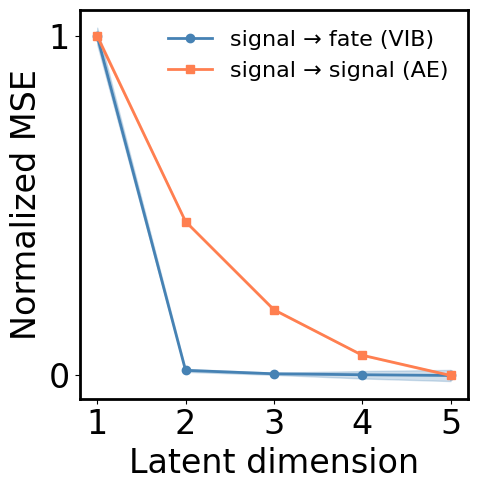

In [160]:
# ============================================================
# PLOT - scaled 0 to 1
# ============================================================

def minmax_scale(mean, sem):
    mn, mx = mean.min(), mean.max()
    mean_scaled = (mean - mn) / (mx - mn)
    sem_scaled  = sem  / (mx - mn)  # sem scales by same factor
    return mean_scaled, sem_scaled

vib_norm, vib_sem_norm = minmax_scale(vib_mean, vib_sem)
ae_norm,  ae_sem_norm  = minmax_scale(ae_mean,  ae_sem)

fs = 24
fs2 = 16
sw = 2
fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(Ldims, vib_norm, 'o-', color='steelblue', label='signal → fate (VIB)',  linewidth=2, markersize=6)
ax.fill_between(Ldims, vib_norm - vib_sem_norm, vib_norm + vib_sem_norm, alpha=0.25, color='steelblue')

ax.plot(Ldims, ae_norm,  's-', color='coral',     label='signal → signal (AE)', linewidth=2, markersize=6)
ax.fill_between(Ldims, ae_norm - ae_sem_norm, ae_norm + ae_sem_norm, alpha=0.25, color='coral')

ax.set_xlabel('Latent dimension', fontsize=fs)
ax.set_ylabel('Normalized MSE', fontsize=fs)
ax.set_xticks(Ldims)
ax.set_yticks([0, 1])
ax.tick_params(labelsize=fs)
ax.legend(fontsize=fs2, frameon=False)
ax.set_box_aspect(1)

for spine in ax.spines.values():
    spine.set_linewidth(sw)

plt.tight_layout()
os.makedirs(dataDir+ '/FigS7/', exist_ok=True)
plt.savefig(dataDir+ f'/FigS7/VIB_{len(signals)}D_vs_AE_MSE_vs_Ldim_Nhid{Nhid}_Nlay{Nlay}_scaled01.png', dpi=150)
plt.show()

### Initial latent space analysis: fate map

#### Reproducibility 

In [5]:
# TRAIN THE MODEL ON ALL B50 DATA TO LOOK AT LATENT SPACE

N_run = 20
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
signals = ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK']
genes = gene_names

vib = {}

cond = 'B50'
data_cond = data[data['condition']==cond]

feat_train = data_cond[signals] 
tar_train = data_cond[gene_names]


for run in range(0, N_run):

    # set seeds for reproducibility
    torch.manual_seed(run)
    np.random.seed(run)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(run)

    vib[run] = IIF.VIB(feat_train, tar_train, hyperparam)
    
    if not os.path.exists(dataDir + '/modelws_' + str(run) + '_' + str(len(signals)) + 'D' + '.pth'):
        print('run VIB')
        _ = vib[run].train(verbose=False)
        torch.save(vib[run].model, dataDir + '/modelws_' + str(run) + '_' + str(len(signals)) + 'D' + '.pth')
    else:
        print('load VIB')
        filepath = dataDir + '/modelws_' + str(run) + '_' + str(len(signals)) + 'D' + '.pth';
        vib[run].model = torch.load(filepath, weights_only=False)
        print(filepath)

load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_0_5D.pth
load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_1_5D.pth
load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_2_5D.pth
load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_3_5D.pth
load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_4_5D.pth
load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_5_5D.pth
load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_6_5D.pth
load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_7_5D.pth
load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_8_5D.pth
load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_9_5D.pth
load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_10_5D.pth
load VIB
/Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/modelws_11_5D.pth
lo

In [6]:
# ============================================================
# LATENT SPACE REPRODUCIBILITY ACROSS SEEDS -- helper functions
# ============================================================
from scipy.spatial import procrustes as scipy_procrustes

def get_latent(vib_instance, X_data):
    """Encode X_data (DataFrame of signal columns, same columns/order the model's scaler
    was fit with) into the trained model's 2D latent mu. Returns (N,2) numpy array."""
    X_z = vib_instance.scaler_X_run.transform(X_data)
    X_t = torch.FloatTensor(X_z).to(device)
    vib_instance.model.eval()
    with torch.no_grad():
        mu, _ = vib_instance.model.encode(X_t)
    return mu.cpu().numpy()

def procrustes_align(ref, src):
    """Procrustes-align src (N,2) onto ref (N,2) by row correspondence (row i of both
    must be the same cell), allowing translation, rotation, reflection and uniform
    scaling. Both are centered and normalized to unit Frobenius norm by
    scipy.spatial.procrustes, which also performs the optimal rotation/reflection fit;
    phi = arctan2(y,x) is invariant to that uniform positive scaling, so the standardized
    coordinates are fine for angle computation without recovering the original
    latent-space scale. Returns (ref_std, aligned_src, reflected, disparity): ref_std and
    aligned_src are the standardized reference/aligned-source coordinates (N,2), each
    centered at the origin (so "the centroid of that seed's aligned latent" is the
    origin, by construction); reflected is True if the optimal fit required a reflection
    (recomputed here via the same SVD scipy uses internally, purely to read off det(R));
    disparity is scipy's residual sum of squared pointwise differences between the two
    standardized point sets (0 = perfect alignment)."""
    ref_std, aligned_src, disparity = scipy_procrustes(ref, src)

    ref_c = ref - ref.mean(axis=0)
    src_c = src - src.mean(axis=0)
    ref_n = ref_c / np.linalg.norm(ref_c)
    src_n = src_c / np.linalg.norm(src_c)
    U, S, Vt = np.linalg.svd(src_n.T @ ref_n)
    reflected = np.linalg.det(U @ Vt) < 0

    return ref_std, aligned_src, reflected, disparity

def circ_mean(phi):
    """Circular mean of angles phi (radians), via the mean resultant vector."""
    return np.arctan2(np.mean(np.sin(phi)), np.mean(np.cos(phi)))

def circ_corr(phi1, phi2):
    """Circular-circular correlation coefficient (Jammalamadaka & Sarma 1988) between two
    equal-length, cell-matched angle arrays (radians)."""
    m1, m2 = circ_mean(phi1), circ_mean(phi2)
    num = np.sum(np.sin(phi1 - m1) * np.sin(phi2 - m2))
    den = np.sqrt(np.sum(np.sin(phi1 - m1) ** 2) * np.sum(np.sin(phi2 - m2) ** 2))
    return num / den

def circ_std(phi_matrix, axis):
    """Circular standard deviation (Mardia & Jupp angular deviation, radians) of angles
    in phi_matrix along the given axis, via the mean resultant length
    R = |mean(exp(i*phi))|: std = sqrt(-2*ln(R)). R -> 0 (near-uniform spread) drives
    std -> inf; that's expected near the latent-space origin where phi is poorly
    determined, not a bug."""
    C = np.mean(np.cos(phi_matrix), axis=axis)
    S = np.mean(np.sin(phi_matrix), axis=axis)
    R = np.sqrt(C ** 2 + S ** 2)
    with np.errstate(divide='ignore'):
        return np.sqrt(-2 * np.log(R))

def circ_diff(phi1, phi2):
    """Signed angular difference phi1 - phi2 (radians), wrapped to (-pi, pi]."""
    d = phi1 - phi2
    return (d + np.pi) % (2 * np.pi) - np.pi

def is_cyclic_rotation(seq, ref):
    """True if tuple seq is a cyclic rotation of tuple ref -- same elements, same
    relative circular order, any starting point. Used instead of plain tuple equality
    when comparing fate orderings around the circle, since sorting angles in [0, 2pi)
    gives a valid cyclic order but from an arbitrary starting point (wherever 0 falls
    relative to the fates for that particular seed) -- two seeds with the identical
    underlying arrangement can otherwise look like a "mismatch" just because the
    branch cut landed in a different place."""
    if len(seq) != len(ref) or set(seq) != set(ref):
        return False
    doubled = ref + ref
    return any(doubled[i:i + len(ref)] == seq for i in range(len(ref)))

def circular_order(row):
    """Fate names in row (a Series of circular-mean angles) sorted into cyclic order."""
    angles = np.mod(row.values.astype(float), 2 * np.pi)
    return tuple(row.index[np.argsort(angles)])
def plot_fate_circular_means(means_relative_df, fates, title, fname, sw=2, fs=24, order_by_mean=False):
    """Box plot + overlaid individual points of each fate's circular mean phi, relative
    to the reference fate, across runs or folds. means_relative_df: rows=runs/folds,
    columns=fates (radians). fates: ordered list of fate names (x-axis order), used
    as-is unless order_by_mean=True, in which case fates are sorted by their circular
    mean (across rows) instead of the given order."""
    if order_by_mean:
        fates = sorted(fates, key=lambda f: circ_mean(means_relative_df[f].values.astype(float)))

    fig, ax = plt.subplots(figsize=(7, 6))

    data_per_fate = [means_relative_df[f].values.astype(float) for f in fates]
    bp = ax.boxplot(data_per_fate, positions=range(len(fates)), widths=0.5,
                     showfliers=False, patch_artist=True, zorder=2)
    for patch, f in zip(bp['boxes'], fates):
        patch.set_facecolor(IIF.colmap_fates[f])
        patch.set_alpha(0.3)
    for element in ['whiskers', 'caps', 'medians']:
        for line in bp[element]:
            line.set_color('k')

    n = len(means_relative_df)
    for i, f in enumerate(fates):
        vals = means_relative_df[f].values.astype(float)
        ax.scatter(np.full(n, i) + np.random.uniform(-0.1, 0.1, n), vals,
                   s=20, alpha=0.8, color=IIF.colmap_fates[f], zorder=3)

    ax.set_xticks(range(len(fates)))
    ax.set_xticklabels(fates, fontsize=fs - 6)
    ax.set_ylabel(r'$\langle\phi\rangle_{fate}$ (rad)', fontsize=fs)
    ax.set_ylim(-np.pi, np.pi)
    ax.set_yticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
    ax.set_yticklabels([r'$-\pi$', r'$-\pi/2$', '0', r'$\pi/2$', r'$\pi$'], fontsize=fs)
    ax.set_title(title, fontsize=fs)

    for spine in ax.spines.values():
        spine.set_linewidth(sw)
    ax.set_box_aspect(1)

    plt.tight_layout()
    plt.savefig(fname)


def plot_fate_circular_means_by_variant(variant_dfs, fates, title, fname, sw=2, fs=24, order_by_mean=False):
    """Like plot_fate_circular_means, but combines multiple variants (architecture,
    signal-addition configs) into one plot: one box per fate (pooling all variants'
    seeds), with individual points colored by variant instead of by fate, so any
    outlier variant is easy to spot. variant_dfs: {variant_label: means_relative_df}
    (rows=seeds, columns=fates, radians, relative to reference_fate). fates: ordered
    list of fate names (x-axis order), used as-is unless order_by_mean=True, in which
    case fates are sorted by their circular mean pooled across all variants."""
    if order_by_mean:
        pooled_means = {f: circ_mean(np.concatenate([df[f].values.astype(float) for df in variant_dfs.values()]))
                         for f in fates}
        fates = sorted(fates, key=lambda f: pooled_means[f])

    fig, ax = plt.subplots(figsize=(9, 6))

    pooled_per_fate = [np.concatenate([df[f].values.astype(float) for df in variant_dfs.values()])
                        for f in fates]
    bp = ax.boxplot(pooled_per_fate, positions=range(len(fates)), widths=0.5,
                     showfliers=False, patch_artist=True, zorder=2)
    for patch, f in zip(bp['boxes'], fates):
        patch.set_facecolor(IIF.colmap_fates[f])
        patch.set_alpha(0.3)
    for element in ['whiskers', 'caps', 'medians']:
        for line in bp[element]:
            line.set_color('k')

    variant_colors = dict(zip(variant_dfs.keys(), plt.cm.tab10.colors[:len(variant_dfs)]))
    n_variants = len(variant_dfs)
    jitter_positions = np.linspace(-0.25, 0.25, n_variants)

    for v_idx, (variant, df) in enumerate(variant_dfs.items()):
        n = len(df)
        for i, f in enumerate(fates):
            vals = df[f].values.astype(float)
            x = np.full(n, i) + jitter_positions[v_idx] + np.random.uniform(-0.04, 0.04, n)
            ax.scatter(x, vals, s=20, alpha=0.8, color=variant_colors[variant],
                       zorder=3, label=variant if i == 0 else None)

    ax.set_xticks(range(len(fates)))
    ax.set_xticklabels(fates, fontsize=fs - 6)
    ax.set_ylabel(r'$\langle\phi\rangle_{fate}$ (rad)', fontsize=fs)
    ax.set_ylim(-np.pi, np.pi)
    ax.set_yticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
    ax.set_yticklabels([r'$-\pi$', r'$-\pi/2$', '0', r'$\pi/2$', r'$\pi$'], fontsize=fs)
    ax.set_title(title, fontsize=fs)
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=fs - 6)

    for spine in ax.spines.values():
        spine.set_linewidth(sw)
    ax.set_box_aspect(1)

    plt.tight_layout()
    plt.savefig(fname, bbox_inches='tight')


os.makedirs(dataDir + '/Fig3/latent_reproducibility', exist_ok=True)
LR_OUT = dataDir + '/Fig3/latent_reproducibility'


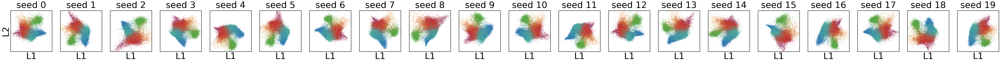

In [9]:
# CHECK REPRODUCIBILITY OF LATENT SPACE

# ============================================================
# helper -- square, percentile-based axis limits shared across panels (same convention
# as cell 62's margin computation, generalized to pool across seeds so every panel gets
# the SAME limits rather than each auto-scaling to its own data)
# ============================================================
def square_percentile_limits(x, y, tol=(0.1, 99.9), marg=0.5):
    """Symmetric, square (equal x/y range) axis limits covering the tol percentile range
    of x and y (pass in data pooled across whatever panels/seeds should share limits),
    plus a margin. Multiple panels using these same limits are then directly, visually
    comparable -- point-cloud size/position differences are real, not an artifact of
    each panel auto-scaling to fill its own box."""
    xlim = (np.percentile(x, tol[0]) - marg, np.percentile(x, tol[1]) + marg)
    ylim = (np.percentile(y, tol[0]) - marg, np.percentile(y, tol[1]) + marg)
    x_range, y_range = xlim[1] - xlim[0], ylim[1] - ylim[0]
    max_range = max(x_range, y_range)
    x_center, y_center = (xlim[0] + xlim[1]) / 2, (ylim[0] + ylim[1]) / 2
    return (x_center - max_range / 2, x_center + max_range / 2), (y_center - max_range / 2, y_center + max_range / 2)

fs = 50
sw = 2
n = 1
m = N_run
cond = 'B50'
mask = (data['condition'] == cond)
fates, _ = IIF.return_fates(data[mask], thresh=thresh)
colors = [IIF.colmap_fates[f] for f in fates]

# first pass: each seed's own z-scored latent (same convention as before), pooled to get
# ONE shared, square set of axis limits
L_scaled_by_run = {}
for run in range(N_run):
    model = vib[run].model
    X = vib[run].scaler_X_run.transform(data.loc[mask, signals])
    X = torch.FloatTensor(X).to(device)
    model.eval()
    with torch.no_grad():
        mu, _ = model.encode(X)
    L1 = mu[:, 0].cpu().numpy()
    L2 = mu[:, 1].cpu().numpy()
    L_scaled_by_run[run] = ((L1 - L1.mean()) / L1.std(), (L2 - L2.mean()) / L1.std())

all_L1 = np.concatenate([L_scaled_by_run[run][0] for run in range(N_run)])
all_L2 = np.concatenate([L_scaled_by_run[run][1] for run in range(N_run)])
xlim, ylim = square_percentile_limits(all_L1, all_L2)

fig, ax = plt.subplots(n, m, figsize=(5 * m, 5 * n))

for run in range(N_run):
    L1_scaled, L2_scaled = L_scaled_by_run[run]
    ax[run].scatter(L1_scaled, L2_scaled, c=colors, s=1)
    ax[run].set_xlabel('L1', fontsize=fs)
    if run == 0:
        ax[run].set_ylabel('L2', fontsize=fs)
    ax[run].set_xticks([]); ax[run].set_yticks([])
    ax[run].set_title('seed ' + str(run), fontsize=fs, pad=15)
    for spine in ax[run].spines.values():
        spine.set_linewidth(sw)
    ax[run].set_xlim(xlim); ax[run].set_ylim(ylim)
    ax[run].set_aspect('equal', adjustable='box')

fig.set_constrained_layout_pads(wspace=0.02, hspace=0.02, w_pad=0.0, h_pad=0.01)

plt.savefig(LR_OUT + '/LS_fate_reproducibility_' + str(len(signals)) + 'D_new.png', bbox_inches='tight')


In [ ]:
# ==========================================================================================
# STEPS 0-5: procrustes align 20 runs with different seeds and compare
# ==========================================================================================


# ============================================================
# STEP 0: extract latent coordinates for all seeds, all B50 cells (prerequisite)
# ============================================================
# hardcoded explicitly (not read from the `signals`/`hyperparam`/`cond` globals) --
# the Ldim=1..8 sweep cell reassigns these later in the notebook and leaves them
# changed, so relying on the globals here would silently train/evaluate on the wrong
# config if this is run after that cell. Must match what the `vib` dict (TRAIN THE MODEL
# ON ALL B50 DATA cell) was actually trained with.

REF_SEED=0

cond = 'B50'
data_cond = data[data['condition'] == cond]

N_seeds = len(vib)
assert vib[REF_SEED].scaler_X_run.n_features_in_ == len(signals), \
    "signals doesn't match what `vib` was trained with -- check the training cell"

mask = (data['condition'] == cond)
cell_index = data[mask].index

L_raw = {run: get_latent(vib[run], data.loc[mask, signals]) for run in range(N_seeds)}
fates, fate_names = IIF.return_fates(data[mask], thresh=thresh)
SIX_FATES = [f for f in fate_names if f != 'other']

print(f'{N_seeds} seeds, {len(cell_index)} cells, fates: {SIX_FATES}')

# ============================================================
# STEP 1: Procrustes-align each seed's latent to seed REF_SEED (reference)
# ============================================================
ref_std, _, _, _ = procrustes_align(L_raw[REF_SEED], L_raw[REF_SEED])  # seed 0 standardized to itself
L_aligned = {REF_SEED: ref_std}

procrustes_report = []
for run in range(1, N_seeds):
    _, aligned_src, reflected, disparity = procrustes_align(L_raw[REF_SEED], L_raw[run])
    L_aligned[run] = aligned_src
    procrustes_report.append({'seed': run, 'reflected': reflected, 'disparity': disparity})

procrustes_df = pd.DataFrame(procrustes_report).set_index('seed')
print(procrustes_df)
procrustes_df.to_csv(LR_OUT + '/procrustes_report.csv')

# ============================================================
# COSMETIC ONLY: rotate/reflect the whole already-aligned set (seeds + folds) so its
# shared orientation matches modelws_12_6D.pth -- purely for visual consistency with the
# draft figure. This does NOT change any reproducibility number already computed
# (circular correlations, disparities, fate orderings, angular gaps are all invariant to
# a rotation/reflection applied identically to every seed/fold -- they only ever depend
# on relative angles within the shared frame). modelws_12_6D.pth is not otherwise part of
# any comparison.
# ============================================================
def procrustes_rotation(ref, src):
    """Optimal rotation/reflection matrix R (2x2, applied as src @ R) aligning src onto
    ref, via the same SVD procrustes_align uses internally. Assumes ref/src are already
    centered (translation removed) -- scale doesn't affect which R is optimal."""
    U, S, Vt = np.linalg.svd(src.T @ ref)
    return U @ Vt

signals_checkpoint = ['pSMAD1', 'ncYAP', 'LEF1', 'BCat', 'ncSMAD23', 'cytopERK']  # modelws_12_6D.pth's signals
hyperparam_checkpoint = {'HIDDEN_DIM': 32, 'N_LAYERS': 2, 'LATENT_DIM': 2}

feat_train_ck = data_cond[signals_checkpoint]
tar_train_ck = data_cond[gene_names]
vib_checkpoint = IIF.VIB(feat_train_ck, tar_train_ck, hyperparam_checkpoint)
vib_checkpoint.model = torch.load(os.path.join(dataDir, f'modelws_12_{len(signals_checkpoint)}D.pth'),
                                   map_location='cpu', weights_only=False)
vib_checkpoint.model = vib_checkpoint.model.to(device)


L_checkpoint = get_latent(vib_checkpoint, data.loc[mask, signals_checkpoint])
_, checkpoint_std, _, _ = procrustes_align(L_checkpoint, L_checkpoint)  # standardize (center + unit norm)

R_to_checkpoint = procrustes_rotation(checkpoint_std, L_aligned[REF_SEED])

L_aligned = {run: L_aligned[run] @ R_to_checkpoint for run in L_aligned}

# refresh everything that depends on absolute (not just relative) orientation, for plotting
phi = {run: np.arctan2(L_aligned[run][:, 1], L_aligned[run][:, 0]) for run in range(N_seeds)}
r_ref = np.linalg.norm(L_aligned[REF_SEED], axis=1)

# ============================================================
# STEP 2: phi = polar angle about the (aligned) centroid, every cell, every seed
# ============================================================
phi = {run: np.arctan2(L_aligned[run][:, 1], L_aligned[run][:, 0]) for run in range(N_seeds)}
phi_matrix = np.stack([phi[run] for run in range(N_seeds)], axis=1)  # (N_cells, N_seeds)
r_ref = np.linalg.norm(L_aligned[0], axis=1)  # reference latent radius, for step 4

# ============================================================
# STEP 3: circular correlation of each seed's phi against the reference (seed 0)
# ============================================================
circcorr_report = [{'seed': run, 'circular_corr': circ_corr(phi[run], phi[0])} for run in range(1, N_seeds)]
circcorr_df = pd.DataFrame(circcorr_report).set_index('seed')
print(circcorr_df)
print(f"mean: {circcorr_df['circular_corr'].mean():.4f}, std: {circcorr_df['circular_corr'].std():.4f}")
circcorr_df.to_csv(LR_OUT + '/circular_correlation_vs_reference.csv')

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(circcorr_df.index.astype(str), circcorr_df['circular_corr'])
ax.axhline(circcorr_df['circular_corr'].mean(), color='k', linestyle='--', label='mean')
ax.set_xlabel('seed'); ax.set_ylabel('circular correlation vs seed 0'); ax.legend()
plt.tight_layout()
plt.savefig(LR_OUT + '/circular_correlation_vs_reference.png')

# ============================================================
# STEP 4 (revised): circular sd of phi in degrees, binned vs radius with IQR band and a
# reference line at the mean adjacent-fate separation; matching latent-space panel
# ============================================================
phi_std_percell_deg = np.degrees(phi_std_percell)  # from the original Step 4 cell
finite = np.isfinite(phi_std_percell_deg)

# --- adjacent-fate angular separations, reference seed (seed 0) ---
order = reference_order  # cyclic order from Step 5, seed 0's fate circular means
order_angles = np.mod(np.array([fate_means.loc[0, f] for f in order]), 2 * np.pi)
adjacent_pairs = [(order[i], order[(i + 1) % len(order)]) for i in range(len(order))]
adjacent_gaps_rad = [(order_angles[(i + 1) % len(order)] - order_angles[i]) % (2 * np.pi)
                      for i in range(len(order))]
adjacent_seps_deg = np.degrees(adjacent_gaps_rad)
mean_adjacent_sep_deg = adjacent_seps_deg.mean()

print("adjacent-fate angular separations (reference seed 0):")
for (f1, f2), sep in zip(adjacent_pairs, adjacent_seps_deg):
    print(f"  {f1} -> {f2}: {sep:.2f} deg")
print(f"mean adjacent-fate separation: {mean_adjacent_sep_deg:.2f} deg")

adjacent_seps_df = pd.DataFrame({'from': [p[0] for p in adjacent_pairs],
                                  'to': [p[1] for p in adjacent_pairs],
                                  'separation_deg': adjacent_seps_deg})
adjacent_seps_df.to_csv(LR_OUT + '/adjacent_fate_separations.csv', index=False)

# --- data-driven origin cutoff: radius containing 99% of the 1% of cells with the
# lowest mean resultant length R across seeds -- i.e. the worst-determined angles in
# this dataset, ties the cutoff directly to where phi actually becomes unreliable here
R_resultant = np.sqrt(np.mean(np.cos(phi_matrix), axis=1) ** 2 + np.mean(np.sin(phi_matrix), axis=1) ** 2)
worst_R_threshold = np.percentile(R_resultant, 1)
worst_cells = R_resultant <= worst_R_threshold
origin_cutoff = np.percentile(r_ref[worst_cells], 99)
print(f"\norigin cutoff: r = {origin_cutoff:.4f} (contains 99% of the 1% of cells with "
      f"the lowest mean resultant length R across seeds)")

median_sd_outside_origin = np.median(phi_std_percell_deg[finite & (r_ref > origin_cutoff)])
print(f"median circular sd outside the origin region (r > {origin_cutoff:.4f}): "
      f"{median_sd_outside_origin:.2f} deg")

median_sd_all = np.median(phi_std_percell_deg[finite])
print(f"median circular sd (all cells, deg): {median_sd_all:.2f}")


# --- binned median + IQR vs radius ---
N_BINS = 40
bin_id = pd.qcut(r_ref[finite], N_BINS, labels=False, duplicates='drop')
bin_df = pd.DataFrame({'r': r_ref[finite], 'sd_deg': phi_std_percell_deg[finite], 'bin': bin_id})
bin_stats = bin_df.groupby('bin').agg(
    r_med=('r', 'median'), sd_med=('sd_deg', 'median'),
    sd_q25=('sd_deg', lambda x: np.percentile(x, 25)),
    sd_q75=('sd_deg', lambda x: np.percentile(x, 75)),
).sort_values('r_med')

# --- crossing radius: first downward crossing of the reference line ---
below = bin_stats['sd_med'].values < mean_adjacent_sep_deg
crossing_radius = None
for i in range(1, len(bin_stats)):
    if not below[i - 1] and below[i]:
        r0, r1 = bin_stats['r_med'].values[i - 1], bin_stats['r_med'].values[i]
        s0, s1 = bin_stats['sd_med'].values[i - 1], bin_stats['sd_med'].values[i]
        crossing_radius = r0 + (mean_adjacent_sep_deg - s0) * (r1 - r0) / (s1 - s0)
        break

if crossing_radius is not None:
    print(f"binned median crosses the reference line ({mean_adjacent_sep_deg:.2f} deg) at r = {crossing_radius:.4f}")
else:
    print(f"binned median never crosses the reference line ({mean_adjacent_sep_deg:.2f} deg) in the observed range")

# --- Figure A: binned median + IQR vs radius ---
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(bin_stats['r_med'], bin_stats['sd_med'], color='C0', label='median')
ax.fill_between(bin_stats['r_med'], bin_stats['sd_q25'], bin_stats['sd_q75'], color='C0', alpha=0.25, label='IQR')
ax.axhline(mean_adjacent_sep_deg, color='k', linestyle='--',
           label=f'mean adjacent-fate separation ({mean_adjacent_sep_deg:.1f} deg)')
if crossing_radius is not None:
    ax.axvline(crossing_radius, color='gray', linestyle=':', label=f'crossing radius ({crossing_radius:.3f})')
ax.set_xlabel('latent radius r (reference)')
ax.set_ylabel('circular sd of phi (deg)')
ax.legend()
plt.tight_layout()
plt.savefig(LR_OUT + '/phi_circular_std_vs_radius_binned_deg.png')

fs = 26
sw = 2
n = 1
m = 1
s = 5
alpha = 0.5

L1_scaled = (L_aligned[REF_SEED][:, 0] - L1mean) / L1std
L2_scaled = (L_aligned[REF_SEED][:, 1] - L2mean) / L1std

fig, ax = plt.subplots(n, m, figsize=(5 * m + 1.5, 5 * n))  # +1.5" for the colorbar, so the plot box stays ~5x5

vmax_rad = np.percentile(phi_std_percell[finite], 99)
sc = ax.scatter(L1_scaled, L2_scaled, c=phi_std_percell, s=s, cmap='magma_r',
                 vmin=0, vmax=vmax_rad, alpha=alpha)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label(r'circular sd of $\phi$ (rad)', fontsize=fs)
cbar.ax.tick_params(labelsize=fs)
cbar.solids.set_alpha(1)  # match the scatter's transparency -- otherwise the bar renders at full opacity and looks darker/more saturated than the actual points

ax.set_xlabel('Latent Coordinate 1', fontsize=fs)
ax.set_ylabel('Latent Coordinate 2', fontsize=fs)
ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_linewidth(sw)

marg = 0.5
xlim = (np.percentile(L1_scaled, 0.1) - marg, np.percentile(L1_scaled, 99.9) + marg)
ylim = (np.percentile(L2_scaled, 0.1) - marg, np.percentile(L2_scaled, 99.9) + marg)

x_range = xlim[1] - xlim[0]
y_range = ylim[1] - ylim[0]
max_range = max(x_range, y_range)

x_center = (xlim[0] + xlim[1]) / 2
y_center = (ylim[0] + ylim[1]) / 2

L1smin = x_center - max_range / 2
L1smax = x_center + max_range / 2
L2smin = y_center - max_range / 2
L2smax = y_center + max_range / 2

ax.set_xlim(L1smin, L1smax)
ax.set_ylim(L2smin, L2smax)

ax.set_title('std across runs', fontsize=fs)
ax.set_aspect('equal', adjustable='box')
plt.tight_layout(pad=0.5)

plt.savefig(LR_OUT + '/phi_circular_std_latent_rad.png')


# ============================================================
# STEP 5: per-fate circular mean of phi, per seed -- check ordering, plot
# ============================================================
fate_means = pd.DataFrame(index=range(N_seeds), columns=SIX_FATES, dtype=float)
for run in range(N_seeds):
    for fate in SIX_FATES:
        fate_means.loc[run, fate] = circ_mean(phi[run][fates == fate])

orders = fate_means.apply(circular_order, axis=1)
reference_order = orders[0]
order_matches = orders.apply(lambda o: is_cyclic_rotation(o, reference_order))
print(f"reference (seed 0) fate order: {reference_order}")
print(f"seeds matching reference cyclic order: {order_matches.sum()}/{N_seeds}")
if not order_matches.all():
    for run in orders.index[~order_matches]:
        print(f"  seed {run}: {orders[run]}")

reference_fate = SIX_FATES[0]  # arbitrary angular anchor, purely for visual comparability
fate_means_relative = pd.DataFrame(index=range(N_seeds), columns=SIX_FATES, dtype=float)
for run in range(N_seeds):
    for fate in SIX_FATES:
        fate_means_relative.loc[run, fate] = circ_diff(fate_means.loc[run, fate], fate_means.loc[run, reference_fate])

plot_fate_circular_means(fate_means_relative, SIX_FATES,
                          r'$\langle\phi\rangle_{fate}$ across runs',
                          LR_OUT + '/fate_circular_means_relative.png', order_by_mean=True)

fate_means.to_csv(LR_OUT + '/fate_circular_means_by_seed.csv')
fate_means_relative.to_csv(LR_OUT + '/fate_circular_means_relative_by_seed.csv')


20 seeds, 30427 cells, fates: ['AMLC', 'PGCLC', 'ecto', 'pluri', 'meso', 'PSLC']
      reflected  disparity
seed                      
1          True   0.032939
2          True   0.097678
3         False   0.022720
4          True   0.029809
5          True   0.025455
6          True   0.023137
7         False   0.029207
8          True   0.037768
9         False   0.042649
10         True   0.021040
11        False   0.034736
12        False   0.015764
13         True   0.040030
14         True   0.024354
15         True   0.059461
16        False   0.058857
17         True   0.020100
18        False   0.015135
19        False   0.055947


NameError: name 'L_fold_aligned' is not defined

In [193]:
# ============================================================
# STEP 5 (follow-up): identify which fate pair swaps for seeds whose cyclic order
# differs from the reference, and quantify how close together that pair sits
# ============================================================
def rotate_to_match(order, ref):
    """Rotate cyclic sequence order (tuple) so it starts at the same element as ref[0]."""
    i = order.index(ref[0])
    return order[i:] + order[:i]

def find_order_diff(order, ref):
    """Compare cyclic sequence order against ref (same fates, same length, order already
    resolved to a consistent chirality by the earlier Procrustes reflection handling).
    Rotates order to start at the same element as ref, then reports the positions where
    they differ and whether the difference is a single pairwise swap -- exactly two
    fates trading places, everything else in the same relative position -- the
    signature of two closely-spaced fates flipping order under noise, as opposed to a
    broader rearrangement."""
    rotated = rotate_to_match(order, ref)
    diffs = [(i, rotated[i], ref[i]) for i in range(len(ref)) if rotated[i] != ref[i]]
    is_single_swap = False
    swap_pair = None
    if len(diffs) == 2:
        i, j = diffs[0][0], diffs[1][0]
        candidate = list(rotated)
        candidate[i], candidate[j] = candidate[j], candidate[i]
        if tuple(candidate) == ref:
            is_single_swap = True
            swap_pair = tuple(sorted([rotated[i], rotated[j]]))
    return rotated, diffs, is_single_swap, swap_pair

print(f"reference order: {reference_order}\n")

swap_pairs_seen = []
for run in orders.index[~order_matches]:
    rotated, diffs, is_single_swap, swap_pair = find_order_diff(orders[run], reference_order)
    print(f"seed {run}: {orders[run]}  (rotated to match: {rotated})")
    if is_single_swap:
        print(f"  -> single swap: {swap_pair[0]} <-> {swap_pair[1]}")
        swap_pairs_seen.append(swap_pair)
    else:
        print(f"  -> NOT a single swap, differs at {len(diffs)} positions: {diffs}")

if swap_pairs_seen:
    unique_pairs = set(swap_pairs_seen)
    print(f"\n{len(swap_pairs_seen)}/{len(orders.index[~order_matches])} mismatching seeds are a single swap")
    print(f"unique swapped pairs: {unique_pairs}")
    for pair in unique_pairs:
        gap_per_seed = np.array([circ_diff(fate_means.loc[run, pair[0]], fate_means.loc[run, pair[1]])
                                  for run in range(N_seeds)])
        print(f"  {pair[0]} vs {pair[1]}: mean angular gap = {np.degrees(circ_mean(gap_per_seed)):.2f} deg, "
              f"circular std of that gap = {np.degrees(circ_std(gap_per_seed, axis=0)):.2f} deg (across all {N_seeds} seeds)")


reference order: ('PSLC', 'meso', 'PGCLC', 'AMLC', 'ecto', 'pluri')

seed 2: ('meso', 'PSLC', 'PGCLC', 'AMLC', 'ecto', 'pluri')  (rotated to match: ('PSLC', 'PGCLC', 'AMLC', 'ecto', 'pluri', 'meso'))
  -> NOT a single swap, differs at 5 positions: [(1, 'PGCLC', 'meso'), (2, 'AMLC', 'PGCLC'), (3, 'ecto', 'AMLC'), (4, 'pluri', 'ecto'), (5, 'meso', 'pluri')]
seed 8: ('meso', 'PSLC', 'PGCLC', 'AMLC', 'ecto', 'pluri')  (rotated to match: ('PSLC', 'PGCLC', 'AMLC', 'ecto', 'pluri', 'meso'))
  -> NOT a single swap, differs at 5 positions: [(1, 'PGCLC', 'meso'), (2, 'AMLC', 'PGCLC'), (3, 'ecto', 'AMLC'), (4, 'pluri', 'ecto'), (5, 'meso', 'pluri')]
seed 9: ('meso', 'PSLC', 'PGCLC', 'AMLC', 'ecto', 'pluri')  (rotated to match: ('PSLC', 'PGCLC', 'AMLC', 'ecto', 'pluri', 'meso'))
  -> NOT a single swap, differs at 5 positions: [(1, 'PGCLC', 'meso'), (2, 'AMLC', 'PGCLC'), (3, 'ecto', 'AMLC'), (4, 'pluri', 'ecto'), (5, 'meso', 'pluri')]
seed 15: ('meso', 'PSLC', 'PGCLC', 'AMLC', 'ecto', 'pluri')  (ro

In [260]:
# ============================================================
# STEP 6a: single-seed leave-one-colony-out models (same 6 signals, same hyperparam as
# the all-B50 models), each evaluated on ALL B50 cells -- not just its own held-out
# colony -- so every fold's latent covers the same common set of cells.
# ============================================================
seed = 0
torch.manual_seed(seed)
np.random.seed(seed)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(seed)

colony_idx = np.unique(data_cond['Colony'])
vib_fold = {}
L_fold_raw = {}

for held_out in colony_idx:
    train_colonies = np.setdiff1d(colony_idx, held_out)
    data_train = data_cond[data_cond['Colony'].isin(train_colonies)]

    vib_fold[held_out] = IIF.VIB(data_train[signals], data_train[gene_names], hyperparam)
    _ = vib_fold[held_out].train(verbose=False)

    L_fold_raw[held_out] = get_latent(vib_fold[held_out], data.loc[mask, signals])
    print(f'fold (held-out colony {held_out}) trained')


fold (held-out colony 1) trained
fold (held-out colony 2) trained
fold (held-out colony 3) trained
fold (held-out colony 4) trained
fold (held-out colony 5) trained
fold (held-out colony 6) trained


                 reflected  disparity
held_out_colony                      
2                     True   0.027570
3                    False   0.040871
4                     True   0.045829
5                     True   0.041747
6                     True   0.030833
                 circular_corr
held_out_colony               
2                     0.982021
3                     0.985067
4                     0.983962
5                     0.985319
6                     0.982777
mean: 0.9838, std: 0.0014
reference (fold 1) fate order: ('PSLC', 'meso', 'PGCLC', 'AMLC', 'ecto', 'pluri')
folds matching reference cyclic order: 6/6


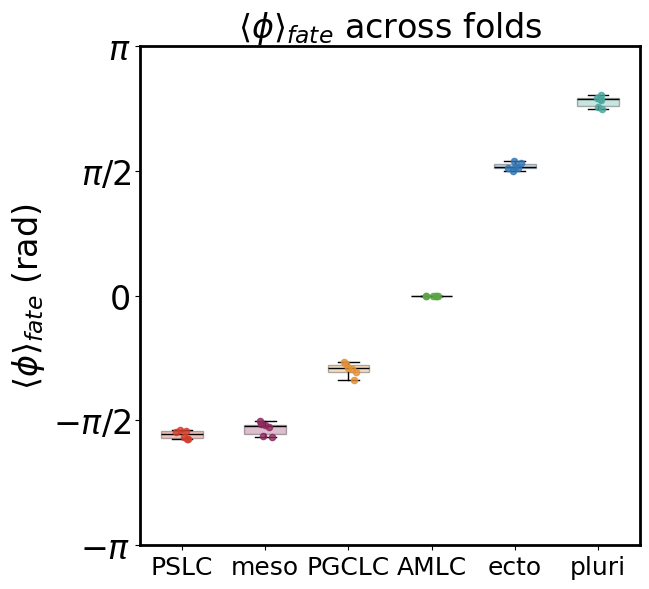

In [329]:
# ============================================================
# STEP 6b-d: Procrustes-align folds to fold 0, circular correlation, per-fate means
# (same analysis as Steps 1/3/5, across folds instead of seeds)
# ============================================================
fold0 = colony_idx[0]
ref_fold_std, _, _, _ = procrustes_align(L_fold_raw[fold0], L_fold_raw[fold0])
L_fold_aligned = {fold0: ref_fold_std}

fold_procrustes_report = []
for held_out in colony_idx:
    if held_out == fold0:
        continue
    _, aligned_src, reflected, disparity = procrustes_align(L_fold_raw[fold0], L_fold_raw[held_out])
    L_fold_aligned[held_out] = aligned_src
    fold_procrustes_report.append({'held_out_colony': held_out, 'reflected': reflected, 'disparity': disparity})

fold_procrustes_df = pd.DataFrame(fold_procrustes_report).set_index('held_out_colony')
print(fold_procrustes_df)
fold_procrustes_df.to_csv(LR_OUT + '/fold_procrustes_report.csv')

L_fold_aligned = {c: L_fold_aligned[c] @ R_to_checkpoint for c in L_fold_aligned}
phi_fold = {c: np.arctan2(L_fold_aligned[c][:, 1], L_fold_aligned[c][:, 0]) for c in colony_idx}

fold_circcorr_report = [{'held_out_colony': c, 'circular_corr': circ_corr(phi_fold[c], phi_fold[fold0])}
                         for c in colony_idx if c != fold0]
fold_circcorr_df = pd.DataFrame(fold_circcorr_report).set_index('held_out_colony')
print(fold_circcorr_df)
print(f"mean: {fold_circcorr_df['circular_corr'].mean():.4f}, std: {fold_circcorr_df['circular_corr'].std():.4f}")
fold_circcorr_df.to_csv(LR_OUT + '/fold_circular_correlation_vs_fold0.csv')

fold_fate_means = pd.DataFrame(index=colony_idx, columns=SIX_FATES, dtype=float)
for c in colony_idx:
    for fate in SIX_FATES:
        fold_fate_means.loc[c, fate] = circ_mean(phi_fold[c][fates == fate])

fold_orders = fold_fate_means.apply(circular_order, axis=1)
fold_reference_order = fold_orders.loc[fold0]
fold_order_matches = fold_orders.apply(lambda o: is_cyclic_rotation(o, fold_reference_order))
print(f"reference (fold {fold0}) fate order: {fold_reference_order}")
print(f"folds matching reference cyclic order: {fold_order_matches.sum()}/{len(colony_idx)}")
if not fold_order_matches.all():
    for c in fold_orders.index[~fold_order_matches]:
        print(f"  fold {c}: {fold_orders[c]}")

fold_fate_means_relative = pd.DataFrame(index=colony_idx, columns=SIX_FATES, dtype=float)
for c in colony_idx:
    for fate in SIX_FATES:
        fold_fate_means_relative.loc[c, fate] = circ_diff(fold_fate_means.loc[c, fate], fold_fate_means.loc[c, reference_fate])


plot_fate_circular_means(fold_fate_means_relative, SIX_FATES,
                          r'$\langle\phi\rangle_{fate}$ across folds',
                          LR_OUT + '/fold_fate_circular_means_relative.png',order_by_mean=True)


fold_fate_means.to_csv(LR_OUT + '/fold_fate_circular_means.csv')


circular correlation, held-out phi vs trained-on-folds phi: 0.9901
per-cell diff (deg): mean=-0.42, median abs=4.27, 90th pct abs=11.61


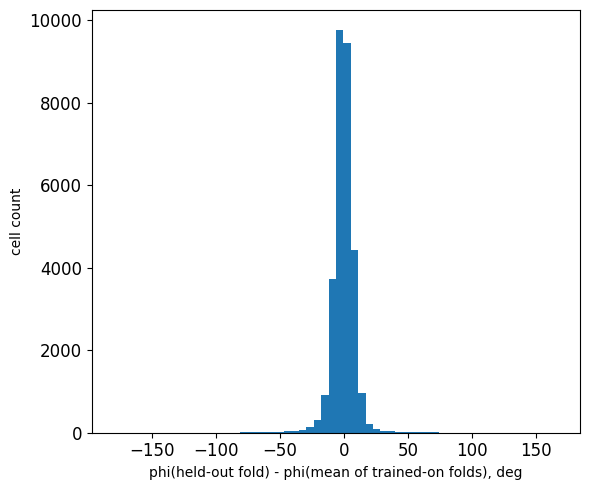

In [196]:
# ============================================================
# STEP 7: per-cell comparison -- phi from this cell's own held-out fold vs phi from the
# folds where this cell WAS part of the training set
# ============================================================
cell_colony = data.loc[mask, 'Colony'].to_numpy()
phi_heldout = np.full(len(cell_colony), np.nan)
phi_trained = np.full(len(cell_colony), np.nan)

for c in colony_idx:
    is_this_colony = (cell_colony == c)
    phi_heldout[is_this_colony] = phi_fold[c][is_this_colony]

    other_folds_phi = np.stack([phi_fold[oc][is_this_colony] for oc in colony_idx if oc != c], axis=1)
    Cc = np.mean(np.cos(other_folds_phi), axis=1)
    Sc = np.mean(np.sin(other_folds_phi), axis=1)
    phi_trained[is_this_colony] = np.arctan2(Sc, Cc)

step7_corr = circ_corr(phi_heldout, phi_trained)
step7_diff = circ_diff(phi_heldout, phi_trained)

print(f"circular correlation, held-out phi vs trained-on-folds phi: {step7_corr:.4f}")
print(f"per-cell diff (deg): mean={np.degrees(circ_mean(step7_diff)):.2f}, "
      f"median abs={np.degrees(np.median(np.abs(step7_diff))):.2f}, "
      f"90th pct abs={np.degrees(np.percentile(np.abs(step7_diff), 90)):.2f}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.hist(np.degrees(step7_diff), bins=60)
ax.set_xlabel('phi(held-out fold) - phi(mean of trained-on folds), deg')
ax.set_ylabel('cell count')
plt.tight_layout()
plt.savefig(LR_OUT + '/step7_heldout_vs_trained_diff.png')

pd.DataFrame({'colony': cell_colony, 'phi_heldout': phi_heldout, 'phi_trained': phi_trained,
              'diff_deg': np.degrees(step7_diff)}, index=cell_index).to_csv(LR_OUT + '/step7_percell.csv')


In [198]:
# ============================================================
# SUMMARY TABLE
# ============================================================
summary = pd.DataFrame({
    'metric': [
        'seed-vs-seed circular corr (mean, N=19)',
        'seed-vs-seed circular corr (std, N=19)',
        'seeds with reflection in Procrustes fit',
        'seeds matching reference fate cyclic order',
        'fold-vs-fold circular corr (mean, N=5)',
        'fold-vs-fold circular corr (std, N=5)',
        'folds with reflection in Procrustes fit',
        'folds matching reference fate cyclic order',
        'held-out-fold vs trained-on-folds circular corr (per-cell)',
    ],
    'value': [
        circcorr_df['circular_corr'].mean(), circcorr_df['circular_corr'].std(),
        f"{procrustes_df['reflected'].sum()}/{len(procrustes_df)}",
        f"{order_matches.sum()}/{N_seeds}",
        fold_circcorr_df['circular_corr'].mean(), fold_circcorr_df['circular_corr'].std(),
        f"{fold_procrustes_df['reflected'].sum()}/{len(fold_procrustes_df)}",
        f"{fold_order_matches.sum()}/{len(colony_idx)}",
        step7_corr,
    ]
})
print(summary.to_string(index=False))
summary.to_csv(LR_OUT + '/summary_table.csv', index=False)


                                                    metric     value
                   seed-vs-seed circular corr (mean, N=19)  0.974822
                    seed-vs-seed circular corr (std, N=19)  0.014107
                   seeds with reflection in Procrustes fit     11/19
                seeds matching reference fate cyclic order     16/20
                    fold-vs-fold circular corr (mean, N=5)  0.983829
                     fold-vs-fold circular corr (std, N=5)  0.001427
                   folds with reflection in Procrustes fit       4/5
                folds matching reference fate cyclic order       6/6
held-out-fold vs trained-on-folds circular corr (per-cell)  0.990072


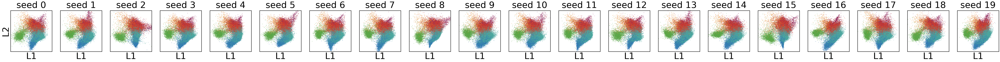

In [248]:
# ============================================================
# CHECK REPRODUCIBILITY OF LATENT SPACE, AFTER PROCRUSTES ALIGNMENT
# ============================================================
fs = 50
sw = 2
n = 1
m = N_seeds

L1_ref = L_aligned[0][:, 0]
L2_ref = L_aligned[0][:, 1]
L1mean, L2mean, L1std = L1_ref.mean(), L2_ref.mean(), L1_ref.std()
colors = [IIF.colmap_fates[f] for f in fates]

L_scaled_by_run = {run: ((L_aligned[run][:, 0] - L1mean) / L1std,
                          (L_aligned[run][:, 1] - L2mean) / L1std)
                    for run in range(N_seeds)}

all_L1 = np.concatenate([L_scaled_by_run[run][0] for run in range(N_seeds)])
all_L2 = np.concatenate([L_scaled_by_run[run][1] for run in range(N_seeds)])
xlim, ylim = square_percentile_limits(all_L1, all_L2)

fig, ax = plt.subplots(n, m, figsize=(5 * m, 5 * n))

for run in range(N_run):
    L1_scaled, L2_scaled = L_scaled_by_run[run]
    ax[run].scatter(L1_scaled, L2_scaled, c=colors, s=1)
    ax[run].set_xlabel('L1', fontsize=fs)
    if run == 0:
        ax[run].set_ylabel('L2', fontsize=fs)
    ax[run].set_xticks([]); ax[run].set_yticks([])
    ax[run].set_title('seed ' + str(run), fontsize=fs, pad=15)
    for spine in ax[run].spines.values():
        spine.set_linewidth(sw)
    ax[run].set_xlim(xlim); ax[run].set_ylim(ylim)
    ax[run].set_aspect('equal', adjustable='box')

fig.set_constrained_layout_pads(wspace=0.02, hspace=0.02, w_pad=0.0, h_pad=0.01)
plt.savefig(LR_OUT + '/LS_fate_reproducibility_aligned_' + str(len(signals)) + 'D.png', bbox_inches='tight')


In [219]:
# ============================================================
# SAVE ORIENTATION -- affine map from REF_SEED's own native mu to the common,
# checkpoint-aligned display space. Only valid for encodings from this exact model
# (modelws_{REF_SEED}_{len(signals)}D.pth) -- the transform is specific to its own
# native latent space.
# ============================================================
mu_ref_np = get_latent(vib[REF_SEED], data.loc[mask, signals])
L_ref_scaled_np = np.column_stack([
    (L_aligned[REF_SEED][:, 0] - L1mean) / L1std,
    (L_aligned[REF_SEED][:, 1] - L2mean) / L1std,
])
A_ref = np.hstack([mu_ref_np, np.ones((mu_ref_np.shape[0], 1))])
M_b_ref, *_ = np.linalg.lstsq(A_ref, L_ref_scaled_np, rcond=None)
M_ref, b_ref = M_b_ref[:2], M_b_ref[2]

np.savez(dataDir + f'/latent_orientation_seed{REF_SEED}_{len(signals)}D.npz',
         M=M_ref, b=b_ref, ref_seed=REF_SEED, signals=np.array(signals))
print(f"saved to {dataDir}/latent_orientation_seed{REF_SEED}_{len(signals)}D.npz")

# To reuse it in fig5 (or anywhere else), load it and apply directly to any mu computed by that same reference model:
# orientation = np.load(dataDir + f'/latent_orientation_seed{REF_SEED}_{len(signals)}D.npz')
# M_loaded, b_loaded = orientation['M'], orientation['b']
# # L_scaled = mu.cpu().numpy() @ M_loaded + b_loaded


saved to /Users/idse/data_tmp/signaldecoding/230121_data_BMPdoses/latent_orientation_seed0_5D.npz


In [200]:
similarity_report = []
for run in range(N_seeds):
    _, _, reflected, disparity = procrustes_align(L_checkpoint, L_raw[run])
    similarity_report.append({'seed': run, 'reflected': reflected, 'disparity': disparity})

similarity_df = pd.DataFrame(similarity_report).set_index('seed').sort_values('disparity')
print(similarity_df)
print(f"\nmost similar to the 6D reference: seed {similarity_df.index[0]} "
      f"(disparity={similarity_df['disparity'].iloc[0]:.4f})")


      reflected  disparity
seed                      
3          True   0.034866
10        False   0.036858
7          True   0.037832
6         False   0.038070
17        False   0.039071
14        False   0.039684
11         True   0.042940
9          True   0.044843
0          True   0.045492
13        False   0.045671
4         False   0.046660
12         True   0.051362
16         True   0.052859
18         True   0.053241
1         False   0.053379
5         False   0.053822
19         True   0.056136
8         False   0.081467
15        False   0.120689
2         False   0.147413

most similar to the 6D reference: seed 3 (disparity=0.0349)


In [285]:
# ============================================================
# EXTENSION: architecture and channel-addition robustness of phi, vs the existing
# n_layer=2/n_hidden=32 reference (REF_SEED). Reuses procrustes_align, circ_corr,
# circ_mean, circ_diff, circular_order, is_cyclic_rotation, get_latent -- all defined
# earlier, none rewritten here.
# ============================================================
signals = ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK']  # hardcoded, matches REF_SEED's model
hyperparam_reference = {'HIDDEN_DIM': 32, 'N_LAYERS': 2, 'LATENT_DIM': 2}
N_SEEDS_EXT = 5

def train_all_B50_ensemble(signals_this, hyperparam_this, N_seeds_this):
    """Train N_seeds_this VIB models on all B50 data (no held-out split -- for latent
    space / phi analysis only, not predictive evaluation), same pattern as the reference
    ensemble. Returns {seed: VIB instance}."""
    feat_train = data_cond[signals_this]
    tar_train = data_cond[gene_names]
    vib_dict = {}
    for s in range(N_seeds_this):
        torch.manual_seed(s)
        np.random.seed(s)
        if torch.backends.mps.is_available():
            torch.mps.manual_seed(s)
        vib_dict[s] = IIF.VIB(feat_train, tar_train, hyperparam_this)
        _ = vib_dict[s].train(verbose=False)
    return vib_dict

def cv_mse(signals_this, hyperparam_this, N_seeds_this):
    """Cross-validated (leave-one-colony-out) MSE, seed-averaged via sig2fate -- reuses
    the existing, already-fixed held-out prediction pipeline rather than reimplementing
    LOOCV training. pred_mean_df is explicitly reindexed to data_cond's row order before
    comparing, since sig2fate's groupby(level=0) averaging step sorts by index."""
    pred_mean_df, _ = IIF.sig2fate(data_cond, list(signals_this), gene_names, N_seeds_this, hyperparam_this)
    pred_aligned = pred_mean_df.loc[data_cond.index, gene_names].values
    true_vals = data_cond[gene_names].values
    return float(np.mean((pred_aligned - true_vals) ** 2))

def analyze_ensemble_vs_reference(vib_dict, signals_this, N_seeds_this, label):
    """For each seed's all-B50 model in vib_dict, Procrustes-align its raw latent to the
    existing reference (L_aligned[REF_SEED] -- the already fully-oriented reference
    frame, not L_raw[REF_SEED], since phi[REF_SEED] downstream is computed in that same
    oriented frame and circular correlation is only invariant to a shared rotation, not
    a mismatched one when the shared transform includes a reflection), compute phi, and
    report circular correlation vs phi[REF_SEED], per-fate circular means relative to
    reference_fate, and whether the fate cyclic order matches reference_order. Also
    flags, per mismatching seed, whether the mismatch is specifically the PSLC/meso
    near-tie already characterized in the seed analysis (checked as either a
    fixed-position swap or an adjacent-pair swap in the cyclic order -- the latter is
    needed since swapping two adjacent cyclic elements shifts every other position once
    rotated to a common start, so a naive fixed-position check can miss it).
    signals_this: the signal list this ensemble was trained with (only used to select
    columns for encoding the same B50 cells). Returns (result_df, fate_means_this,
    fate_means_relative_this)."""
    records = []
    fate_means_this = pd.DataFrame(index=range(N_seeds_this), columns=SIX_FATES, dtype=float)

    for s in range(N_seeds_this):
        L_raw_this = get_latent(vib_dict[s], data.loc[mask, signals_this])
        _, aligned, reflected, disparity = procrustes_align(L_aligned[REF_SEED], L_raw_this)
        phi_this = np.arctan2(aligned[:, 1], aligned[:, 0])
        corr = circ_corr(phi_this, phi[REF_SEED])

        for fate in SIX_FATES:
            fate_means_this.loc[s, fate] = circ_mean(phi_this[fates == fate])

        order = circular_order(fate_means_this.loc[s])
        order_ok = is_cyclic_rotation(order, reference_order)

        pslc_meso_flip = False
        if not order_ok:
            _, _, is_single_swap, swap_pair = find_order_diff(order, reference_order)
            if is_single_swap and swap_pair == tuple(sorted(['PSLC', 'meso'])):
                pslc_meso_flip = True
            else:
                adj_matched, adj_pair = find_adjacent_swap(order, reference_order)
                pslc_meso_flip = bool(adj_matched and adj_pair == tuple(sorted(['PSLC', 'meso'])))

        records.append({'seed': s, 'circular_corr': corr, 'reflected': reflected,
                         'disparity': disparity, 'order_matches': order_ok,
                         'pslc_meso_flip': pslc_meso_flip})

    fate_means_relative_this = pd.DataFrame(index=range(N_seeds_this), columns=SIX_FATES, dtype=float)
    for s in range(N_seeds_this):
        for fate in SIX_FATES:
            fate_means_relative_this.loc[s, fate] = circ_diff(fate_means_this.loc[s, fate],
                                                                fate_means_this.loc[s, reference_fate])

    result_df = pd.DataFrame(records).set_index('seed')
    print(f"--- {label} ---")
    print(result_df)
    print(f"mean circular corr: {result_df['circular_corr'].mean():.4f}, "
          f"std: {result_df['circular_corr'].std():.4f}")
    n_mismatch = (~result_df['order_matches']).sum()
    n_pslc_meso = int(result_df['pslc_meso_flip'].sum())
    print(f"order matches reference: {result_df['order_matches'].sum()}/{N_seeds_this} "
          f"(of {n_mismatch} mismatches, {n_pslc_meso} are the PSLC/meso near-tie)\n")

    return result_df, fate_means_this, fate_means_relative_this

def find_adjacent_swap(order, ref):
    """Check if order is a cyclic rotation of ref with exactly one ADJACENT pair (in the
    cyclic sequence) transposed -- e.g. ref=(A,B,C,D) with B,C swapped gives (A,C,B,D).
    Catches near-tied neighboring fates trading places, which a fixed-position
    transposition check (find_order_diff) misses, since swapping adjacent cyclic
    elements shifts every other position's alignment once rotated to a common start.
    Returns (matched, swap_pair)."""
    n = len(ref)
    for i in range(n):
        j = (i + 1) % n
        candidate = list(ref)
        candidate[i], candidate[j] = candidate[j], candidate[i]
        if is_cyclic_rotation(tuple(candidate), order):
            return True, tuple(sorted([ref[i], ref[j]]))
    return False, None


In [286]:
print('computing cross-validated MSE (full 5-signal reference model)...')
mse_full_reference = cv_mse(signals, hyperparam_reference, N_SEEDS_EXT)
print(f'full model cv MSE: {mse_full_reference:.4f}\n')

computing cross-validated MSE (full 5-signal reference model)...
  Run 0/5
Elapsed time: 18.409992933273315 seconds
  Run 1/5
Elapsed time: 18.816635847091675 seconds
  Run 2/5
Elapsed time: 18.84809398651123 seconds
  Run 3/5
Elapsed time: 17.70868420600891 seconds
  Run 4/5
Elapsed time: 17.415430068969727 seconds
full model cv MSE: 97945.5444



In [287]:
# Architectures

hyperparam_alt = {'HIDDEN_DIM': 16, 'N_LAYERS': 3, 'LATENT_DIM': 2}

print('training alt-architecture ensemble (all-B50, for latent/phi)...')
vib_alt = train_all_B50_ensemble(signals, hyperparam_alt, N_SEEDS_EXT)
alt_result_df, alt_fate_means, alt_fate_means_relative = analyze_ensemble_vs_reference(
    vib_alt, signals, N_SEEDS_EXT, 'n_layer=3, n_hidden=16 vs reference')

print('computing cross-validated MSE (alt architecture)...')
mse_alt = cv_mse(signals, hyperparam_alt, N_SEEDS_EXT)
delta_mse_alt = mse_alt - mse_full_reference
print(f'alt architecture cv MSE: {mse_alt:.4f} (delta vs reference: {delta_mse_alt:+.4f})')


training alt-architecture ensemble (all-B50, for latent/phi)...
--- n_layer=3, n_hidden=16 vs reference ---
      circular_corr  reflected  disparity  order_matches  pslc_meso_flip
seed                                                                    
0          0.973595       True   0.035784           True           False
1          0.917658      False   0.119531          False            True
2          0.884924       True   0.149141          False            True
3          0.981065      False   0.046723           True           False
4          0.973691       True   0.042323          False            True
mean circular corr: 0.9462, std: 0.0427
order matches reference: 2/5 (of 3 mismatches, 3 are the PSLC/meso near-tie)

computing cross-validated MSE (alt architecture)...
  Run 0/5
Elapsed time: 21.281233072280884 seconds
  Run 1/5
Elapsed time: 20.53352117538452 seconds
  Run 2/5
Elapsed time: 20.744573831558228 seconds
  Run 3/5
Elapsed time: 20.798968076705933 seconds
  Run 4/

In [289]:
# channel addition

left_out_signals = ['cytopAKT', 'ncSMAD2', 'BCat']  # pAKT, SMAD2, BCat
all_8_signals = signals + left_out_signals

addition_configs = {f'+{s}': signals + [s] for s in left_out_signals}
addition_configs['all 8 signals'] = all_8_signals

vib_by_config = {}
addition_results = {}
addition_fate_means_relative = {}
addition_mse = {}

for label, signal_set in addition_configs.items():
    print(f'--- {label} ---')

    vib_by_config[label] = train_all_B50_ensemble(signal_set, hyperparam_reference, N_SEEDS_EXT)
    result_df, fate_means_a, fate_means_relative_a = analyze_ensemble_vs_reference(
        vib_by_config[label], signal_set, N_SEEDS_EXT, f'{label} vs reference')

    mse_a = cv_mse(signal_set, hyperparam_reference, N_SEEDS_EXT)
    delta_mse = mse_a - mse_full_reference
    print(f'cv MSE for {label}: {mse_a:.4f} (delta vs 5-signal reference: {delta_mse:+.4f})\n')

    addition_results[label] = result_df
    addition_fate_means_relative[label] = fate_means_relative_a
    addition_mse[label] = {'mse': mse_a, 'delta_mse': delta_mse}


--- +cytopAKT ---
--- +cytopAKT vs reference ---
      circular_corr  reflected  disparity  order_matches  pslc_meso_flip
seed                                                                    
0          0.985690       True   0.033202           True           False
1          0.972601       True   0.043235           True           False
2          0.969464       True   0.054790           True           False
3          0.956366       True   0.050141           True           False
4          0.975796      False   0.036974           True           False
mean circular corr: 0.9720, std: 0.0106
order matches reference: 5/5 (of 0 mismatches, 0 are the PSLC/meso near-tie)

  Run 0/5
Elapsed time: 17.64453887939453 seconds
  Run 1/5
Elapsed time: 17.211568117141724 seconds
  Run 2/5
Elapsed time: 17.7415189743042 seconds
  Run 3/5
Elapsed time: 17.156282901763916 seconds
  Run 4/5
Elapsed time: 17.015637159347534 seconds
cv MSE for +cytopAKT: 96657.4035 (delta vs 5-signal reference: -1288.1

                                                        config  mean_circular_corr  std_circular_corr order_matches  pslc_meso_flips       cv_mse  delta_mse_vs_reference
reference (5 signals: pSMAD1, ncYAP, LEF1, ncSMAD23, cytopERK)            1.000000           0.000000           5/5                0 97945.544360                0.000000
                     alt architecture (n_layer=3, n_hidden=16)            0.946187           0.042694           2/5                3 99363.486778             1417.942418
                                                     +cytopAKT            0.971983           0.010642           5/5                0 96657.403488            -1288.140871
                                                      +ncSMAD2            0.977459           0.006062           5/5                0 94710.217539            -3235.326821
                                                         +BCat            0.968575           0.022700           4/5                1 96473.392615     

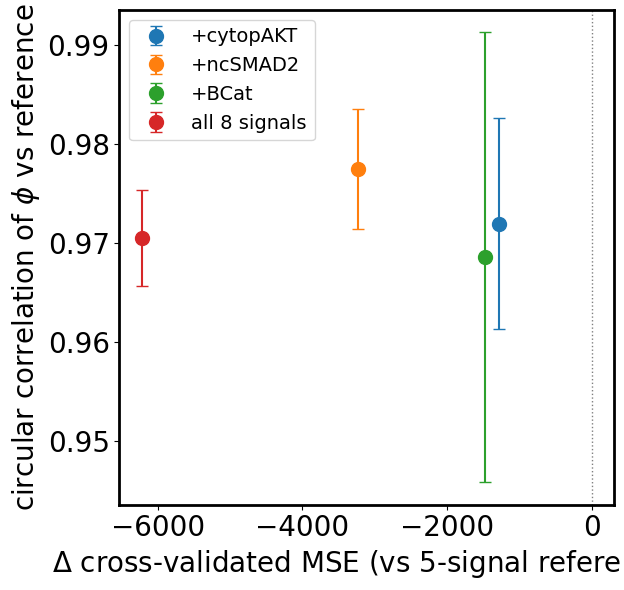

In [290]:
# results

# plot
fs = 20
sw = 2
fig, ax = plt.subplots(figsize=(7, 6))

for label in addition_configs:
    corr_vals = addition_results[label]['circular_corr'].values
    corr_mean = corr_vals.mean()
    corr_std = corr_vals.std(ddof=1)
    delta = addition_mse[label]['delta_mse']
    ax.errorbar(delta, corr_mean, yerr=corr_std, fmt='o', markersize=10, capsize=4, label=label)

ax.axvline(0, color='gray', linestyle=':', linewidth=1)
ax.set_xlabel(r'$\Delta$ cross-validated MSE (vs 5-signal reference)', fontsize=fs)
ax.set_ylabel('circular correlation of $\\phi$ vs reference', fontsize=fs)
ax.tick_params(labelsize=fs)
ax.legend(fontsize=fs * 0.7)
for spine in ax.spines.values():
    spine.set_linewidth(sw)
ax.set_box_aspect(1)
plt.tight_layout()
plt.savefig(LR_OUT + '/addition_circcorr_vs_deltaMSE.png')

# table
summary_records = [{
    'config': 'reference (5 signals: pSMAD1, ncYAP, LEF1, ncSMAD23, cytopERK)',
    'mean_circular_corr': 1.0, 'std_circular_corr': 0.0,
    'order_matches': f'{N_SEEDS_EXT}/{N_SEEDS_EXT}', 'pslc_meso_flips': 0,
    'cv_mse': mse_full_reference, 'delta_mse_vs_reference': 0.0,
}, {
    'config': 'alt architecture (n_layer=3, n_hidden=16)',
    'mean_circular_corr': alt_result_df['circular_corr'].mean(),
    'std_circular_corr': alt_result_df['circular_corr'].std(),
    'order_matches': f"{alt_result_df['order_matches'].sum()}/{N_SEEDS_EXT}",
    'pslc_meso_flips': int(alt_result_df['pslc_meso_flip'].sum()),
    'cv_mse': mse_alt, 'delta_mse_vs_reference': delta_mse_alt,
}]

for label in addition_configs:
    df = addition_results[label]
    summary_records.append({
        'config': label,
        'mean_circular_corr': df['circular_corr'].mean(),
        'std_circular_corr': df['circular_corr'].std(),
        'order_matches': f"{df['order_matches'].sum()}/{N_SEEDS_EXT}",
        'pslc_meso_flips': int(df['pslc_meso_flip'].sum()),
        'cv_mse': addition_mse[label]['mse'],
        'delta_mse_vs_reference': addition_mse[label]['delta_mse'],
    })

summary_df = pd.DataFrame(summary_records)
print(summary_df.to_string(index=False))
summary_df.to_csv(LR_OUT + '/extension_summary_table.csv', index=False)


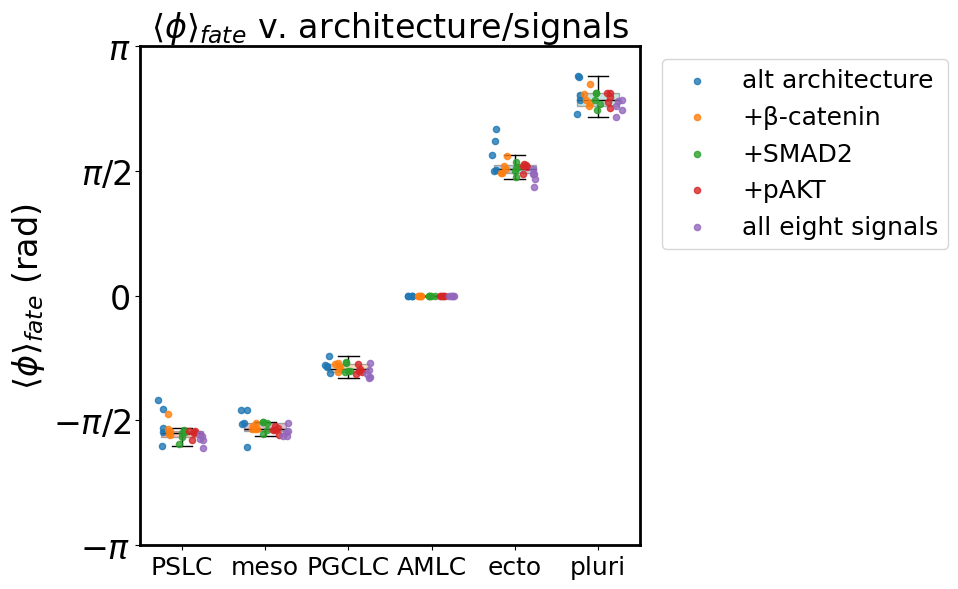

In [330]:
plot_fate_circular_means_by_variant(variant_dfs, SIX_FATES,
                                     r'$\langle\phi\rangle_{fate}$ v. architecture/signals',
                                     LR_OUT + '/fate_circular_means_relative_by_variant.png',order_by_mean=True)


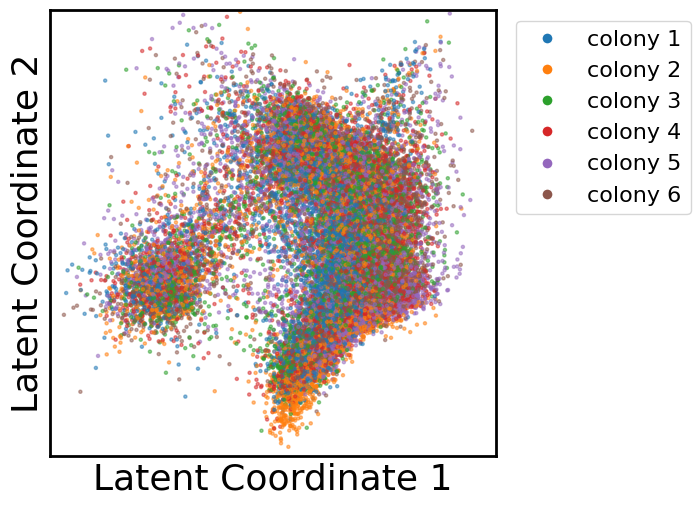

In [333]:
#latent space colored by colony

fs = 26
sw = 2
s = 5
alpha = 0.5

L1_scaled = (L_aligned[REF_SEED][:, 0] - L1mean) / L1std
L2_scaled = (L_aligned[REF_SEED][:, 1] - L2mean) / L1std

colonies_this = data.loc[mask, 'Colony'].values
colony_ids = np.unique(colonies_this)
colony_colors = dict(zip(colony_ids, plt.cm.tab10.colors[:len(colony_ids)]))

rng = np.random.default_rng(0)
shuffle_idx = rng.permutation(len(L1_scaled))
point_colors = np.array([colony_colors[c] for c in colonies_this])[shuffle_idx]

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
ax.scatter(L1_scaled[shuffle_idx], L2_scaled[shuffle_idx], s=s, alpha=alpha, color=point_colors)

ax.set_xlabel('Latent Coordinate 1', fontsize=fs)
ax.set_ylabel('Latent Coordinate 2', fontsize=fs)
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_linewidth(sw)

marg = 0.5
xlim = (np.percentile(L1_scaled, 0.1) - marg, np.percentile(L1_scaled, 99.9) + marg)
ylim = (np.percentile(L2_scaled, 0.1) - marg, np.percentile(L2_scaled, 99.9) + marg)
x_range, y_range = xlim[1] - xlim[0], ylim[1] - ylim[0]
max_range = max(x_range, y_range)
x_center, y_center = (xlim[0] + xlim[1]) / 2, (ylim[0] + ylim[1]) / 2
ax.set_xlim(x_center - max_range / 2, x_center + max_range / 2)
ax.set_ylim(y_center - max_range / 2, y_center + max_range / 2)
ax.set_aspect('equal', adjustable='box')

from matplotlib.lines import Line2D
legend_handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=colony_colors[c],
                          markersize=8, label=f'colony {c}') for c in colony_ids]
ax.legend(handles=legend_handles, loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=fs - 10)

plt.tight_layout(pad=0.5)
plt.savefig(LR_OUT + '/latent_space_by_colony.png', bbox_inches='tight')


colonies matching reference cyclic order: 5/6
  colony 1: adjacent swap PSLC <-> meso
    colony_1  colony_2  circular_corr_of_fate_means
0          1         2                     0.967077
1          1         3                     0.500991
2          1         4                     0.591733
3          1         5                     0.809896
4          1         6                     0.423335
5          2         3                     0.700530
6          2         4                     0.771446
7          2         5                     0.928515
8          2         6                     0.634717
9          3         4                     0.993291
10         3         5                     0.912246
11         3         6                     0.994679
12         4         5                     0.951036
13         4         6                     0.979728
14         5         6                     0.872377
mean pairwise fate-level circular corr across colonies: 0.8021
   AMLC     PGCLC  

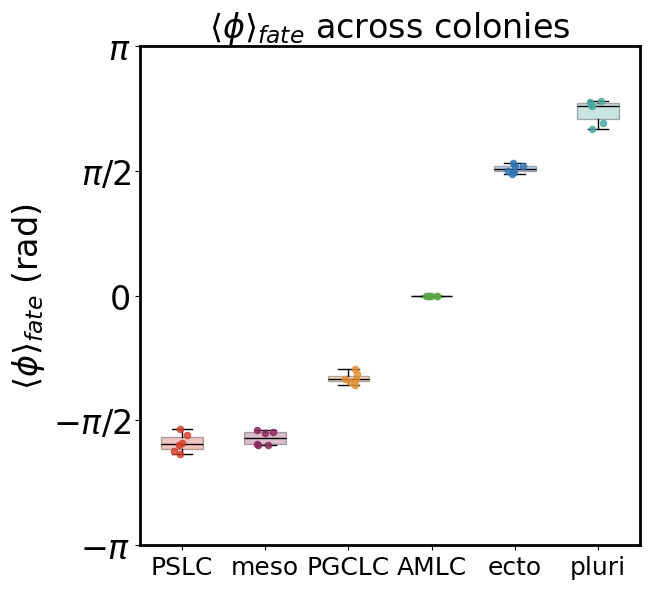

In [343]:
# Per-colony fate circular means (no retraining/alignment — same seed-0 model, same phi[REF_SEED], just split by colony)


colony_fate_means = pd.DataFrame(index=colony_ids, columns=SIX_FATES, dtype=float)
for c in colony_ids:
    colony_mask = (colonies_this == c)
    for fate in SIX_FATES:
        colony_fate_means.loc[c, fate] = circ_mean(phi[REF_SEED][(fates == fate) & colony_mask])

colony_fate_means_relative = pd.DataFrame(index=colony_ids, columns=SIX_FATES, dtype=float)
for c in colony_ids:
    for fate in SIX_FATES:
        colony_fate_means_relative.loc[c, fate] = circ_diff(colony_fate_means.loc[c, fate],
                                                              colony_fate_means.loc[c, reference_fate])

# panel B
plot_fate_circular_means(colony_fate_means_relative, SIX_FATES,
                          r'$\langle\phi\rangle_{fate}$ across colonies',
                          LR_OUT + '/fate_circular_means_relative_by_colony.png', order_by_mean=True)


colony_orders = colony_fate_means.apply(circular_order, axis=1)
colony_order_matches = colony_orders.apply(lambda o: is_cyclic_rotation(o, reference_order))
print(f"colonies matching reference cyclic order: {colony_order_matches.sum()}/{len(colony_ids)}")
for c in colony_orders.index[~colony_order_matches]:
    matched, swap_pair = find_adjacent_swap(colony_orders[c], reference_order)
    if matched:
        print(f"  colony {c}: adjacent swap {swap_pair[0]} <-> {swap_pair[1]}")
    else:
        print(f"  colony {c}: order={colony_orders[c]} -- not explained by a simple adjacent swap")

from itertools import combinations

colony_pair_corr = []
for c1, c2 in combinations(colony_ids, 2):
    corr = circ_corr(colony_fate_means.loc[c1].values.astype(float), colony_fate_means.loc[c2].values.astype(float))
    colony_pair_corr.append({'colony_1': c1, 'colony_2': c2, 'circular_corr_of_fate_means': corr})

colony_pair_corr_df = pd.DataFrame(colony_pair_corr)
print(colony_pair_corr_df)
print(f"mean pairwise fate-level circular corr across colonies: {colony_pair_corr_df['circular_corr_of_fate_means'].mean():.4f}")


print(colony_fate_means_relative)

spread_comparison = pd.DataFrame({
    'seed_to_seed': {f: circ_std(fate_means_relative[f].values.astype(float), axis=0) for f in SIX_FATES},
    'fold_to_fold': {f: circ_std(fold_fate_means_relative[f].values.astype(float), axis=0) for f in SIX_FATES},
    'colony_to_colony': {f: circ_std(colony_fate_means_relative[f].values.astype(float), axis=0) for f in SIX_FATES},
})
print("\ncircular std (rad) per fate, by source of variation:")
print(spread_comparison)
spread_comparison.to_csv(LR_OUT + '/spread_comparison_seed_fold_colony.csv')


#### Visualize latent space

In [10]:
# VISUALIZE LATENT SPACE
N_run = 20
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 2}
signals = ['pSMAD1', 'ncYAP', 'LEF1', 'ncSMAD23', 'cytopERK']
genes = gene_names
run = 3

cond = 'B50'
data_cond = data[data['condition']==cond]

model = vib[run].model
mask = (data['condition'] == cond)

X = vib[run].scaler_X_run.transform(data.loc[mask, signals])
X = torch.FloatTensor(X).to(device)

# 2D model
model.eval() 
with torch.no_grad():
    mu, _ = model.encode(X)
    Y = model.decode(mu).cpu().numpy()
    Y = vib[run].scaler_Y_run.inverse_transform(Y)
    Y = pd.DataFrame(Y, columns=gene_names, index=data[mask].index)

L1_ref = L_aligned[REF_SEED][:, 0]
L2_ref = L_aligned[REF_SEED][:, 1]
L1mean = L1_ref.mean()
L2mean = L2_ref.mean()
L1std = L1_ref.std()

L1_scaled = (L_aligned[run][:, 0] - L1mean) / L1std
L2_scaled = (L_aligned[run][:, 1] - L2mean) / L1std

L1_scaled = pd.Series(L1_scaled, index=data[mask].index)
L2_scaled = pd.Series(L2_scaled, index=data[mask].index)


#=============PLOT=================

fs=26
sw = 2
n=1
m=1
s = 5
alpha = 0.5

for colorfor in ['exp','pred'] + signals + markers:

    fig, ax = plt.subplots(n, m, figsize=(5*m, 5*n))

    if colorfor == 'exp':
        fates,_ = IIF.return_fates(data[mask],thresh=thresh)
        colors = [IIF.colmap_fates[f] for f in fates]
        ax.scatter(L1_scaled, L2_scaled,c=colors, s=s, alpha=alpha)
    elif colorfor == 'pred':
        fates_pred,_ = IIF.return_fates(Y,thresh=thresh)
        colors = [IIF.colmap_fates[f] for f in fates_pred]
        ax.scatter(L1_scaled, L2_scaled,c=colors, s=s, alpha=alpha)
    else:
        colors = data.loc[mask, colorfor]
        order = colors.sort_values().index
        tol=(0.05,99.5)
        vmin = np.percentile(colors, tol[0])
        vmax = np.percentile(colors, tol[1])
        ax.scatter(L1_scaled[order], L2_scaled[order],c=colors[order], s=s, cmap='YlGnBu',vmin=vmin,vmax=vmax, alpha=alpha)
    
    ax.set_xlabel('Latent Coordinate 1',fontsize=fs)
    ax.set_ylabel('Latent Coordinate 2',fontsize=fs)
    ax.set_xticks([]);
    ax.set_yticks([]);
    
    for spine in ax.spines.values():
        spine.set_linewidth(sw)

    # Make plot square by extending axis limits without changing aspect ratio
    marg = 0.5
    xlim = (np.percentile(L1_scaled, 0.1) - marg, np.percentile(L1_scaled, 99.9) + marg)
    ylim = (np.percentile(L2_scaled, 0.1) - marg, np.percentile(L2_scaled, 99.9) + marg)
    
    # xlim = (L1_scaled.min(), L1_scaled.max()) #ax[run].get_xlim()
    # ylim = (L2_scaled.min(), L2_scaled.max()) #ax[run].get_ylim() 
    
    x_range = xlim[1] - xlim[0]
    y_range = ylim[1] - ylim[0]
    
    # Find the larger range
    max_range = max(x_range, y_range)
    
    # Calculate centers
    x_center = (xlim[0] + xlim[1]) / 2
    y_center = (ylim[0] + ylim[1]) / 2
    
    L1smin = x_center - max_range/2
    L1smax = x_center + max_range/2
    L2smin = y_center - max_range/2
    L2smax = y_center + max_range/2
    
    # Set new limits centered around the data with equal range
    ax.set_xlim(L1smin, L1smax)
    ax.set_ylim(L2smin, L2smax)
    
    ax.set_aspect('equal', adjustable='box')
    plt.tight_layout(pad=0.5)
    
    plt.savefig(dataDir+'/Fig3/LS_fate_' + str(len(signals)) + 'D' + '_run' + str(run) + '_' + colorfor+'.png')

NameError: name 'L_aligned' is not defined

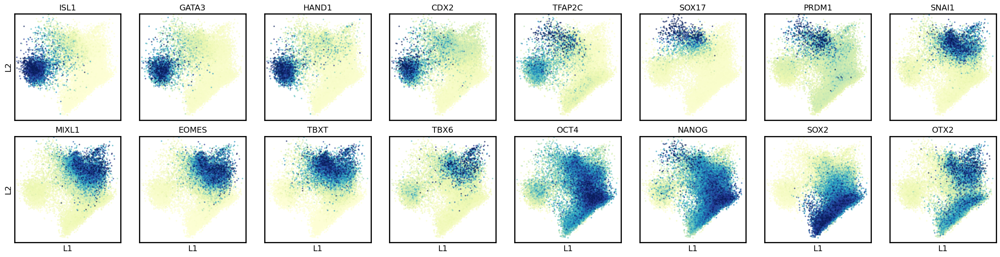

In [458]:
# ============================================================
# VISUALIZE LATENT SPACE -- all 16 fate markers in one combined figure (2 rows x 8 cols)
# Run this after the main VISUALIZE LATENT SPACE cell -- reuses its L1_scaled/L2_scaled
# and the square axis limits (L1smin/L1smax/L2smin/L2smax) already established there.
# ============================================================
fs = 14
sw = 2
s = 3
alpha = 0.5
tol = (0.05, 99.5)

fig, axs = plt.subplots(2, 8, figsize=(8 * 3, 2 * 3), constrained_layout=True)

axs = axs.ravel()

L1_scaled = (L_aligned[run][:, 0] - L1mean) / L1std
L2_scaled = (L_aligned[run][:, 1] - L2mean) / L1std
L1_scaled = pd.Series(np.asarray(L1_scaled), index=data[mask].index)
L2_scaled = pd.Series(np.asarray(L2_scaled), index=data[mask].index)


for i, marker in enumerate(gene_names):
    ax = axs[i]
    colors = data.loc[mask, marker]
    order = colors.sort_values().index
    vmin = np.percentile(colors, tol[0])
    vmax = np.percentile(colors, tol[1])
    ax.scatter(L1_scaled[order], L2_scaled[order], c=colors[order], s=s, cmap='YlGnBu',
               vmin=vmin, vmax=vmax, alpha=alpha)

    ax.set_title(marker, fontsize=fs)
    ax.set_xticks([]); ax.set_yticks([])
    if i % 8 == 0:
        ax.set_ylabel('L2', fontsize=fs)
    if i >= 8:
        ax.set_xlabel('L1', fontsize=fs)
    for spine in ax.spines.values():
        spine.set_linewidth(sw)

    ax.set_xlim(L1smin, L1smax)
    ax.set_ylim(L2smin, L2smax)
    ax.set_aspect('equal', adjustable='box')


fig.set_constrained_layout_pads(hspace=0.05, wspace=0.02, h_pad=0.02, w_pad=0.02)

plt.savefig(dataDir+'/Fig3/LS_fate_' + str(len(signals)) + 'D' + '_run' + str(run) + '_all_markers.png',
            dpi=150, bbox_inches='tight')


In [459]:
# EXTRAPOLATE FATE MAP
run = 3

X = vib[run].scaler_X_run.transform(data.loc[mask, signals])
X = torch.FloatTensor(X).to(device)
model = vib[run].model
model.eval()
with torch.no_grad():
    mu, _ = model.encode(X)

L1_scaled = (L_aligned[run][:, 0] - L1mean) / L1std
L2_scaled = (L_aligned[run][:, 1] - L2mean) / L1std

l1 = np.linspace(L1smin, L1smax, 200)
l2 = np.linspace(L2smin, L2smax, 200)
L1grid_scaled, L2grid_scaled = np.meshgrid(l1, l2)

mu_np = mu.cpu().numpy()
L_scaled_np = np.column_stack([np.asarray(L1_scaled), np.asarray(L2_scaled)])

A = np.hstack([mu_np, np.ones((mu_np.shape[0], 1))])
M_b, *_ = np.linalg.lstsq(A, L_scaled_np, rcond=None)
M, b = M_b[:2], M_b[2]
M_inv = np.linalg.inv(M)

grid_scaled = np.column_stack([L1grid_scaled.ravel(), L2grid_scaled.ravel()])
mugrid = (grid_scaled - b) @ M_inv
mugrid = torch.FloatTensor(mugrid).to(device)

with torch.no_grad():
    Y = model.decode(mugrid).cpu().numpy()
    Y = vib[run].scaler_Y_run.inverse_transform(Y)
    Y = pd.DataFrame(Y, columns=gene_names)

fates, _ = IIF.return_fates(Y, thresh=thresh)


99.0% of data points are inside the contours


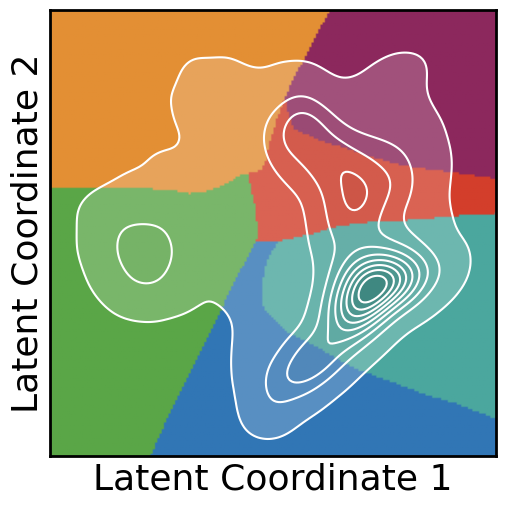

In [361]:
#--------PLOT FATE MAP--------------

fs=26
sw = 2
n=1
m=1
s = 5

# L1_scaled = (L1grid - L1.mean())/L1grid.std()
# L2_scaled = (L2grid - L2.mean())/L1grid.std()    
# colors = [IIF.colmap_fates[f] for f in fates]
# plt.scatter(L1_scaled, L2_scaled,c=colors, s=s)

rgb_image = np.zeros((200, 200, 3))

for i, fate in enumerate(fates):
    color = IIF.colmap_fates[fate]
    rgb = mcolors.to_rgb(color) # Convert color to RGB tuple (values between 0-1)
    rgb_image[i // 200, i % 200] = rgb

fig, ax = plt.subplots(n, m, figsize=(5*m, 5*n))
ax.imshow(rgb_image, origin='lower', extent=[L1smin, L1smax, L2smin, L2smax])

#ax.scatter(L1_scaled, L2_scaled,c='k', s=5, alpha=0.1)

# Calculate KDE for the scatter points
if len(L1_scaled) > 1:  # Need at least 2 points for KDE
    # Create KDE
    values = np.vstack([L1_scaled, L2_scaled])
    kernel = sp.stats.gaussian_kde(values)
    
    # Evaluate KDE at the actual data points
    kde_at_data = kernel(values)
    
    # Set vmin so that X% of data points are outside the contours
    data_percentile = 1  # Change this: 10 means 10% of data outside, 90% inside
    vmin = np.percentile(kde_at_data, data_percentile)
    
    # Evaluate KDE on a grid
    kde_grid = kernel(np.vstack([L1grid_scaled.ravel(), L2grid_scaled.ravel()]))
    kde_grid = kde_grid.reshape(L1grid_scaled.shape)
    
    # Define levels from vmin to max
    vmax = kde_grid.max()
    levels = np.linspace(vmin, vmax, 10)
    
    # Verify
    fraction_inside = np.sum(kde_at_data >= vmin) / len(L1_scaled)
    print(f"{fraction_inside*100:.1f}% of data points are inside the contours")
    
    ax.contourf(L1grid_scaled, L2grid_scaled, kde_grid, 
                levels=levels, cmap='Greys', alpha=0.2)
    ax.contour(L1grid_scaled, L2grid_scaled, kde_grid, 
               levels=levels, colors='white', linewidths=1.5)
    
    
ax.set_xlabel('Latent Coordinate 1',fontsize=fs)
ax.set_ylabel('Latent Coordinate 2',fontsize=fs)
ax.set_xticks([]);
ax.set_yticks([]);

for spine in ax.spines.values():
    spine.set_linewidth(sw)

ax.set_aspect('equal', adjustable='box')
plt.tight_layout(pad=0.5)

plt.savefig(dataDir+'/Fig3/LS_fate_'  + str(len(signals))  + 'D' + '_run' + str(run)  + '_extrapolated_r.png', dpi=150, bbox_inches='tight', pad_inches=0.1)

# save fate map variables
np.save(dataDir + '/fatemap_L1grid_scaled.npy', L1grid_scaled)
np.save(dataDir + '/fatemap_L2grid_scaled.npy', L2grid_scaled)
np.save(dataDir + '/fatemap_fates.npy', np.array(fates))
np.save(dataDir + '/fatemap_limits.npy', np.array([L1smin, L1smax, L2smin, L2smax]))
np.save(dataDir + '/fatemap_L1mean_L1std.npy', np.array([L1mean, L1std]))
np.save(dataDir + '/fatemap_L2mean.npy', np.array([L2mean]))

### Establish polar coordinates on latent space

In [7]:
#=============FIND CENTER WHERE 3 SPECIFIC FATES MEET=================

import numpy as np
from scipy.stats import gaussian_kde

# ===== SPECIFY YOUR 3 FATES HERE =====
target_fates = ['ecto', 'AMLC', 'PSLC']  # CHANGE THESE TO YOUR DESIRED FATES
# ======================================

def findFateJunction(target_fates):
    
    print(f"Finding junction of: {target_fates}")
    
    # Use EXACT same grid as used to compute fates
    l1_grid = np.linspace(L1smin, L1smax, 200)
    l2_grid = np.linspace(L2smin, L2smax, 200)
    
    # Get the fate map on the grid
    fates_grid = np.array(fates).reshape(200, 200)
    
    # Check what fates are available
    unique_fates = list(set(fates))
    print(f"Available fates in grid: {unique_fates}")
    
    # Verify all target fates exist
    for fate in target_fates:
        if fate not in unique_fates:
            print(f"WARNING: {fate} not found in fate map!")
    
    # Find pixels that are adjacent to all 3 specified fates
    tri_junction_candidates = []
    
    for i in range(1, 199):
        for j in range(1, 199):
            neighborhood = fates_grid[i-1:i+2, j-1:j+2].ravel()
            neighborhood_fates = set(neighborhood)
            if all(fate in neighborhood_fates for fate in target_fates):
                tri_junction_candidates.append((i, j))
    
    print(f"Found {len(tri_junction_candidates)} tri-junction candidate pixels")
    
    if len(tri_junction_candidates) > 0:
        tri_junction_candidates = np.array(tri_junction_candidates)
        
        latent_candidates = []
        for i, j in tri_junction_candidates:
            lat1 = l1_grid[j]  # j is x (L1)
            lat2 = l2_grid[i]  # i is y (L2)
            latent_candidates.append([lat1, lat2])
        
        latent_candidates = np.array(latent_candidates)
        center_x = latent_candidates[:, 0].mean()
        center_y = latent_candidates[:, 1].mean()
        
        print(f"Tri-junction center: ({center_x:.4f}, {center_y:.4f})")
        return center_x, center_y

    else:
        print(f"No junction found for fates: {target_fates}!")
        return None, None


#=============COMPUTE POLAR COORDINATES=================

# Compute initial polar coordinates
center_x, center_y = findFateJunction(target_fates)
x_centered = L1_scaled - center_x
y_centered = L2_scaled - center_y
r = np.sqrt(x_centered**2 + y_centered**2)
theta_raw = np.arctan2(y_centered, x_centered)

#=============FIND AND FIX BRANCH CUT=================

print("Finding optimal branch cut location...")

angles_to_test = np.linspace(-np.pi, np.pi, 180)
densities = []

for angle in angles_to_test:
    angle_diff = np.abs(((theta_raw - angle + np.pi) % (2*np.pi)) - np.pi)
    points_in_wedge = np.sum(angle_diff < 0.1)
    densities.append(points_in_wedge)

densities = np.array(densities)

gap_angle = angles_to_test[np.argmin(densities)]
print(f"Gap detected at angle: {gap_angle:.3f} radians ({np.degrees(gap_angle):.1f} degrees)")

gap_angle = -2 # manually adjust based on what was found

# Rotate angles so the gap is at ±π and reverse direction
theta_corrected = -(theta_raw - gap_angle + np.pi)

# Wrap to [-π, π]
theta_corrected = np.arctan2(np.sin(theta_corrected), np.cos(theta_corrected))

print(f"Branch cut placed at ±π (gap was at {gap_angle:.3f} radians), angle reversed")
np.save(dataDir + '/fatemap_tri_junction_center.npy', np.array([center_x, center_y]))


Finding junction of: ['ecto', 'AMLC', 'PSLC']


NameError: name 'L1smin' is not defined

### Fit latent coordinates as a function of input signals directly

In [461]:
from scipy.optimize import minimize
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score

def pack(v1, v2):
    return np.concatenate([v1, v2])

def unpack(params):
    v1 = params[:n_signals]
    v2 = params[n_signals:]
    return v1, v2

def orthogonality_constraint(params):
    v1, v2 = unpack(params)
    return np.dot(v1, v2)

def loss_direct(params):
    w1, w2 = unpack(params)
    res1 = L1_c - X_c @ w1
    res2 = L2_c - X_c @ w2
    return np.mean(res1**2) + np.mean(res2**2)


# ============================================================
# CONSTRAINED OPTIMIZATION: find two orthogonal vectors
# in signal space that directly predict L1 and L2
# (centered, no unit norm constraint, no post-hoc rescaling)
# ============================================================

run = 3
vib_choice = vib[run]

n_signals = len(signals)
mask = (data['condition'] == cond)
X_signals_z = vib_choice.scaler_X_run.transform(data.loc[mask, signals])
X_signals_z = torch.FloatTensor(X_signals_z).cpu().to(device)

model = vib_choice.model
model.eval() 
with torch.no_grad():
    mu, _ = model.encode(X_signals_z)
L1 = mu[:, 0].cpu().numpy()
L2 = mu[:, 1].cpu().numpy()

# center everything
L1_c = L1 - L1.mean()
L2_c = L2 - L2.mean()
X_signals_z_np = X_signals_z.cpu().numpy()
X_c = X_signals_z_np - X_signals_z_np.mean(axis=0)

# convert to float64 for scipy
L1_c = L1_c.astype(np.float64)
L2_c = L2_c.astype(np.float64)
X_c  = X_c.astype(np.float64)


# initialize from regression solution, orthogonalized
from sklearn.linear_model import LinearRegression
w1_init = LinearRegression().fit(X_c, L1_c).coef_
w2_init = LinearRegression().fit(X_c, L2_c).coef_

# also ensure init vectors are float64
w1_init = w1_init.astype(np.float64)
w2_init = w2_init.astype(np.float64)
v_init  = pack(w1_init, w2_init)



constraints_direct = [
    {'type': 'eq', 'fun': orthogonality_constraint},
]


# orthogonalize init to satisfy constraint at start
w2_init = w2_init - np.dot(w2_init, w1_init) / np.dot(w1_init, w1_init) * w1_init
v_init = pack(w1_init, w2_init)

# multiple restarts to avoid local minima
best_result = None
best_loss = np.inf

n_restarts = 20
for i in range(n_restarts):

    if i == 0:
        v0 = v_init  # first try: regression initialization
    else:
        # random initialization: random orthogonal vectors scaled like data
        A = np.random.randn(n_signals, 2) * np.std(w1_init)
        Q, R = np.linalg.qr(A)
        # scale columns to roughly match regression solution
        Q[:, 0] *= np.linalg.norm(w1_init)
        Q[:, 1] *= np.linalg.norm(w2_init)
        v0 = pack(Q[:, 0], Q[:, 1])

    res = minimize(loss_direct, v0, constraints=constraints_direct, method='SLSQP',
                   options={'ftol': 1e-12, 'maxiter': 10000})

    if res.fun < best_loss:
        best_loss = res.fun
        best_result = res

w1_opt, w2_opt = unpack(best_result.x)

print(f'Optimization success: {best_result.success}')
print(f'Final loss: {best_result.fun:.4f}')
print(f'Orthogonality check: w1·w2 = {np.dot(w1_opt, w2_opt):.6f}')

# predictions (add back mean of L1, L2)
L1_pred = X_c @ w1_opt + L1.mean()
L2_pred = X_c @ w2_opt + L2.mean()

r2_L1 = r2_score(L1, L1_pred)
r2_L2 = r2_score(L2, L2_pred)
print(f'R² L1: {r2_L1:.3f}')
print(f'R² L2: {r2_L2:.3f}')

# normalize for plotting (unit vectors for interpretation)
w1_norm = w1_opt / np.linalg.norm(w1_opt)
w2_norm = w2_opt / np.linalg.norm(w2_opt)

# projections for angle/radius
p1 = X_c @ w1_opt + L1.mean()
p2 = X_c @ w2_opt + L2.mean()

np.save(dataDir + '/w1_opt_B50only'+ str(len(signals)) + 'D_run' + str(run) + '.npy', w1_opt)
np.save(dataDir + '/w2_opt_B50only'+ str(len(signals)) + 'D_run' + str(run) + '.npy', w2_opt)

# compute and save complement basis
W = np.column_stack([w1_opt, w2_opt])
Q, _ = np.linalg.qr(W)
U, s, Vt = np.linalg.svd(Q.T)
complement_basis = Vt[2:, :].T  # shape (n_signals, n_signals-2)

print(f'Complement basis shape: {complement_basis.shape}')
print(f'Orthogonality check: {np.abs(complement_basis.T @ w1_opt).max():.8f} (should be ~0)')

np.save(dataDir + '/complement_basis_B50only'+ str(len(signals)) + 'D_run' + str(run) + '.npy', complement_basis)


## plot coefficients

save = True
box_size = 0.75
ylabels = [clean_signal_names[s] for s in signals]


Optimization success: True
Final loss: 0.2933
Orthogonality check: w1·w2 = -0.000000
R² L1: 0.851
R² L2: 0.805
Complement basis shape: (5, 3)
Orthogonality check: 0.00000000 (should be ~0)


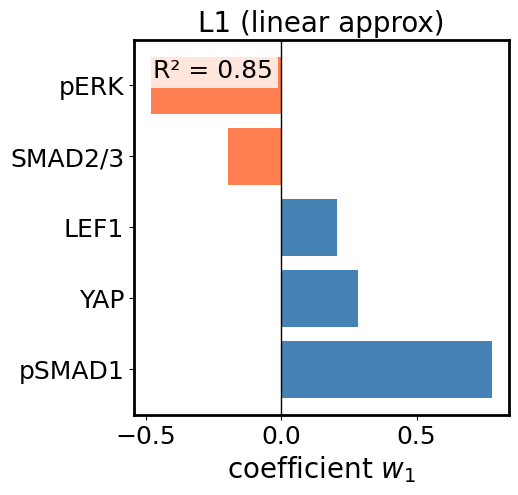

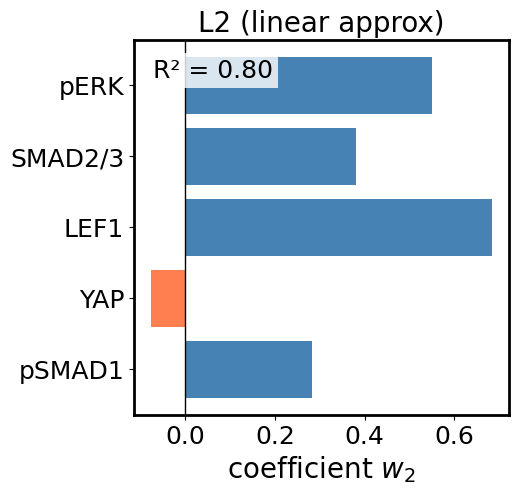

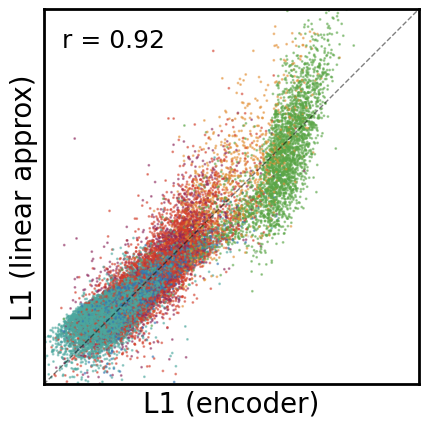

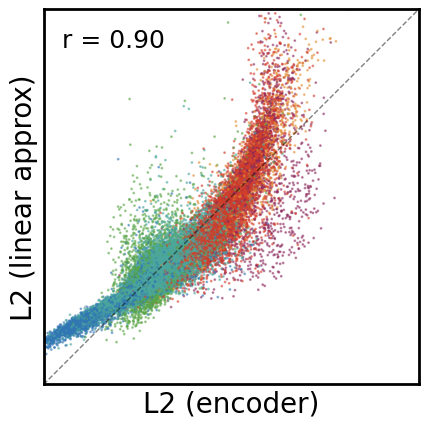

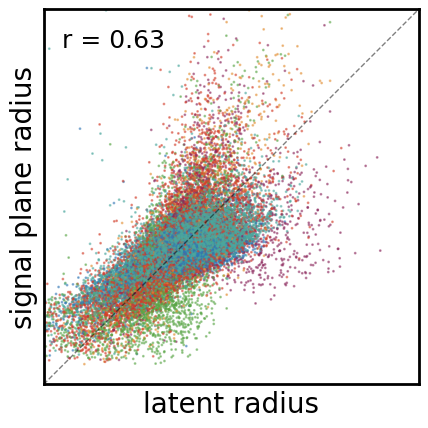

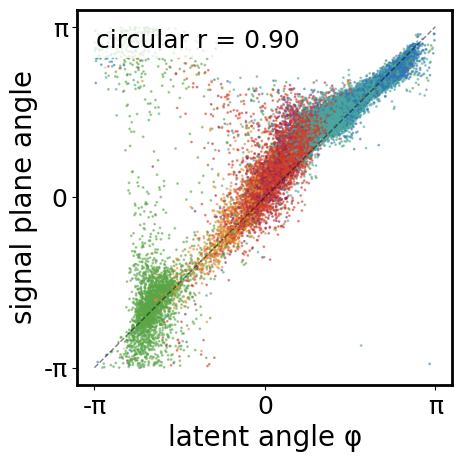

In [474]:
def circular_difference(a, b):
    """Elementwise difference wrapped to [-pi, pi]."""
    diff = a - b
    return np.arctan2(np.sin(diff), np.cos(diff))
    
# ============================================================
# PLOTS
# ============================================================

fates_data, _ = IIF.return_fates(data[mask], thresh=thresh)
colors = [IIF.colmap_fates[f] for f in fates_data]

tol = (0.1, 99.9)
box_size = 0.75
fs = 20

ylabels = [clean_signal_names[s] for s in signals]

# ---- coefficient plots ----
for name, coef, r2, wlabel in [('L1 (linear approx)', w1_norm, r2_L1, r'$w_1$'),
                                ('L2 (linear approx)', w2_norm, r2_L2, r'$w_2$')]:

    fig, ax = plt.subplots(figsize=(5, 5))
    colors_bar = ['steelblue' if c >= 0 else 'coral' for c in coef]
    ax.barh(range(len(signals)), coef, color=colors_bar)
    ax.axvline(x=0, color='k', linewidth=1)
    ax.set_yticks(range(len(signals)))
    ax.set_yticklabels(ylabels, fontsize=fs)
    ax.set_xlabel(f'coefficient {wlabel}', fontsize=fs)
    ax.set_title(f'{name}', fontsize=fs)
    ax.text(0.05, 0.95, f'R² = {r2:.2f}',
            transform=ax.transAxes, fontsize=fs - 2,
            va='top', ha='left',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
    ax.tick_params(labelsize=fs - 2)
    ax.set_box_aspect(1)
    ax.set_position([0.3, 0.15, box_size, box_size])
    for spine in ax.spines.values():
        spine.set_linewidth(sw)
    if save:
        plt.savefig(dataDir+f'/FigS7/orthogonal_optimized_coef_{name}_' + str(len(signals)) + 'D_run' + str(run) + '.png', dpi=150, bbox_inches='tight')
    plt.show()


# ---- L1/L2 scatter plots ----
for orig, pred, name in [(L1, L1_pred, 'L1'), (L2, L2_pred, 'L2')]:

    fig, ax = plt.subplots(figsize=(5, 5))

    orig_s = (orig - orig.mean()) / orig.std()
    pred_s = (pred - pred.mean()) / pred.std()
    r_val, _ = sp.stats.pearsonr(orig_s, pred_s)

    ax.scatter(orig_s, pred_s, c=colors, s=1, alpha=0.5)

    xmin, xmax = np.percentile(orig_s, tol)
    ymin, ymax = np.percentile(pred_s, tol)
    lim_min = min(xmin, ymin)
    lim_max = max(xmax, ymax)

    ax.plot([lim_min, lim_max], [lim_min, lim_max], 'k--', linewidth=1, alpha=0.5)
    ax.set_xlim(lim_min, lim_max)
    ax.set_ylim(lim_min, lim_max)
    ax.set_xlabel(f'{name} (encoder)', fontsize=fs)
    ax.set_ylabel(f'{name} (linear approx)', fontsize=fs)
    #ax.set_title(f'{name}', fontsize=fs)
    ax.text(0.05, 0.95, f'r = {r_val:.2f}',
            transform=ax.transAxes, fontsize=fs - 2,
            va='top', ha='left',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_box_aspect(1)
    ax.set_position([0.15, 0.15, box_size, box_size])
    for spine in ax.spines.values():
        spine.set_linewidth(sw)

    if save:
        plt.savefig(dataDir+f'/FigS7/orthogonal_optimized_scatter_{name}_' + str(len(signals)) + 'D_run' + str(run) + '.png', dpi=150, bbox_inches='tight')
    plt.show()

# ---- radius plot ----

r_polar = np.sqrt(x_centered**2 + y_centered**2)

r_signal = np.sqrt((p_scaled[:, 0] - center_x)**2 + (p_scaled[:, 1] - center_y)**2)

r_latent_s = (r_polar - r_polar.mean()) / r_polar.std()
r_signal_s = (r_signal - r_signal.mean()) / r_signal.std()

r_corr, _ = sp.stats.pearsonr(r_latent_s, r_signal_s)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(r_latent_s, r_signal_s, c=colors, s=1, alpha=0.5)

xmin, xmax = np.percentile(r_latent_s, tol)
ymin, ymax = np.percentile(r_signal_s, tol)
lim_min = min(xmin, ymin)
lim_max = max(xmax, ymax)

ax.plot([lim_min, lim_max], [lim_min, lim_max], 'k--', linewidth=1, alpha=0.5)
ax.set_xlim(lim_min, lim_max)
ax.set_ylim(lim_min, lim_max)
ax.set_xlabel('latent radius', fontsize=fs)
ax.set_ylabel('signal plane radius', fontsize=fs)
ax.text(0.05, 0.95, f'r = {r_corr:.2f}',
        transform=ax.transAxes, fontsize=fs - 2,
        va='top', ha='left',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.set_xticks([])
ax.set_yticks([])
ax.set_box_aspect(1)
ax.set_position([0.15, 0.15, box_size, box_size])
for spine in ax.spines.values():
    spine.set_linewidth(sw)

if save:
    plt.savefig(dataDir+'/FigS7/orthogonal_optimized_radius_' + str(len(signals)) + 'D_run' + str(run) + '.png', dpi=150, bbox_inches='tight')
plt.show()

# ---- angle plot ----
p_raw = np.column_stack([p1, p2])
p_scaled = p_raw @ M + b
phi_signal = np.arctan2(p_scaled[:, 1] - center_y, p_scaled[:, 0] - center_x)
r_circ = circ_corr(theta_corrected, phi_signal)
if r_circ < 0:
    phi_signal = -phi_signal

angles_to_test = np.linspace(-np.pi, np.pi, 360)
mean_abs_diff = []
for shift in angles_to_test:
    diff = circular_difference(theta_corrected, phi_signal + shift)
    mean_abs_diff.append(np.mean(np.abs(diff)))
#best_shift = angles_to_test[np.argmin(mean_abs_diff)]

best_shift = 1.3

phi_signal_shifted = np.arctan2(np.sin(phi_signal + best_shift),
                                np.cos(phi_signal + best_shift))

r_circ = circ_corr(theta_corrected, phi_signal_shifted)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([-np.pi, np.pi], [-np.pi, np.pi], 'k--', linewidth=1, alpha=0.5)
ax.scatter(theta_corrected, phi_signal_shifted, c=colors, s=1, alpha=0.5)
ax.set_xlabel('latent angle φ', fontsize=fs)
ax.set_ylabel('signal plane angle', fontsize=fs)
ax.text(0.05, 0.95, f'circular r = {r_circ:.2f}',
        transform=ax.transAxes, fontsize=fs - 2,
        va='top', ha='left',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.set_xticks([-np.pi, 0, np.pi])
ax.set_xticklabels(['-π', '0', 'π'], fontsize=fs - 2)
ax.set_yticks([-np.pi, 0, np.pi])
ax.set_yticklabels(['-π', '0', 'π'], fontsize=fs - 2)
ax.set_box_aspect(1)
ax.set_position([0.15, 0.15, box_size, box_size])
for spine in ax.spines.values():
    spine.set_linewidth(sw)

if save:
    plt.savefig(dataDir+'/FigS7/orthogonal_optimized_angle_' + str(len(signals)) + 'D_run' + str(run) + '.png', dpi=150, bbox_inches='tight')
plt.show()

In [463]:
# ============================================================
# LEAVE-ONE-COLONY-OUT VALIDATION OF THE SIGNAL-SPACE ANGLE FIT
# Model stays fixed (vib[run]'s already-trained encoder); only the w1/w2 projection is
# cross-validated. Self-contained: recomputes mask/mu/phi_latent locally rather than
# trusting the ambient theta_corrected/r/mask/fates globals, which get reused with
# different shapes elsewhere in this notebook.
# ============================================================
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression

run = 3
n_signals = len(signals)

mask_B50 = data['condition'] == 'B50'
data_B50 = data.loc[mask_B50]
colonies = data_B50['Colony'].values
colony_ids = np.unique(colonies)

model = vib[run].model
model.eval()

X_all_np = vib[run].scaler_X_run.transform(data_B50[signals])
X_all_t = torch.FloatTensor(X_all_np).to(device)
with torch.no_grad():
    mu_all, _ = model.encode(X_all_t)
L1_all = mu_all[:, 0].cpu().numpy()
L2_all = mu_all[:, 1].cpu().numpy()

# phi_latent/r_latent for all B50 cells: raw mu -> aligned frame (M, b) -> polar,
# same convention as theta_corrected/r elsewhere, computed fresh here
L_scaled_all = np.column_stack([L1_all, L2_all]) @ M + b
xc_latent = L_scaled_all[:, 0] - center_x
yc_latent = L_scaled_all[:, 1] - center_y
r_latent = np.sqrt(xc_latent**2 + yc_latent**2)
theta_raw_latent = np.arctan2(yc_latent, xc_latent)
phi_latent = -(theta_raw_latent - gap_angle + np.pi)
phi_latent = np.arctan2(np.sin(phi_latent), np.cos(phi_latent))

def fit_orthogonal_projection(X_c, L1_c, L2_c, n_restarts=20, seed=0):
    """Fit two orthogonal signal-space directions w1, w2 predicting mean-centered L1, L2
    (constrained SLSQP, orthogonality constraint, n_restarts random restarts to avoid
    local minima) -- same procedure as the in-sample fit, factored out for reuse across
    LOOCV folds and conditions. Restarts are seeded (unlike the original single-fit
    version) for reproducibility. Returns (w1_opt, w2_opt)."""
    n_sig = X_c.shape[1]

    def pack(v1, v2):
        return np.concatenate([v1, v2])

    def unpack(params):
        return params[:n_sig], params[n_sig:]

    def orthogonality_constraint(params):
        v1, v2 = unpack(params)
        return np.dot(v1, v2)

    def loss_direct(params):
        w1, w2 = unpack(params)
        res1 = L1_c - X_c @ w1
        res2 = L2_c - X_c @ w2
        return np.mean(res1 ** 2) + np.mean(res2 ** 2)

    w1_init = LinearRegression().fit(X_c, L1_c).coef_
    w2_init = LinearRegression().fit(X_c, L2_c).coef_
    w2_init = w2_init - np.dot(w2_init, w1_init) / np.dot(w1_init, w1_init) * w1_init

    constraints = [{'type': 'eq', 'fun': orthogonality_constraint}]
    rng = np.random.default_rng(seed)
    best_result, best_loss = None, np.inf

    for i in range(n_restarts):
        if i == 0:
            v0 = pack(w1_init, w2_init)
        else:
            A = rng.standard_normal((n_sig, 2)) * np.std(w1_init)
            Q, _ = np.linalg.qr(A)
            Q[:, 0] *= np.linalg.norm(w1_init)
            Q[:, 1] *= np.linalg.norm(w2_init)
            v0 = pack(Q[:, 0], Q[:, 1])
        res = minimize(loss_direct, v0, constraints=constraints, method='SLSQP',
                        options={'ftol': 1e-12, 'maxiter': 10000})
        if res.fun < best_loss:
            best_loss = res.fun
            best_result = res

    return unpack(best_result.x)

def project_and_polarize(w1, w2, X_c, L1_mean, L2_mean):
    """Project mean-centered signal data X_c through fitted w1, w2 to get p1, p2
    (approximating this model's native L1, L2), transform into the aligned/latent frame
    via the model's (M, b) affine map, and convert to polar (phi_signal, r_signal) using
    the same center_x/center_y/gap_angle convention as phi_latent -- so phi_signal is
    directly, meaningfully comparable to phi_latent. L1_mean/L2_mean should be the
    TRAINING fold's L1/L2 means (not the evaluation data's own), matching X_c's own
    training-fold centering, to avoid leaking held-out statistics."""
    p1 = X_c @ w1 + L1_mean
    p2 = X_c @ w2 + L2_mean
    p_scaled = np.column_stack([p1, p2]) @ M + b
    xc = p_scaled[:, 0] - center_x
    yc = p_scaled[:, 1] - center_y
    r_signal = np.sqrt(xc ** 2 + yc ** 2)
    theta_raw = np.arctan2(yc, xc)
    phi_signal = -(theta_raw - gap_angle + np.pi)
    phi_signal = np.arctan2(np.sin(phi_signal), np.cos(phi_signal))
    return phi_signal, r_signal

In [464]:
# --- in-sample (fit on all B50 colonies, evaluate on the same data) ---
X_all_mean = X_all_np.mean(axis=0)
X_all_c = X_all_np - X_all_mean
L1_all_mean, L2_all_mean = L1_all.mean(), L2_all.mean()
L1_all_c, L2_all_c = L1_all - L1_all_mean, L2_all - L2_all_mean

w1_full, w2_full = fit_orthogonal_projection(X_all_c, L1_all_c, L2_all_c, seed=0)
phi_signal_full, r_signal_full = project_and_polarize(w1_full, w2_full, X_all_c, L1_all_mean, L2_all_mean)

insample_circ_corr = circ_corr(phi_signal_full, phi_latent)
insample_r_corr, _ = sp.stats.pearsonr(r_signal_full, r_latent)
print(f'in-sample circular corr: {insample_circ_corr:.4f}')
print(f'in-sample radius Pearson r: {insample_r_corr:.4f}\n')

# --- leave-one-colony-out ---
loocv_records = []

for held_out in colony_ids:
    train_mask = colonies != held_out
    test_mask = colonies == held_out

    X_train, X_test = X_all_np[train_mask], X_all_np[test_mask]
    L1_train, L2_train = L1_all[train_mask], L2_all[train_mask]

    X_train_mean = X_train.mean(axis=0)
    X_train_c = X_train - X_train_mean
    X_test_c = X_test - X_train_mean  # held-out data centered with TRAIN's mean, no leakage

    L1_train_mean, L2_train_mean = L1_train.mean(), L2_train.mean()
    L1_train_c, L2_train_c = L1_train - L1_train_mean, L2_train - L2_train_mean

    w1_fold, w2_fold = fit_orthogonal_projection(X_train_c, L1_train_c, L2_train_c, seed=int(held_out))

    phi_signal_test, r_signal_test = project_and_polarize(w1_fold, w2_fold, X_test_c, L1_train_mean, L2_train_mean)
    phi_latent_test, r_latent_test = phi_latent[test_mask], r_latent[test_mask]

    fold_circ_corr = circ_corr(phi_signal_test, phi_latent_test)
    fold_r_corr, _ = sp.stats.pearsonr(r_signal_test, r_latent_test)

    loocv_records.append({'held_out_colony': held_out, 'circular_corr': fold_circ_corr,
                           'radius_pearson_r': fold_r_corr, 'w1': w1_fold, 'w2': w2_fold})

loocv_df = pd.DataFrame(loocv_records).set_index('held_out_colony')
print(loocv_df[['circular_corr', 'radius_pearson_r']])
print(f"\nLOOCV mean circular corr: {loocv_df['circular_corr'].mean():.4f} +/- {loocv_df['circular_corr'].std():.4f}")
print(f"LOOCV mean radius Pearson r: {loocv_df['radius_pearson_r'].mean():.4f} +/- {loocv_df['radius_pearson_r'].std():.4f}")


in-sample circular corr: 0.9046
in-sample radius Pearson r: 0.6326

                 circular_corr  radius_pearson_r
held_out_colony                                 
1                     0.895887          0.629524
2                     0.921296          0.543499
3                     0.900962          0.619453
4                     0.914879          0.624632
5                     0.896851          0.632568
6                     0.896648          0.680078

LOOCV mean circular corr: 0.9044 +/- 0.0109
LOOCV mean radius Pearson r: 0.6216 +/- 0.0441


              mean       std
signal                      
pSMAD1    0.604606  0.007272
ncYAP     0.216785  0.003853
LEF1      0.469550  0.008315
ncSMAD23  0.286032  0.003791
cytopERK  0.504724  0.007020


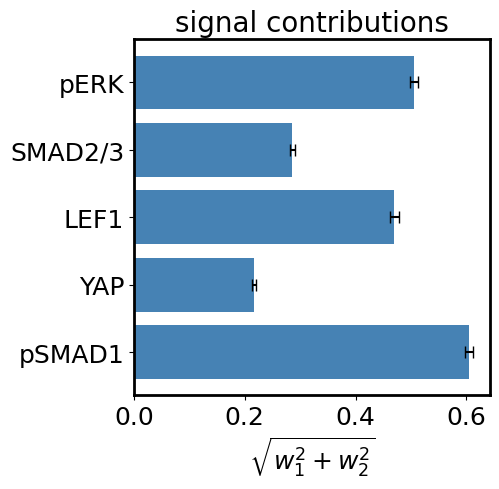

                     metric    value
    in-sample circular corr 0.904631
 in-sample radius Pearson r 0.632629
   LOOCV mean circular corr 0.904421
     LOOCV sd circular corr 0.010924
LOOCV mean radius Pearson r 0.621626
  LOOCV sd radius Pearson r 0.044082


In [473]:
contribution_records = []
for held_out, row in loocv_df.iterrows():
    contribution = np.sqrt(row['w1'] ** 2 + row['w2'] ** 2)
    for i, sig in enumerate(signals):
        contribution_records.append({'held_out_colony': held_out, 'signal': sig,
                                      'contribution': contribution[i],
                                      'w1': row['w1'][i], 'w2': row['w2'][i]})

contribution_df = pd.DataFrame(contribution_records)
contribution_summary = contribution_df.groupby('signal')['contribution'].agg(['mean', 'std']).reindex(signals)
print(contribution_summary)

contribution_df.to_csv(dataDir+'/FigS7/loocv_signal_contributions_raw.csv', index=False)
contribution_summary.to_csv(dataDir+'/FigS7/loocv_signal_contributions_summary.csv')

# --- panel for S7 ---
fs = 20
sw = 2
fig, ax = plt.subplots(figsize=(7, 5))
ylabels = [clean_signal_names[s] for s in signals]
ax.barh(range(len(signals)), contribution_summary['mean'].values,
        xerr=contribution_summary['std'].values, color='steelblue', capsize=4)
ax.set_yticks(range(len(signals)))
ax.set_yticklabels(ylabels, fontsize=fs)
ax.set_xlabel(r'$\sqrt{w_1^2+w_2^2}$', fontsize=fs-2)
ax.tick_params(labelsize=fs - 2)
ax.set_box_aspect(1)
ax.set_title('signal contributions',fontsize=fs)
for spine in ax.spines.values():
    spine.set_linewidth(sw)
plt.tight_layout()
plt.savefig(dataDir+'/FigS7/loocv_signal_contributions_' + str(len(signals)) + 'D_run' + str(run) + '.png',
            dpi=150, bbox_inches='tight')
plt.show()

# --- final summary table ---
summary_records = [
    {'metric': 'in-sample circular corr', 'value': insample_circ_corr},
    {'metric': 'in-sample radius Pearson r', 'value': insample_r_corr},
    {'metric': 'LOOCV mean circular corr', 'value': loocv_df['circular_corr'].mean()},
    {'metric': 'LOOCV sd circular corr', 'value': loocv_df['circular_corr'].std()},
    {'metric': 'LOOCV mean radius Pearson r', 'value': loocv_df['radius_pearson_r'].mean()},
    {'metric': 'LOOCV sd radius Pearson r', 'value': loocv_df['radius_pearson_r'].std()},
]

summary_df_final = pd.DataFrame(summary_records)
print(summary_df_final.to_string(index=False))
summary_df_final.to_csv(dataDir+'/FigS7/loocv_projection_summary_table.csv', index=False)



### More latent space visualization

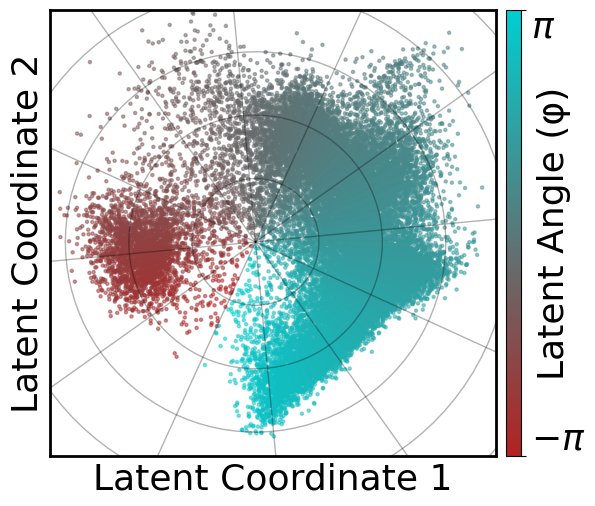

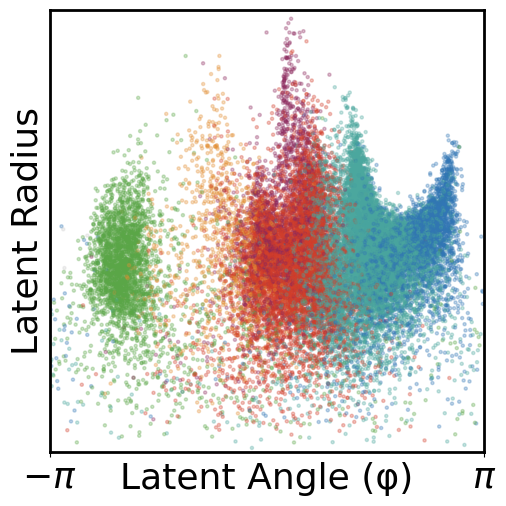

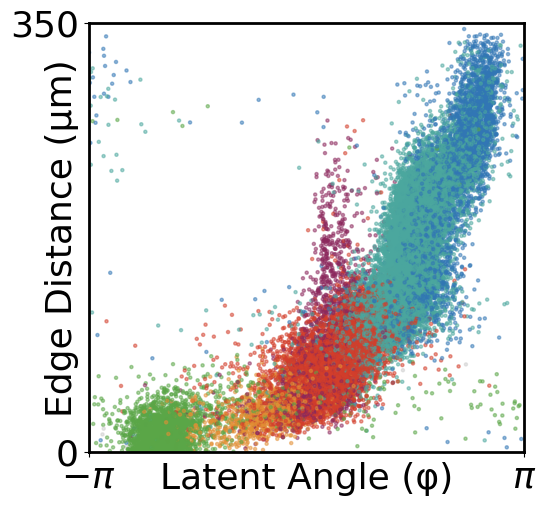

In [398]:
#=============VISUALIZATION=================
save = True

# Set consistent figure parameters
figsize = (5, 5)
fs = 26
sw = 2
s =5

fates_data, _ = IIF.return_fates(data[mask], thresh=thresh)
colors = [IIF.colmap_fates[f] for f in fates_data]
cmap = mcolors.LinearSegmentedColormap.from_list('cyan_red', ['firebrick', 'darkturquoise'], N=100)


#============= (polar overlay with colorbar)=================
fig, ax = plt.subplots(1, 1, figsize=figsize)

xlim_orig = (L1smin, L1smax) 
ylim_orig = (L2smin, L2smax) 
#xlim_orig = (L1_scaled.min(), L1_scaled.max())
#ylim_orig = (L2_scaled.min(), L2_scaled.max())

scatter = ax.scatter(L1_scaled, L2_scaled, c=theta_corrected, s=s, alpha=0.5, 
                     cmap=cmap, vmin=-np.pi, vmax=np.pi)

# Add polar grid lines
lw = 1
r_grid_values = np.linspace(0, r.max(), 6)
for r_val in r_grid_values[1:]:
    theta_circle = np.linspace(-np.pi, np.pi, 100)
    x_circle = center_x + r_val * np.cos(theta_circle)
    y_circle = center_y + r_val * np.sin(theta_circle)
    ax.plot(x_circle, y_circle, 'k-', linewidth=lw, alpha=0.3)

theta_grid_values = np.linspace(-np.pi, np.pi, 13)[:-1]
r_max = r.max() * 1.1
for theta_corrected_val in theta_grid_values:
    theta_raw_val = -(theta_corrected_val) + gap_angle + np.pi
    x_ray = [center_x, center_x + r_max * np.cos(theta_raw_val)]
    y_ray = [center_y, center_y + r_max * np.sin(theta_raw_val)]
    ax.plot(x_ray, y_ray, 'k-', linewidth=lw, alpha=0.3)

ax.set_xlim(xlim_orig)
ax.set_ylim(ylim_orig)
ax.set_xlabel('Latent Coordinate 1', fontsize=fs)
ax.set_ylabel('Latent Coordinate 2', fontsize=fs)
#ax.set_aspect('equal', adjustable='box')
ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_linewidth(sw)

# Apply tight_layout first to set axis positions
plt.tight_layout(pad=0.5)

# Get the axis position after tight_layout
pos = ax.get_position()

# Create a ScalarMappable for the colorbar with full opacity
import matplotlib.cm as cm
norm = mcolors.Normalize(vmin=-np.pi, vmax=np.pi)
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Create colorbar from the ScalarMappable instead of the scatter
cbar_ax = fig.add_axes([pos.x1 + 0.02, pos.y0, 0.03, pos.height])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_ticks([-np.pi, np.pi])
cbar.set_ticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs)
cbar.set_label('Latent Angle (φ)', fontsize=fs, rotation=90, labelpad=-35)

tick_labels = cbar.ax.get_yticklabels()
tick_labels[0].set_verticalalignment('bottom')
tick_labels[1].set_verticalalignment('top')

if save:
    plt.savefig(dataDir+'/Fig3/LS_polaroverlay_'  + str(len(signals))+ '_run' + str(run)   + 'D' + '.png', dpi=150, bbox_inches='tight', pad_inches=0.1)
plt.show()
plt.close()

#============= (polar space)=================
fig, ax = plt.subplots(1, 1, figsize=figsize)

r_max = np.percentile(r, 99.99)*1.1

ax.scatter(theta_corrected, r, c=colors, s=s, alpha=0.3)
ax.set_xlabel('Latent Angle (φ)', fontsize=fs, labelpad=-23)
ax.set_ylabel('Latent Radius', fontsize=fs)
ax.set_xlim(-np.pi, np.pi)
ax.set_ylim([0,r_max/1.1])
ax.set_xticks([-np.pi, np.pi])
ax.set_xticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs)
ax.set_yticks([])
ax.tick_params(axis='x', which='major', pad=2)

for spine in ax.spines.values():
    spine.set_linewidth(sw)

#ax.set_aspect('equal', adjustable='box')
plt.tight_layout(pad=0.5)
if save:
    plt.savefig(dataDir+'/Fig3/LS_polar_'  + str(len(signals)) + 'D' + '_run' + str(run)   + '.png', dpi=150, bbox_inches='tight', pad_inches=0.1)
plt.show()
plt.close()

#============= (angle vs radius)=================
fig, ax = plt.subplots(1, 1, figsize=(5.4,5))

ax.scatter(theta_corrected, data.loc[mask, 'CircleEdgeDist'], c=colors, s=s, alpha=0.5)
ax.set_xlabel('Latent Angle (φ)', fontsize=fs, labelpad=-23)
ax.set_ylabel('Edge Distance (μm)', fontsize=fs, labelpad=-50)
ax.set_xlim(-np.pi, np.pi)
ax.set_ylim(0, 350)
ax.set_xticks([-np.pi, np.pi])
ax.set_xticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs)
ax.set_yticks([0, 350])
ax.set_yticklabels([0, 350], fontsize=fs)
ax.tick_params(axis='x', which='major', pad=2)

for spine in ax.spines.values():
    spine.set_linewidth(sw)

plt.tight_layout(pad=0.5)
if save:
    plt.savefig(dataDir+'/Fig3/LS_angle_v_radius_'  + str(len(signals)) + 'D' + '_run' + str(run)  + '.png', dpi=150, bbox_inches='tight', pad_inches=0.1)
plt.show()
plt.close()

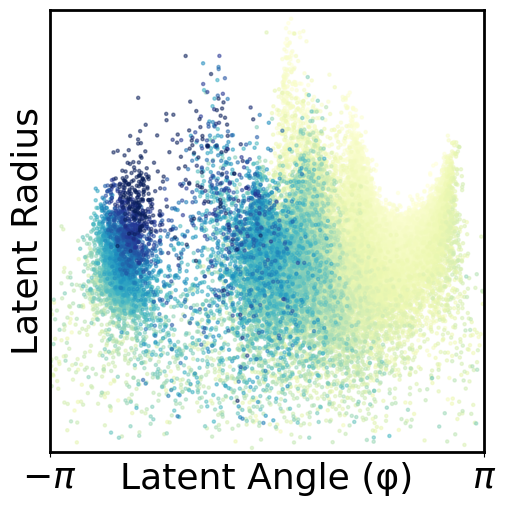

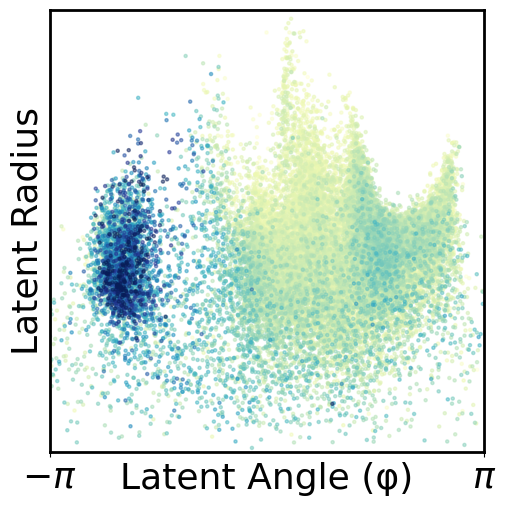

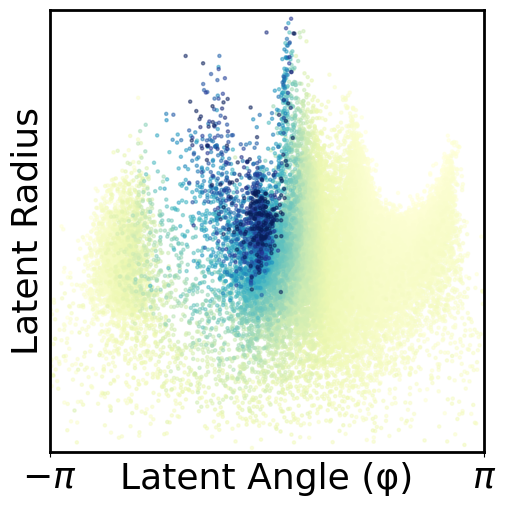

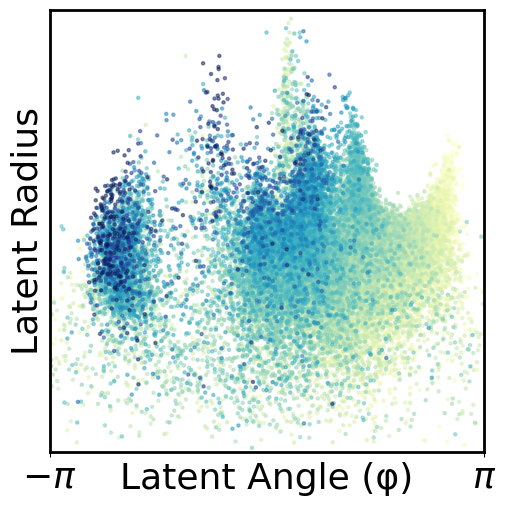

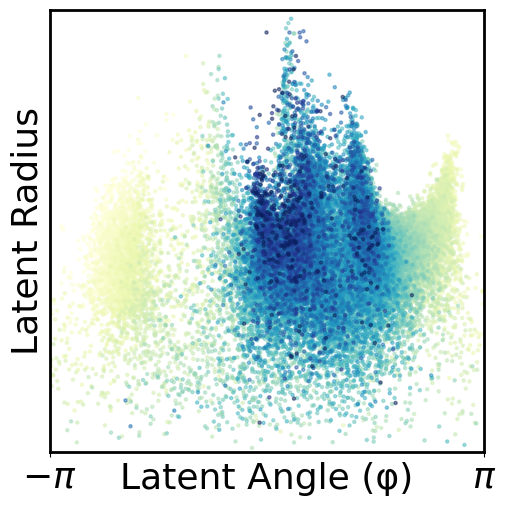

In [399]:
#=============VISUALIZATION=================

# Set consistent figure parameters
figsize = (5, 5)
fs = 26
sw = 2
s = 5

r_max = np.percentile(r, 99.99)*1.1

#============= (polar space)=================

for sig in signals:
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    
    colors = data.loc[mask, sig]
    order = colors.sort_values().index
    tol=(0.5,99.5)
    vmin = np.percentile(colors, tol[0])
    vmax = np.percentile(colors, tol[1])
    ax.scatter(theta_corrected[order], r[order],c=colors[order], s=s, cmap='YlGnBu',vmin=vmin,vmax=vmax, alpha=0.5)
    
    ax.set_xlabel('Latent Angle (φ)', fontsize=fs, labelpad=-23)
    ax.set_ylabel('Latent Radius', fontsize=fs)
    ax.set_xlim(-np.pi, np.pi)
    ax.set_ylim([0,r_max/1.1])
    ax.set_xticks([-np.pi, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs)
    ax.set_yticks([])
    ax.tick_params(axis='x', which='major', pad=2)
    
    for spine in ax.spines.values():
        spine.set_linewidth(sw)
    
    #ax.set_aspect('equal', adjustable='box')
    plt.tight_layout(pad=0.5)
    if save:
        plt.savefig(dataDir+'/FigS7/LS_polar_'+sig+ str(len(signals)) + 'D' + '_run' + str(run)  + '.png', dpi=150, bbox_inches='tight', pad_inches=0.1)
    plt.show()
    plt.close()

99.0% of data points are inside the contours


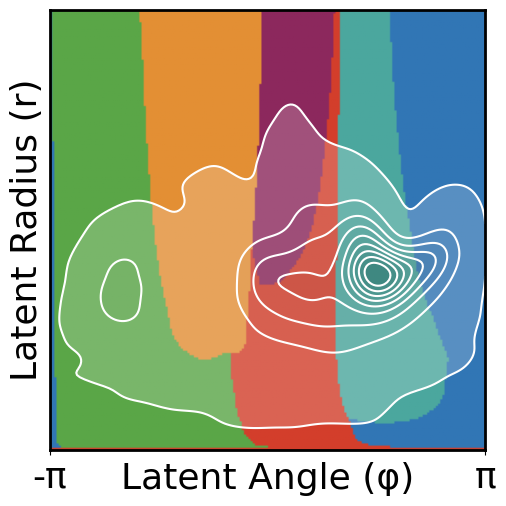

In [401]:
# EXTRAPOLATE FATE MAP IN POLAR COORDINATES
n_theta = 200
n_r = 200

theta_grid = np.linspace(-np.pi, np.pi, n_theta)
r_grid = np.linspace(0, r.max(), n_r)

THETA_GRID, R_GRID = np.meshgrid(theta_grid, r_grid)

THETA_RAW = -(THETA_GRID) - np.pi + gap_angle

L1_from_polar = center_x + R_GRID * np.cos(THETA_RAW)
L2_from_polar = center_y + R_GRID * np.sin(THETA_RAW)

# L1_from_polar/L2_from_polar are in the aligned/rescaled frame -- invert the same
# affine map used in EXTRAPOLATE FATE MAP (M, b, fit for this run) to get back to this
# model's native mu space before decoding
grid_scaled_polar = np.column_stack([L1_from_polar.ravel(), L2_from_polar.ravel()])
mugrid_polar = (grid_scaled_polar - b) @ M_inv
mugrid_polar = torch.FloatTensor(mugrid_polar).to(device)

model = vib[run].model
model.eval()
with torch.no_grad():
    Y_polar = model.decode(mugrid_polar).cpu().numpy()
    Y_polar = vib[run].scaler_Y_run.inverse_transform(Y_polar)
    Y_polar = pd.DataFrame(Y_polar, columns=gene_names)

fates_polar, _ = IIF.return_fates(Y_polar, thresh=thresh)

# Create RGB image for polar fate map
rgb_image_polar = np.zeros((n_r, n_theta, 3))

for i, fate in enumerate(fates_polar):
    color = IIF.colmap_fates[fate]
    rgb = mcolors.to_rgb(color)
    rgb_image_polar[i // n_theta, i % n_theta] = rgb

#--------COMPUTE KDE IN CORRECTED POLAR SPACE--------------

# Compute KDE for the scatter points in polar coordinates
if len(theta_corrected) > 1:
    # Create KDE in corrected polar space
    values_polar = np.vstack([theta_corrected, r])
    kernel_polar = sp.stats.gaussian_kde(values_polar, bw_method=0.2)
    
    # Evaluate KDE at the actual data points
    kde_at_data = kernel_polar(values_polar)
    
    # Set vmin so that X% of data points are outside the contours
    data_percentile = 1  # Change this: 10 means 10% of data outside, 90% inside
    vmin = np.percentile(kde_at_data, data_percentile)
    
    # Evaluate KDE on the polar grid
    kde_grid_polar = kernel_polar(np.vstack([THETA_GRID.ravel(), R_GRID.ravel()]))
    kde_grid_polar = kde_grid_polar.reshape(THETA_GRID.shape)
    
    # Define contour levels from vmin to max
    vmax = kde_grid_polar.max()
    levels = np.linspace(vmin, vmax, 10)
    
    # Verify
    fraction_inside = np.sum(kde_at_data >= vmin) / len(theta_corrected)
    print(f"{fraction_inside*100:.1f}% of data points are inside the contours")

#--------RECTANGULAR PLOT WITH POLAR COORDINATES (SQUARE)--------------

fs = 26
sw = 2
s = 5

fig, ax = plt.subplots(1, 1, figsize=(5, 5))

# Display fate map with theta on x-axis and r on y-axis
ax.imshow(rgb_image_polar, origin='lower', aspect='auto',
          extent=[theta_grid.min(), theta_grid.max(), r_grid.min(), r_grid.max()])

# Add KDE contours
if len(theta_corrected) > 1:
    ax.contourf(THETA_GRID, R_GRID, kde_grid_polar, 
                levels=levels, cmap='Greys', alpha=0.2)
    ax.contour(THETA_GRID, R_GRID, kde_grid_polar, 
               levels=levels, colors='white', linewidths=1.5)

# Formatting
ax.set_xlabel('Latent Angle (φ)', fontsize=fs, labelpad=-23)
ax.set_ylabel('Latent Radius (r)', fontsize=fs)
ax.set_xlim(theta_grid.min(), theta_grid.max())
ax.set_ylim(0, r_grid.max())

# Optional: Add custom tick labels
theta_labels = ['-π', 'π']
ax.set_xticks([-np.pi, np.pi])
ax.set_xticklabels(theta_labels, fontsize=fs)
ax.tick_params(axis='y', labelsize=fs)
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_linewidth(sw)

# Force square aspect ratio
#ax.set_aspect('equal', adjustable='box')

plt.tight_layout(pad=0.5)
if save:
    plt.savefig(dataDir+'/Fig3/LS_fate_polar_rectangular' + str(len(signals)) + 'D' + '_run' + str(run)  + '.png', dpi=150, bbox_inches='tight', pad_inches=0.1)
plt.show()




Inner: 1806 cells


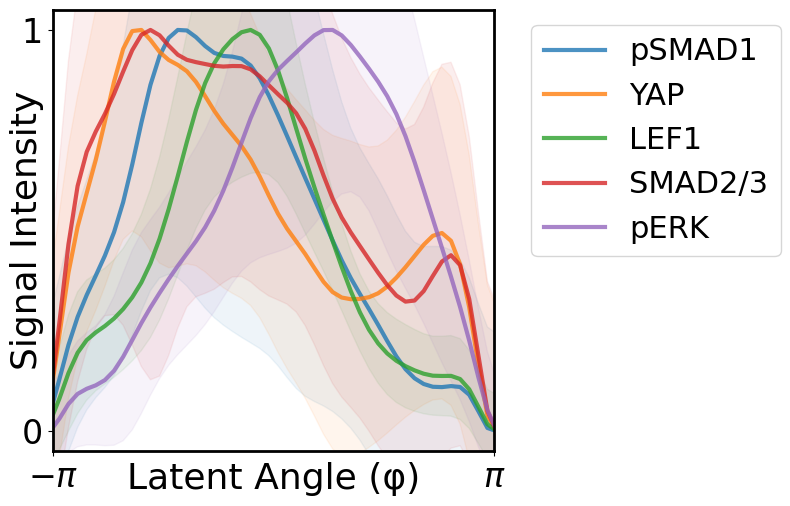


Outer: 28621 cells


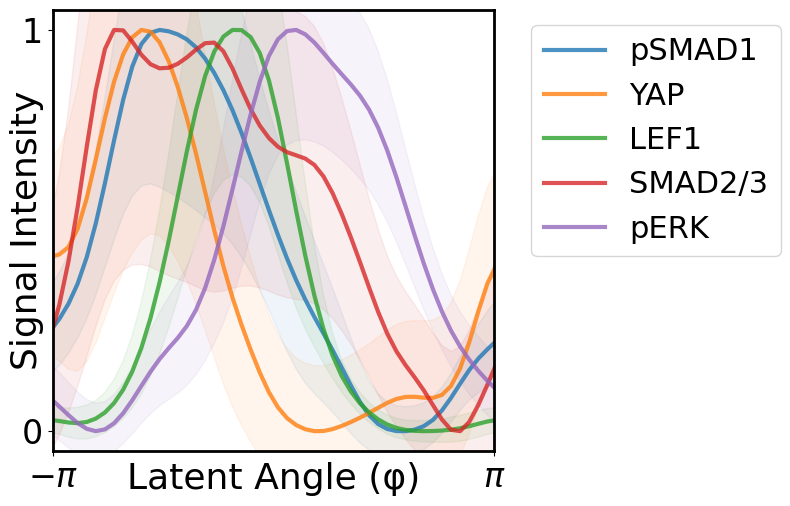


All: 30427 cells


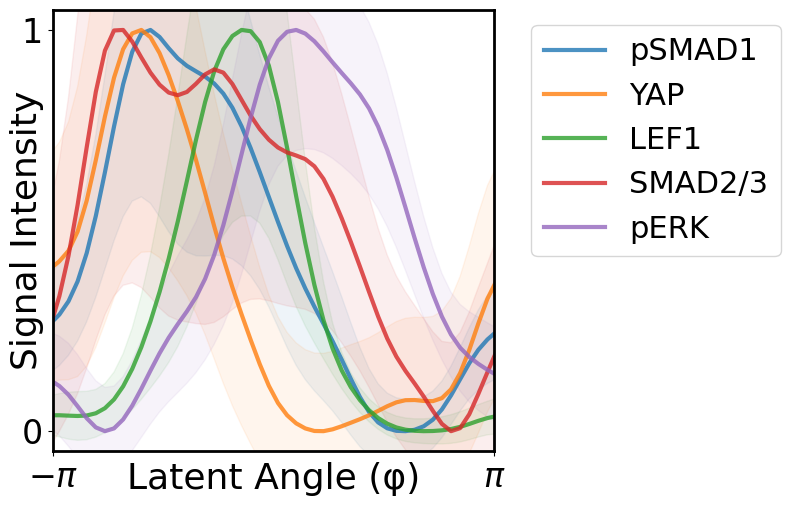

In [403]:
#=============PLOT SIGNAL MEANS VS POLAR ANGLE (NORMALIZED 0-1, SMOOTHED WITH PERIODIC BC)=================

save = True

import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# Number of angular bins
n_bins = 50

# Create bins for theta
theta_bins = np.linspace(-np.pi-0.1, np.pi+0.1, n_bins + 1)
theta_centers = (theta_bins[:-1] + theta_bins[1:]) / 2

# Initialize storage for mean signals
signal_means = {signal: np.zeros(n_bins) for signal in signals}
signal_stds = {signal: np.zeros(n_bins) for signal in signals}
bin_counts = np.zeros(n_bins)

# Compute means and stds for each bin
for i in range(n_bins):
    mask_bin = (theta_corrected >= theta_bins[i]) & (theta_corrected < theta_bins[i+1])
    bin_counts[i] = mask_bin.sum()
    
    if mask_bin.sum() > 0:
        for signal in signals:
            signal_values = data.loc[mask, signal].values[mask_bin]
            signal_means[signal][i] = signal_values.mean()
            signal_stds[signal][i] = signal_values.std()

# Normalize each signal to 0-1 range
signal_means_norm = {}
signal_stds_norm = {}
signal_means_smooth = {}

for signal in signals:
    min_val = signal_means[signal].min()
    max_val = signal_means[signal].max()
    range_val = max_val - min_val
    
    if range_val > 0:
        signal_means_norm[signal] = (signal_means[signal] - min_val) / range_val
        signal_stds_norm[signal] = signal_stds[signal] / range_val
    else:
        signal_means_norm[signal] = signal_means[signal]
        signal_stds_norm[signal] = signal_stds[signal]
    
    # Apply smoothing with periodic boundary conditions
    # Extend the array by wrapping values at both ends
    extended = np.concatenate([
        signal_means_norm[signal][-5:],  # Last 5 points
        signal_means_norm[signal],
        signal_means_norm[signal][:5]    # First 5 points
    ])
    smoothed_extended = gaussian_filter1d(extended, sigma=2)
    signal_means_smooth[signal] = smoothed_extended[5:-5]  # Extract middle portion


#=============STRATIFIED OVERLAY BY RADIAL POSITION (MEAN, NORMALIZE AFTER SMOOTHING)============


# Define three radial bands based on std around mean
r_mean = np.mean(r)
r_std = np.std(r)

r1 = 1
r2 = 5
radial_conditions = [
    (r <  r1, f'Inner'),
#    ((r >= r1) & (r <= r2), f'Middle (mean ± σ)'),
    (r > r1, f'Outer'),
    (r>0, 'All')
]

for (r_condition, r_label) in radial_conditions:

    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    
    print(f"\n{r_label}: {r_condition.sum()} cells")
    
    if r_condition.sum() == 0:
        ax.text(0.5, 0.5, 'No cells', ha='center', va='center', transform=ax.transAxes)
        continue
    
    # Compute binned means for this radial slice
    signal_means_r = {signal: np.zeros(n_bins) for signal in signals}
    signal_stds_r = {signal: np.zeros(n_bins) for signal in signals}
    
    for i in range(n_bins):
        mask_bin = (theta_corrected >= theta_bins[i]) & \
                   (theta_corrected < theta_bins[i+1]) & r_condition
        
        if mask_bin.sum() > 0:
            for signal in signals:
                signal_values = data.loc[mask, signal].values[mask_bin]
                signal_means_r[signal][i] = signal_values.mean()
                signal_stds_r[signal][i] = signal_values.std()
    
    # FIRST smooth with periodic BC, THEN normalize
    signal_means_r_smooth = {}
    signal_stds_r_smooth = {}
    signal_means_r_norm = {}
    signal_stds_r_norm = {}
    
    for signal in signals:
        # Smooth FIRST with periodic boundary conditions
        extended = np.concatenate([
            signal_means_r[signal][-5:],
            signal_means_r[signal],
            signal_means_r[signal][:5]
        ])
        smoothed_extended = gaussian_filter1d(extended, sigma=2)
        signal_means_r_smooth[signal] = smoothed_extended[5:-5]
        
        # Smooth standard deviations too
        extended_std = np.concatenate([
            signal_stds_r[signal][-5:],
            signal_stds_r[signal],
            signal_stds_r[signal][:5]
        ])
        smoothed_std_extended = gaussian_filter1d(extended_std, sigma=2)
        signal_stds_r_smooth[signal] = smoothed_std_extended[5:-5]
        
        # NOW normalize to 0-1 AFTER smoothing
        min_val = signal_means_r_smooth[signal].min()
        max_val = signal_means_r_smooth[signal].max()
        range_val = max_val - min_val
        
        #print(f"  {signal}: smoothed range [{min_val:.3f}, {max_val:.3f}]")
        
        if range_val > 0:
            signal_means_r_norm[signal] = (signal_means_r_smooth[signal] - min_val) / range_val
            signal_stds_r_norm[signal] = signal_stds_r_smooth[signal] / range_val
        else:
            signal_means_r_norm[signal] = np.ones_like(signal_means_r_smooth[signal]) * 0.5
            signal_stds_r_norm[signal] = signal_stds_r_smooth[signal]
        
        #print(f"    After normalization: [{signal_means_r_norm[signal].min():.3f}, {signal_means_r_norm[signal].max():.3f}]")
    
    # Now plot all signals for this radial band
    for i,signal in enumerate(signals):
        # Plot
        line = ax.plot(theta_centers, signal_means_r_norm[signal], '-', 
                      linewidth=3, label=clean_signal_names[signal], alpha=0.8)
        
        color = line[0].get_color()
        
        ax.fill_between(theta_centers, 
                       signal_means_r_norm[signal] - signal_stds_r_norm[signal],
                       signal_means_r_norm[signal] + signal_stds_r_norm[signal],
                       alpha=0.075, color=color)
    
    ax.set_xlabel('Latent Angle (φ)', fontsize=fs, labelpad=-23)
    ax.set_ylabel('Signal Intensity', fontsize=fs, labelpad=-16)
    
    # Set x-axis to show only -π and π
    ax.set_xlim(-np.pi, np.pi)
    ax.set_xticks([-np.pi, np.pi])
    ax.set_xticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs-2)
    
    # Set y-axis to show only 0 and 1
    ax.set_ylim(-0.05, 1.05)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['0', '1'], fontsize=fs-2)
    
    # Make the axes box physically square
    ax.set_box_aspect(1)
    
    #ax.grid(True, alpha=0.3)
    ax.legend(fontsize=fs-4, bbox_to_anchor=(1.05, 1), loc='upper left')
    
    for spine in ax.spines.values():
        spine.set_linewidth(sw)
    plt.tight_layout(pad=0.5)
    if save:
        plt.savefig(dataDir+'/FigS7/all_signals_vs_polar_angle_normalized_'+r_label+str(len(signals)) + 'D' + '_run' + str(run)  +'.png', dpi=300, bbox_inches='tight')
    plt.show()


In [484]:
# ============================================================
# THETA-ONLY PREDICTION: use mean (L1, L2) within theta bins
# i.e. for each cell, predict using the centroid of its theta bin
# ============================================================


n_theta_bins = 100

# bin cells by theta
theta_bins = pd.cut(theta_corrected, bins=n_theta_bins, labels=False)

# for each cell, replace its latent coords with the mean of its theta bin
L1_theta_mean = np.zeros_like(L1)
L2_theta_mean = np.zeros_like(L2)

for b in range(n_theta_bins):
    idx = theta_bins == b
    if idx.sum() > 0:
        L1_theta_mean[idx] = L1[idx].mean()
        L2_theta_mean[idx] = L2[idx].mean()

# decode using both full and bin-mean latent coordinates
model.eval()
with torch.no_grad():

    # --- full prediction ---
    mu_full = torch.FloatTensor(
        np.stack([L1, L2], axis=1)
    ).to(device)
    Y_full_z = model.decode(mu_full).cpu().numpy()
    Y_full = vib_choice.scaler_Y_run.inverse_transform(Y_full_z)
    Y_full = pd.DataFrame(Y_full, columns=gene_names, index=data[mask].index)

    # --- theta-only prediction ---
    mu_theta = torch.FloatTensor(
        np.stack([L1_theta_mean, L2_theta_mean], axis=1)
    ).to(device)
    Y_theta_z = model.decode(mu_theta).cpu().numpy()
    Y_theta = vib_choice.scaler_Y_run.inverse_transform(Y_theta_z)
    Y_theta = pd.DataFrame(Y_theta, columns=gene_names, index=data[mask].index)

# wrap back into full dataframe for calcPerformance
pred_full_wrapped = data[mask].copy()
pred_full_wrapped[gene_names] = Y_full[gene_names]

pred_theta_wrapped = data[mask].copy()
pred_theta_wrapped[gene_names] = Y_theta[gene_names]

pred_subs_compare = {
    'full':       {'avg': pred_full_wrapped},
    'theta_only': {'avg': pred_theta_wrapped},
}

performances_compare, _ = IIF.calcPerformance(data[mask], pred_subs_compare, thresh, gene_names)

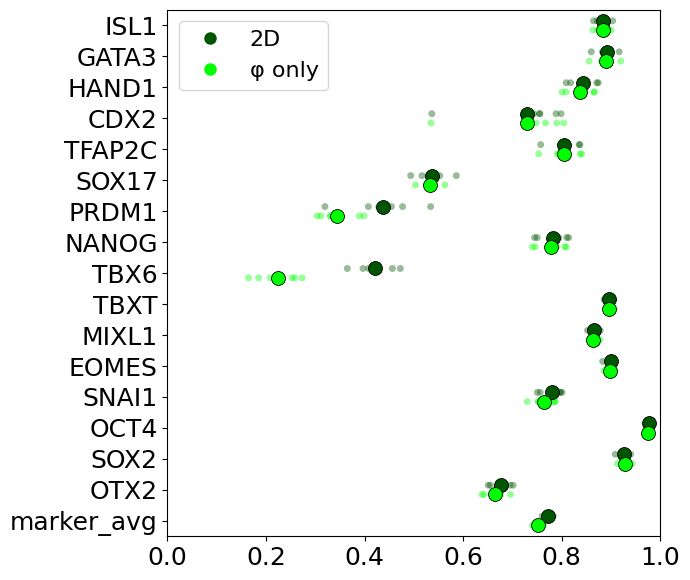

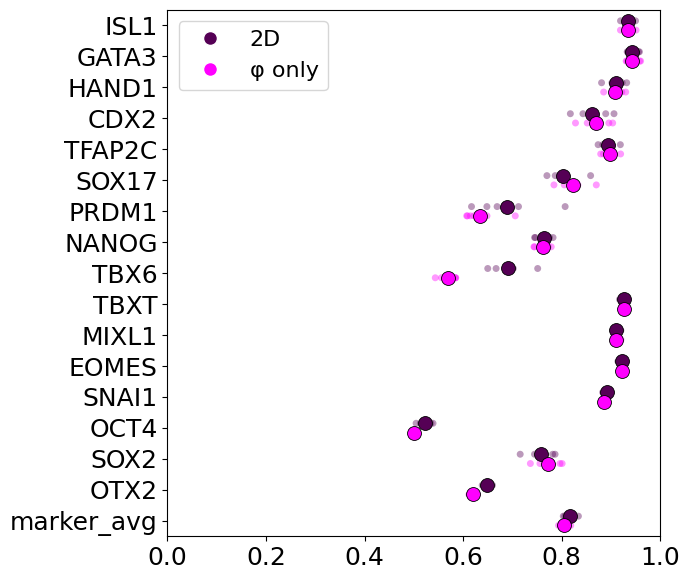

In [486]:
# ============================================================
# PLOT: phi-only vs full, balanced accuracy in place of accuracy
# ============================================================
data_B50 = data[data['condition'] == 'B50']
colonies_B50 = data_B50['Colony'].values

perfold_dfs_compare = {}
for model_key, pred_df_model in [('full', pred_full_wrapped), ('theta_only', pred_theta_wrapped)]:
    pred_sub_model = pred_df_model.loc[data_B50.index]
    perfold_df_model = IIF.compute_marker_performance_perfold(data_B50, pred_sub_model, colonies_B50, gene_names, thresh)
    avg_rows = perfold_df_model.groupby('fold')[['balanced_accuracy', 'f1', 'f1_rand']].mean().reset_index()
    avg_rows['gene'] = 'marker_avg'
    perfold_dfs_compare[model_key] = pd.concat([perfold_df_model, avg_rows], ignore_index=True)

labels = markers + ['marker_avg']
legend_labels = ['2D', 'φ only']

for score, base_color in [('f1', np.array([0, 1, 0])), ('balanced_accuracy', np.array([1, 0, 1]))]:
    color_full = tuple(base_color / 3)   # darker
    color_theta = tuple(base_color / 1)  # lighter
    series = [(perfold_dfs_compare['full'], score, color_full),
              (perfold_dfs_compare['theta_only'], score, color_theta)]
    IIF.plot_perfold_comparison(
        series, 'gene', labels,
        dataDir + f'/FigS7/phi_vs_full_{score}_comparison' + str(len(signals)) + 'D_run' + str(run) + '.png',
        legend_labels=legend_labels)


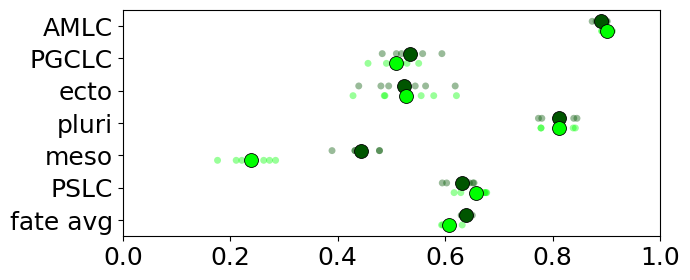

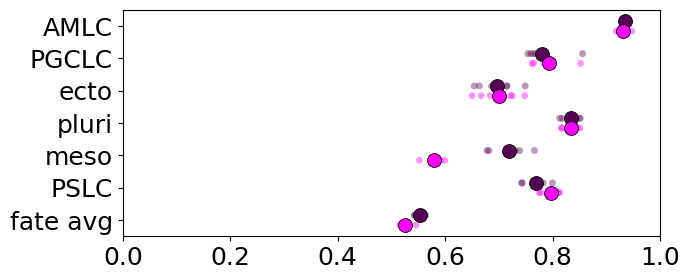

In [488]:
# ============================================================
# PLOT: phi-only vs full - FATE labels, balanced accuracy in place of accuracy
# ============================================================
category_list = ['AMLC', 'PGCLC', 'ecto', 'pluri', 'meso', 'PSLC']  # matches SIX_FATES elsewhere, excludes 'other'

true_labels, _ = IIF.return_fates(data_B50, thresh=thresh)
pred_labels_full, _ = IIF.return_fates(pred_full_wrapped.loc[data_B50.index], thresh=thresh)
pred_labels_theta, _ = IIF.return_fates(pred_theta_wrapped.loc[data_B50.index], thresh=thresh)

fate_perfold = {}
for model_key, pred_labels in [('full', pred_labels_full), ('theta_only', pred_labels_theta)]:
    records = IIF.compute_category_performance_perfold(true_labels, pred_labels, colonies_B50,
                                                         category_list, aggregate_name='all')
    fate_perfold[model_key] = pd.DataFrame(records)

labels = category_list + ['all']
labels_tick = category_list + ['fate avg']

for score, base_color in [('f1', np.array([0, 1, 0])), ('balanced_accuracy', np.array([1, 0, 1]))]:
    color_full = tuple(base_color / 3)
    color_theta = tuple(base_color / 1)
    series = [(fate_perfold['full'], score, color_full),
              (fate_perfold['theta_only'], score, color_theta)]
    IIF.plot_perfold_comparison(
        series, 'category', labels,
        dataDir + f'/FigS7/phi_vs_full_fate_{score}_comparison' + str(len(signals)) + 'D_run' + str(run) + '.png',
         tick_labels=labels_tick)


### 1D latent coordinate

In [407]:
# 1D performance
# run VIB with 6-fold cross-validation for B50 and using all B50 data to predict perturbations

import torch
import warnings
from sklearn.exceptions import InconsistentVersionWarning
import time
import importlib
importlib.reload(IIF)

warnings.filterwarnings("ignore", category=InconsistentVersionWarning)
N_run = 3

feat_names = signals

for Ldim in [1,2]:
    
    for Nlay in [2]:
        
        for Nhid in [32]:
        
            hyperparam = {'HIDDEN_DIM':Nhid, 'N_LAYERS':Nlay, 'LATENT_DIM': Ldim}
            
            for it in range(N_run):
            
                print(f"  Run {it}/{N_run}")
                start = time.time()
                
                pred_df = data.copy()    
                data_cond = data[data['condition']=='B50']
            
                # first predict each colony in B50 based on the other colonies
                
                colony_idx = np.unique(data_cond['Colony'])
                for test_colony in colony_idx:
            
                    print('B50 col: ' + str(test_colony))
                    
                    # split data into test and train by colonies
                    train_colonies = np.setdiff1d(colony_idx, test_colony)
                    data_test = data_cond[data_cond['Colony'].isin([test_colony])]
                    data_train = data_cond[data_cond['Colony'].isin(train_colonies)]
    
                    feat_train = data_train[feat_names] # signal_names[:-1]
                    feat_test = data_test[feat_names]
                    tar_train = data_train[gene_names]
            
                    # run VIB
                    vib1D = IIF.VIB(feat_train, tar_train, hyperparam)
                    _ = vib1D.train(verbose=False)
                    tar_predict = vib1D.predict(feat_test)
                    pred_df.loc[tar_predict.index, tar_predict.columns] = tar_predict
            
                # then predict other conditions based on all B50 colonies
                data_train = data_cond
                feat_train = data_train[feat_names]
                tar_train = data_train[gene_names] 
                vib1D = IIF.VIB(feat_train, tar_train, hyperparam)
                
                for cond in [c for c in conditions if c != 'B50']:
            
                    print(cond)
            
                    data_cond = data[data['condition']==cond]
                    feat_test = data_cond[feat_names]
                    tar_predict = vib1D.predict(feat_test)
                    pred_df.loc[tar_predict.index, tar_predict.columns] = tar_predict
        
                pred_df.to_csv(dataDir + '/VIB_sweep/260307_VIB_' + str(len(feat_names)) + 'D_B50_Nhid' + str(Nhid) + '_Nlay'+ str(hyperparam['N_LAYERS']) + '_Ldim' + str(hyperparam['LATENT_DIM']) +'_run' + str(it) + '.csv')
            
                end = time.time()
                print(f"Elapsed time: {end - start} seconds")

  Run 0/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 18.966472148895264 seconds
  Run 1/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 18.917617321014404 seconds
  Run 2/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 19.002000093460083 seconds
  Run 0/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 18.741620302200317 seconds
  Run 1/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 18.682873964309692 seconds
  Run 2/3
B50 col: 1
B50 col: 2
B50 col: 3
B50 col: 4
B50 col: 5
B50 col: 6
B200
B10
Elapsed time: 18.59348773956299 seconds


In [479]:
# LOAD RUNS FOR HIDDEN_DIM, N_LAYERS, LATENT_DIM OPTIMIZATION FROM CSV 

N_run = 3
feat_names = signals #signal_names

pred_subs = dict()
avg_pred = dict()

for Ldim in [1,2]:
    
    for Nlay in [2]:
        
        for Nhid in [32]:

            hyperparam = {'HIDDEN_DIM':Nhid, 'N_LAYERS':Nlay, 'LATENT_DIM': Ldim}
            
            pred_subs[(Nhid, Nlay, Ldim)] = dict()
            
            for it in range(N_run):
            
                pred_df = pd.read_csv(dataDir + '/VIB_sweep/260307_VIB_' + str(len(feat_names)) + 'D_B50_Nhid' + str(hyperparam['HIDDEN_DIM']) + '_Nlay'+ str(hyperparam['N_LAYERS']) + '_Ldim' + str(hyperparam['LATENT_DIM']) +'_run' + str(it) + '.csv', index_col=0) 
                pred_subs[(Nhid, Nlay, Ldim)][it] = pred_df
        
            # average the runs
            avg_pred = pred_subs[(Nhid, Nlay, Ldim)][0].copy()
            dfs_pred_genes = [df[gene_names] for df in pred_subs[(Nhid, Nlay, Ldim)].values()]
            avg_pred_genes = pd.concat(dfs_pred_genes).groupby(level=0).mean()
            avg_pred[gene_names] = avg_pred_genes
            pred_subs[(Nhid, Nlay, Ldim)]['avg'] = avg_pred

In [228]:
# CALCULATE PERFORMANCE
performances, _ = IIF.calcPerformance(data, pred_subs, thresh, gene_names)

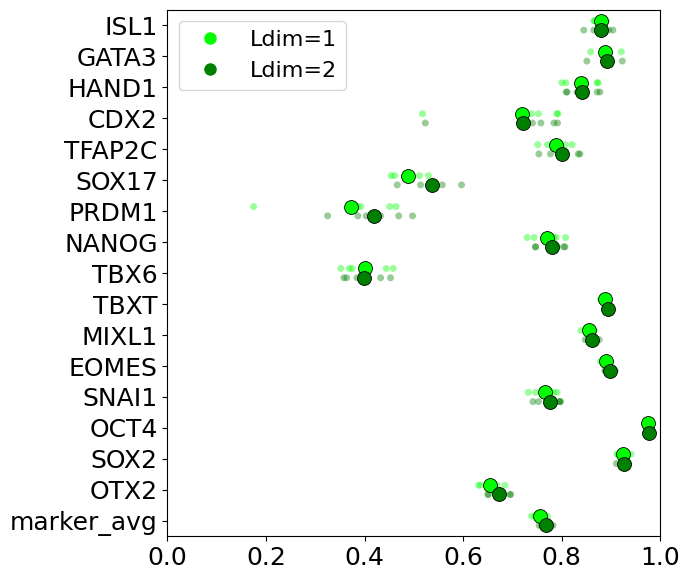

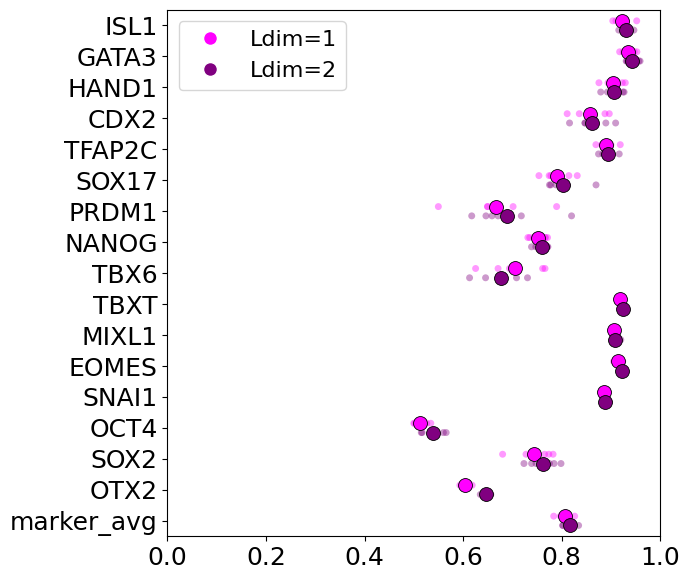

In [483]:
# F1 score and balanced accuracy per marker
data_B50 = data[data['condition'] == 'B50']
colonies_B50 = data_B50['Colony'].values

keys = list(pred_subs.keys())  # [(32, 2, 1), (32, 2, 2)]
perfold_dfs = {}
for k in keys:
    pred_sub_k = pred_subs[k]['avg'].loc[data_B50.index]
    perfold_df_k = IIF.compute_marker_performance_perfold(data_B50, pred_sub_k, colonies_B50, gene_names, thresh)
    avg_rows = perfold_df_k.groupby('fold')[['balanced_accuracy', 'f1', 'f1_rand']].mean().reset_index()
    avg_rows['gene'] = 'marker_avg'
    perfold_dfs[k] = pd.concat([perfold_df_k, avg_rows], ignore_index=True)

labels = markers + ['marker_avg']
legend_labels = [f'Ldim={k[2]}' for k in keys]

for score, colors in [('f1', [(0, 1, 0), (0, 0.5, 0)]),
                       ('balanced_accuracy', [(1, 0, 1), (0.5, 0, 0.5)])]:
    series = [(perfold_dfs[k], score, colors[i]) for i, k in enumerate(keys)]
    IIF.plot_perfold_comparison(series, 'gene', labels,
                                 dataDir + '/FigS7/marker_perf_' + score + '_1Dvs2D.png',
                                 legend_labels=legend_labels)


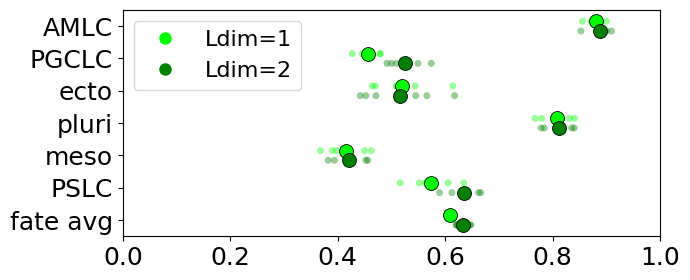

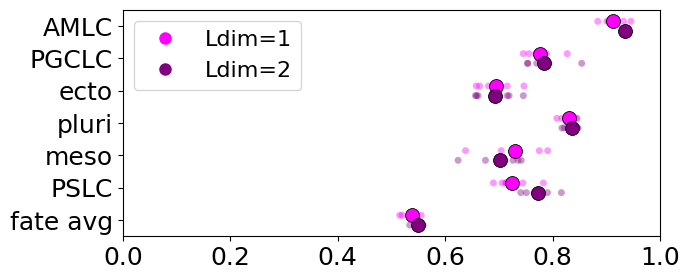

In [489]:
# plot fate f1 and balanced accuracy for Nhid=32, Nlay=2, for different Ldim
Nlay = 2
Nhid = 32
category_list = ['AMLC', 'PGCLC', 'ecto', 'pluri', 'meso', 'PSLC']

true_labels, _ = IIF.return_fates(data_B50, thresh=thresh)

fate_perfold_ldim = {}
for Ldim in [1, 2]:
    k = (Nhid, Nlay, Ldim)
    pred_sub_k = pred_subs[k]['avg'].loc[data_B50.index]
    pred_labels_k, _ = IIF.return_fates(pred_sub_k, thresh=thresh)
    records = IIF.compute_category_performance_perfold(true_labels, pred_labels_k, colonies_B50,
                                                         category_list, aggregate_name='all')
    fate_perfold_ldim[Ldim] = pd.DataFrame(records)

labels = category_list + ['all']
labels_tick = category_list + ['fate avg']
legend_labels = [f'Ldim={Ldim}' for Ldim in [1, 2]]

for score, base_color in [('f1', np.array([0, 1, 0])), ('balanced_accuracy', np.array([1, 0, 1]))]:
    colors = [tuple(base_color / Ldim) for Ldim in [1, 2]]
    series = [(fate_perfold_ldim[Ldim], score, colors[i]) for i, Ldim in enumerate([1, 2])]
    IIF.plot_perfold_comparison(
        series, 'category', labels,
        dataDir + f'/FigS7/fate_perf_{score}_1Dvs2D.png',
        legend_labels=legend_labels, tick_labels=labels_tick)


In [408]:
# GET THE 1D model trained on the full data
N_run = 5
hyperparam = {'HIDDEN_DIM':32, 'N_LAYERS':2, 'LATENT_DIM': 1}
genes = gene_names

vib1D = {}

cond = 'B50'
data_cond = data[data['condition']==cond]

feat_train = data_cond[signals] 
tar_train = data_cond[gene_names]

for run in range(0,N_run):
    
    vib1D[run] = IIF.VIB(feat_train, tar_train, hyperparam)
    if not os.path.exists(dataDir + '/model_'+str(run)+ '_' + str(len(signals)) + 'D' + '_Ldim1.pth'):
        print('run VIB')
        _ = vib1D[run].train(verbose=False)
        torch.save(vib1D[run].model, dataDir + '/model_'+str(run)+ '_' + str(len(signals)) + 'D' + '_Ldim1.pth')
    else: 
        print('load VIB')
        vib1D[run].model = torch.load(dataDir + '/model_'+str(run)+ '_' + str(len(signals)) + 'D' + '_Ldim1.pth', weights_only=False)

run VIB
run VIB
run VIB
run VIB
run VIB


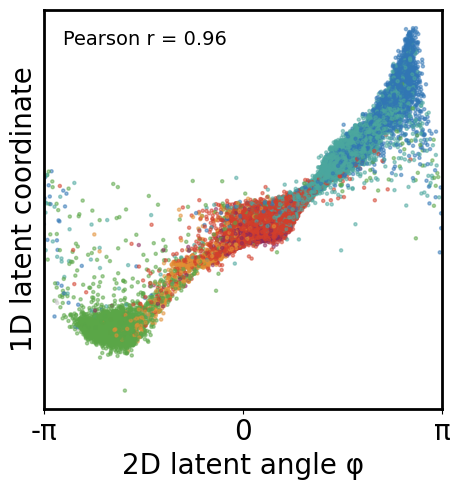

In [429]:
# ============================================================
# PLOT: 1D latent coordinate vs 2D polar angle (theta)
# ============================================================

run = 4  # or whichever run you want
mask = (data['condition'] == cond)

# --- encode with 1D model ---
model1D = vib1D[run].model
X = vib1D[run].scaler_X_run.transform(data.loc[mask, signals])
X = torch.FloatTensor(X).to(device)

model1D.eval()
with torch.no_grad():
    mu1D, _ = model1D.encode(X)
    L1D = mu1D[:, 0].cpu().numpy()

# standardize for plotting
L1D_scaled = (L1D - L1D.mean()) / L1D.std()

# ============================================================
# color by fate
# ============================================================

fates_data, _ = IIF.return_fates(data[mask], thresh=thresh)
colors = [IIF.colmap_fates[f] for f in fates_data]

fs = 20
sw = 2
s = 5
alpha = 0.5

fig, ax = plt.subplots(figsize=(5, 5))

ax.scatter(theta_corrected, L1D_scaled, c=colors, s=s, alpha=alpha)

r, p = sp.stats.pearsonr(theta_corrected, L1D_scaled)
#print(f'Pearson r = {r:.3f}, p = {p:.3e}')
ax.text(0.05, 0.95, f'Pearson r = {r:.2f}',
        transform=ax.transAxes, fontsize=fs-6,
        va='top', ha='left')
        #bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('2D latent angle φ', fontsize=fs)
ax.set_ylabel('1D latent coordinate', fontsize=fs)
ax.set_xticks([-np.pi, 0, np.pi])
ax.set_xlim([-np.pi, np.pi])
ax.set_xticklabels(['-π', '0', 'π'], fontsize=fs)
ax.set_yticks([])
ax.tick_params(labelsize=fs)
ax.set_box_aspect(1)


for spine in ax.spines.values():
    spine.set_linewidth(sw)

plt.tight_layout()
plt.savefig(dataDir+'/FigS7/1D_vs_2D_angle_' + str(len(signals)) + 'D_run' + str(run) + '.png', dpi=150)
plt.show()


### Fatebar vs polar coordinates 

In [430]:
labels, names = IIF.return_fates(data, thresh=thresh)
np.unique(labels)

array(['AMLC', 'PGCLC', 'PSLC', 'ecto', 'meso', 'other', 'pluri'],
      dtype='<U5')

In [431]:
data['threshold_clusters'], _ = IIF.return_fates(data, thresh=thresh)

In [454]:
# get latent coordinates for all cells across conditions
run = 3

mask_B50 = data['condition'] == 'B50'
mu_fit = get_latent(vib[run], data.loc[mask_B50, signals])
L_scaled_fit = np.column_stack([
    (L_aligned[run][:, 0] - L1mean) / L1std,
    (L_aligned[run][:, 1] - L2mean) / L1std,
])
A_fit = np.hstack([mu_fit, np.ones((mu_fit.shape[0], 1))])
M_b, *_ = np.linalg.lstsq(A_fit, L_scaled_fit, rcond=None)
M, b = M_b[:2], M_b[2]
M_inv = np.linalg.inv(M)


# encode ALL cells (every condition, not just B50) through the same affine transform
X = vib[run].scaler_X_run.transform(data[signals])
X = torch.FloatTensor(X).to(device)

model = vib[run].model
model.eval()
with torch.no_grad():
    mu, _ = model.encode(X)

L_scaled_all = mu.cpu().numpy() @ M + b
L1_scaled_all = L_scaled_all[:, 0]
L2_scaled_all = L_scaled_all[:, 1]

# these are named _all and only written into data['L_theta']/data['L_r'] below --
# NOT overwriting the plain theta_corrected/r globals, which are B50-scoped (length
# 30427) and used by several other cells in this section (the 1D-coordinate panel,
# cell 91's angle/radius plots) -- overwriting them with the all-conditions (length
# 84395) versions breaks those cells with a shape-mismatch error
x_centered_all = L1_scaled_all - center_x
y_centered_all = L2_scaled_all - center_y
r_all = np.sqrt(x_centered_all**2 + y_centered_all**2)
theta_raw_all = np.arctan2(y_centered_all, x_centered_all)

theta_corrected_all = -(theta_raw_all - gap_angle + np.pi)
theta_corrected_all = np.arctan2(np.sin(theta_corrected_all), np.cos(theta_corrected_all))

data['L_theta'] = theta_corrected_all
data['L_r'] = r_all


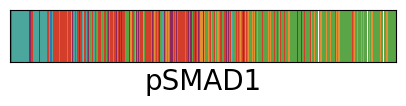

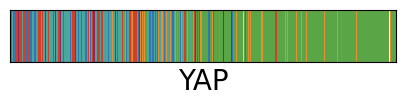

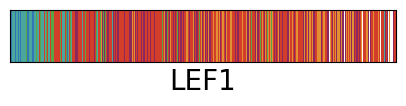

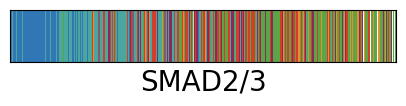

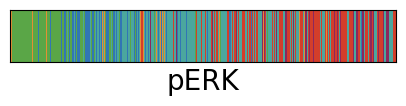

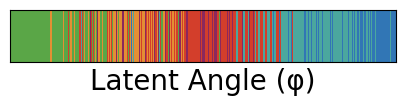

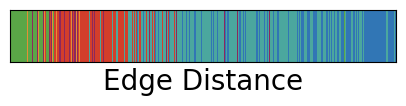

In [448]:
n_bins = 450  # Changed from bin_num
fs = 20

data_cond = data[data['condition']==cond]
labels = [clean_signal_names[s] for s in signals]+['Latent Angle (φ)', 'Edge Distance']

for i,sig in enumerate(signals+['L_theta', 'MetricDist']):
    
    # Define percentile limits
    lower_percentile = 1  
    upper_percentile = 99
    
    # Get the actual values at these percentiles
    lower_limit = data[sig].quantile(lower_percentile / 100)
    upper_limit = data[sig].quantile(upper_percentile / 100)
    
    # Filter data to this range
    data_filtered = data_cond[(data_cond[sig] >= lower_limit) & (data_cond[sig] <= upper_limit)].copy()
    
    # Create bins for the r coordinate on filtered data
    data_filtered['r_bin'] = pd.cut(data_filtered[sig], bins=n_bins, labels=False)
    
    # Sample one cell from each bin - keep the bin info
    sampled_cells = []
    for bin_idx in range(n_bins):  # Changed variable name
        bin_data = data_filtered[data_filtered['r_bin'] == bin_idx]
        if len(bin_data) > 0:
            sample = bin_data.sample(n=1, random_state=1)
            sampled_cells.append({
                'bin': bin_idx,
                'threshold_clusters': sample['threshold_clusters'].iloc[0]
            })
    
    sampled_df = pd.DataFrame(sampled_cells)
    
    # Plot the bar
    fig, ax = plt.subplots(figsize=(4, 1))
    
    for _, row in sampled_df.iterrows():
        ax.barh(0, 1, left=row['bin'], height=1, color=IIF.colmap_fates[row['threshold_clusters']])
    
    # Formatting
    ax.set_xlim(0, n_bins)
    ax.set_ylim(-0.5, 0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(labels[i], fontsize=fs)
    plt.tight_layout(pad=0.5)

    if sig=='L_theta':
        plt.savefig(dataDir+'/Fig3/barplot_fate_'+ sig+ '_' + str(len(signals)) + 'D' + '_run' + str(run)  + '.png')
    elif sig in ['pSMAD1', 'cytopERK', 'MetricDist']:
        plt.savefig(dataDir+'/Fig3/barplot_fate_'+sig+'.png')
    else:
        plt.savefig(dataDir+'/FigS7/barplot_fate_'+sig+'.png')
    plt.show()
    plt.close()

### Relate latent polar coordinates to signals

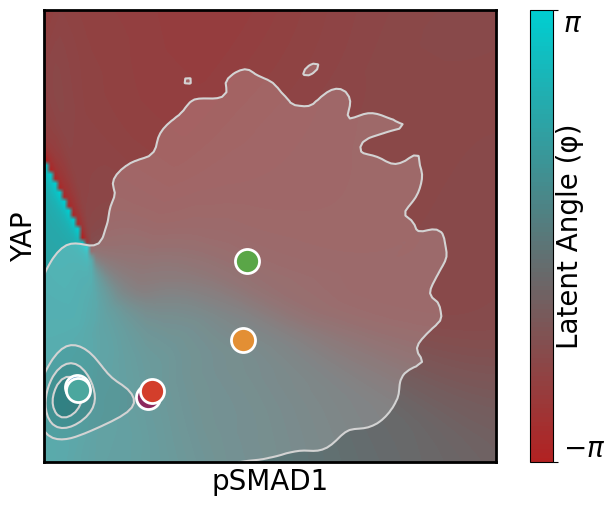

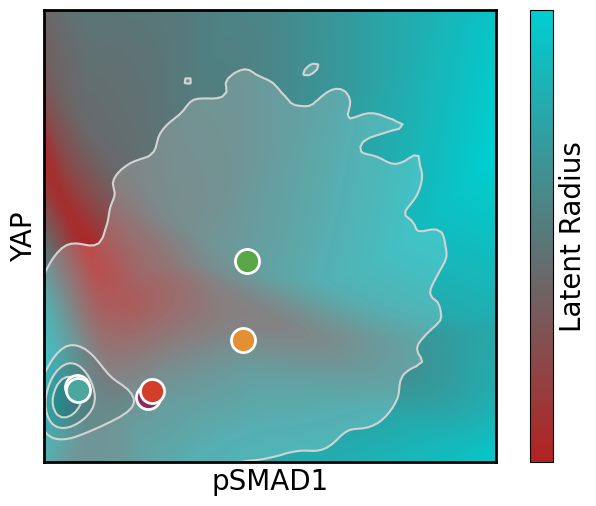

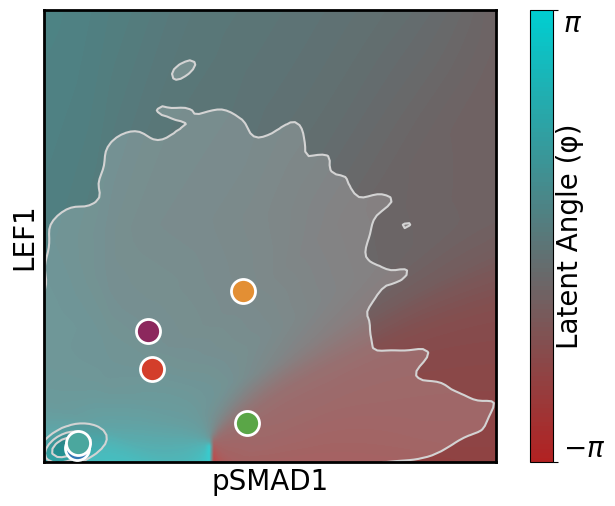

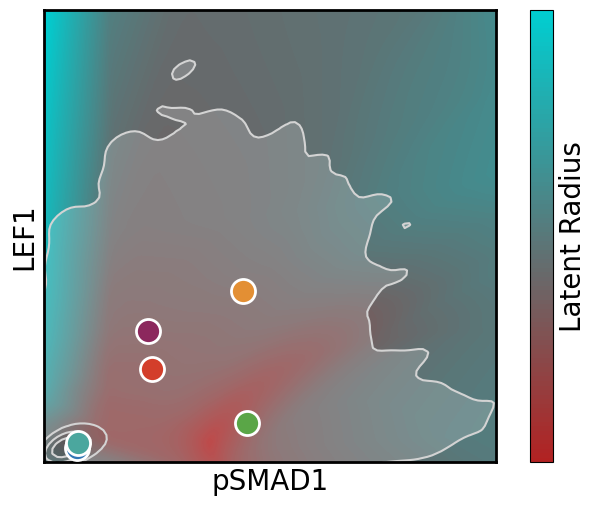

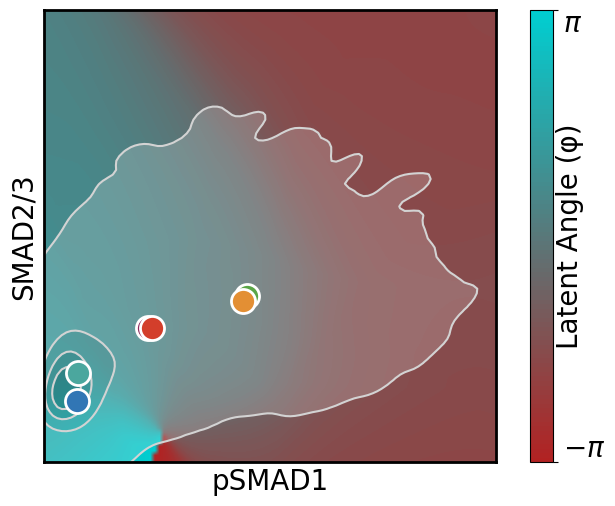

...

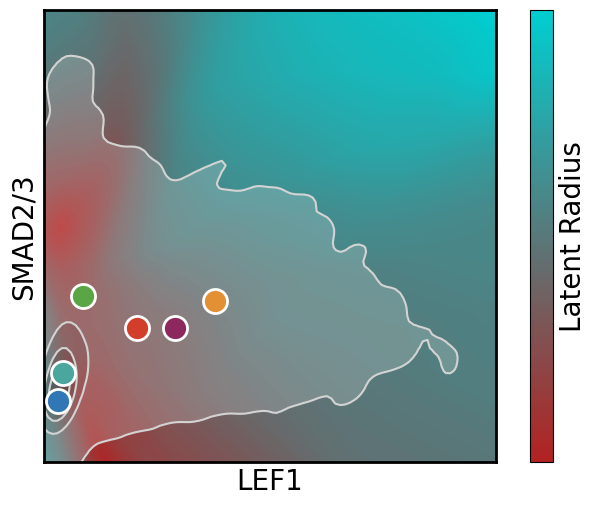

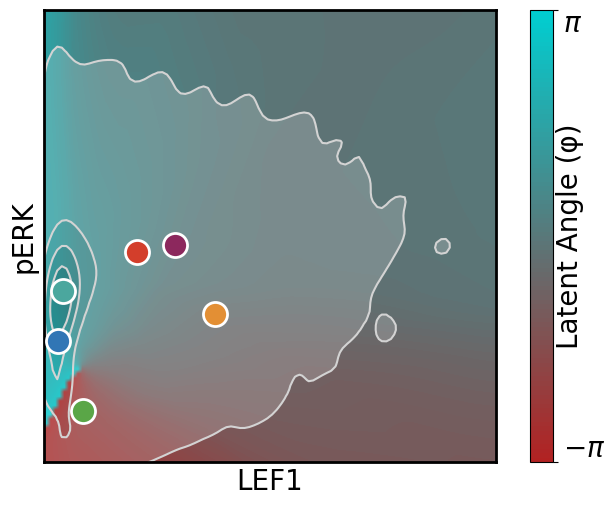

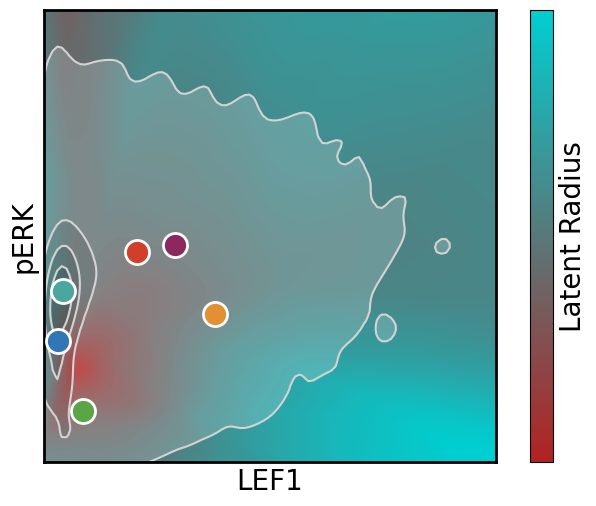

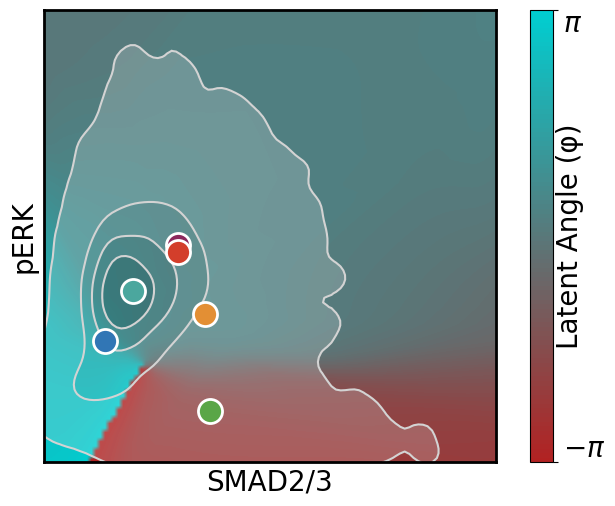

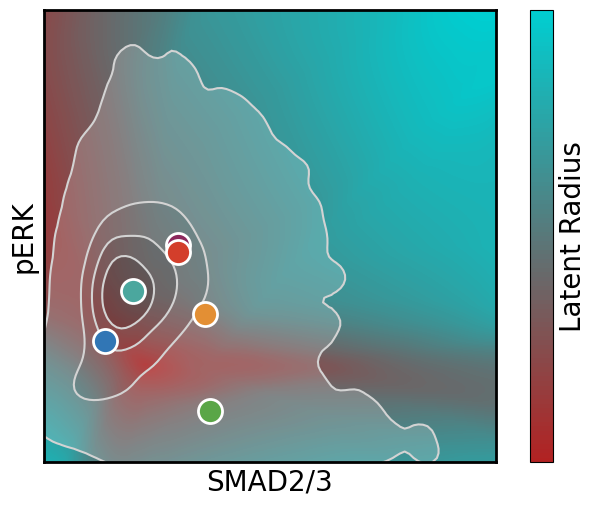

In [451]:
# calculate a smoothened average of the holdout signals over the signaling grid

# signalcombos = [('pSMAD1','ncYAP'), ('pSMAD1','LEF1'), ('pSMAD1','BCat'),('pSMAD1','ncSMAD23'),  ('pSMAD1','cytopERK'), 
#                 ('ncYAP', 'LEF1'), ('ncYAP', 'BCat'), ('ncYAP', 'ncSMAD23'), ('ncYAP', 'cytopERK'),
#                 ('LEF1','BCat'), ('LEF1','ncSMAD23'), ('LEF1','cytopERK'),
#                 ('BCat','ncSMAD23'), ('BCat','cytopERK'),
#                 ('ncSMAD23','cytopERK')]

signalcombos = [('pSMAD1','ncYAP'), ('pSMAD1','LEF1'), ('pSMAD1','ncSMAD23'),  ('pSMAD1','cytopERK'), 
                ('ncYAP', 'LEF1'), ('ncYAP', 'ncSMAD23'), ('ncYAP', 'cytopERK'),
                ('LEF1','ncSMAD23'), ('LEF1','cytopERK'),
                ('ncSMAD23','cytopERK')]

for (sig_i, sig_j) in signalcombos:

    n_bins = 100
    bandwidth = None
    mask = data['condition']=='B50'
    n_signals = len(signals)
    
    # Get signal ranges (use percentiles to avoid outliers)
    x_min, x_max = np.percentile(data.loc[mask,sig_i], [0.1, 99.9])
    y_min, y_max = np.percentile(data.loc[mask,sig_j], [0.1, 99.9])
    
    # Create grid
    x_grid = np.linspace(x_min, x_max, n_bins)
    y_grid = np.linspace(y_min, y_max, n_bins)
    
    # Compute adaptive bandwidth if not provided
    if bandwidth is None:
        # Use ~10% of the data range as bandwidth
        bandwidth_x = (x_max - x_min) / 10
        bandwidth_y = (y_max - y_min) / 10
    else:
        bandwidth_x = bandwidth_y = bandwidth
    
    # Holdout signal indices
    holdout_sigs = [s for s in signals if s not in (sig_i, sig_j)]
    
    # Extract holdout columns - ensure numeric
    X_holdout = data.loc[:, holdout_sigs].values
    
    # Precompute for efficiency
    X_sig_i = data[sig_i].values
    X_sig_j = data[sig_j].values
    
    grids = {}
    for sig in signals:
        grids[sig] = np.zeros((n_bins, n_bins))
    
    # For each grid point, interpolate holdout signals and compute L
    for i, x_val in enumerate(x_grid):
        for j, y_val in enumerate(y_grid):
            
            # Gaussian kernel weights
            dist_sq = ((X_sig_i - x_val) / bandwidth_x)**2 + ((X_sig_j - y_val) / bandwidth_y)**2
            weights = np.exp(-0.5 * dist_sq)
            weight_sum = weights.sum()
            
            # Skip if no data nearby
            if weight_sum < 1e-10:
                continue
            
            # Normalize weights
            weights = weights / weight_sum
            
            # Interpolate holdout signals (Nadaraya-Watson estimator)
            holdout_interp = (weights[:, np.newaxis] * X_holdout).sum(axis=0)
            
            # Construct full signal vector
            grids[sig_i][j,i] = x_val
            grids[sig_j][j,i] = y_val
            for k, hs in enumerate(holdout_sigs):
                grids[hs][j,i] = holdout_interp[k]

    #-----------------------------------------------------------------------------
    # feed the signaling grids into Sig2Fate to get latent coordinates
    siggrids = pd.DataFrame({key: grid.ravel() for key, grid in grids.items()})

    X = vib[run].scaler_X_run.transform(siggrids)
    X = torch.FloatTensor(X).to(device)

    model = vib[run].model
    model.eval()
    with torch.no_grad():
        mu, _ = model.encode(X)

    L_scaled_grid = mu.cpu().numpy() @ M + b
    L1_scaled = L_scaled_grid[:, 0].reshape(n_bins, n_bins)
    L2_scaled = L_scaled_grid[:, 1].reshape(n_bins, n_bins)

    #--------COMPUTE KDE OF DATA --------------
    
    # Create KDE in corrected polar space
    mask = data['condition']=='B50'
    values = data.loc[mask, [sig_i, sig_j]]
    kernel = sp.stats.gaussian_kde(values.T)#, bw_method=0.2)
    
    # Evaluate KDE at the actual data points (transpose needed!)
    kde_at_data = kernel(values.T)
 
    # Set vmin so that X% of data points are outside the contours
    data_percentile = 1  # Change this: 10 means 10% of data outside, 90% inside
    vmin = np.percentile(kde_at_data, data_percentile)
    
    # Evaluate KDE on the grid
    kde_grid = kernel(np.vstack([siggrids[sig_i], siggrids[sig_j]]))
    kde_grid = kde_grid.reshape(grids[sig_i].shape)  # Fixed: use .shape instead of .ravel()
    
    # Define contour levels from vmin to max
    vmax = kde_grid.max()
    levels = np.linspace(vmin, vmax, 5)
    
    # # Verify
    # fraction_inside = np.sum(kde_at_data >= vmin) / len(kde_at_data)  # Fixed: use len(kde_at_data)
    # print(f"{fraction_inside*100:.1f}% of data points are inside the contours")
    
    #--------------Compute  polar coordinates---------------
    x_centered = L1_scaled - center_x
    y_centered = L2_scaled - center_y
    r = np.sqrt(x_centered**2 + y_centered**2)
    theta_raw = np.arctan2(y_centered, x_centered)
    
    # Rotate angles so the gap is at ±π and reverse direction
    theta_corrected = -(theta_raw - gap_angle + np.pi)
    # Wrap to [-π, π]
    theta_corrected = np.arctan2(np.sin(theta_corrected), np.cos(theta_corrected))
    
    #---------------compute mean position of each fate---------------
    
    fates, fate_names = IIF.return_fates(data, thresh=thresh)
    fatemean = {}
    
    for f in fate_names:
        mask = (data['condition']=='B50') & (fates==f)
        fatemean[f] = data.loc[mask, [sig_i, sig_j]].mean()
    
    #--------------PLOT---------------
    
    for k, colorfor in {'theta':theta_corrected, 'r':r}.items():
        
        fig, ax = plt.subplots(1,1,figsize=(7,5))
        
        # Plot heatmap using imshow for smooth appearance
        extent = [x_grid[0], x_grid[-1], y_grid[0], y_grid[-1]]
        if k == 'theta':
            vmin = -np.pi
            vmax = np.pi
        elif k=='r':
            vmin = 0
            vmax = r.max()
            
        im = ax.imshow(colorfor, origin='lower', extent=extent, aspect='auto', cmap=cmap, interpolation='bilinear', vmin=vmin, vmax=vmax)
    
        # Add KDE contours
        ax.contourf(grids[sig_i], grids[sig_j], kde_grid, levels=levels, cmap='Greys', alpha=0.2)
        ax.contour(grids[sig_i], grids[sig_j], kde_grid, levels=levels, colors='lightgray', linewidths=1.5)
    
        for f in fate_names[:-1]: #-1 to remove other
            ax.scatter(fatemean[f][sig_i],fatemean[f][sig_j],color=IIF.colmap_fates[f], zorder=3, s=300, edgecolors='white',linewidths=2)
        
        ax.set_xlabel(clean_signal_names[sig_i], fontsize=fs)
        ax.set_ylabel(clean_signal_names[sig_j], fontsize=fs)
        ax.set_xticks([])
        ax.set_yticks([])
        cbar = fig.colorbar(im, ax=ax)
        
        if k=='theta':
            cbar.set_ticks([-np.pi, np.pi])
            cbar.set_ticklabels([r'$-\pi$', r'$\pi$'], fontsize=fs)
            cbar.set_label('Latent Angle (φ)', fontsize=fs, rotation=90, labelpad=-35)
            tick_labels = cbar.ax.get_yticklabels()
            tick_labels[0].set_verticalalignment('bottom')
            tick_labels[1].set_verticalalignment('top')
        elif k=='r':
            cbar.set_ticks([])
            cbar.set_label('Latent Radius', fontsize=fs, rotation=90)
        
        ax.set_box_aspect(1)
        for spine in ax.spines.values():
            spine.set_linewidth(sw)
    
        plt.tight_layout(pad=0.5)
        if ((sig_i, sig_j) in [('pSMAD1','cytopERK'), ('ncYAP', 'LEF1')]) and k=='theta':
            plt.savefig(dataDir+'/Fig3/LS_'+k+'_'+sig_i+'_'+sig_j+'_heatmap_' + str(len(signals)) + 'D_run' + str(run) + '.png')

        plt.savefig(dataDir+'/FigS7/LS_'+k+'_'+sig_i+'_'+sig_j+'_heatmap_' + str(len(signals)) + 'D_run' + str(run) + '.png')
        plt.show()
        plt.close()